# AWS pilot — hanging-sphere convergence, QuESo-256 reference

**Purpose:** a resumable two-GPU pilot with a clean separation between stiffness (`K`) timing and CG timing.

- Reference: **QuESo 256³**
- Target observed orders: **naive ≈ 1.2**, **weighted ≈ 1.5**, **QuESo ≈ 2.0**, **NN ≈ 2.0**
- `K_total_seconds` = framework input preparation + stiffness construction only.
- CG is timed separately.
- The runner writes timing after every framework and continues after failures, so a failed 128³ case cannot silently terminate the whole ladder.


In [2]:
from pathlib import Path

# Edit this cell, then run the notebook from top to bottom.
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "clean_simulation").is_dir():
    raise RuntimeError(f"Could not find the repository root from {Path.cwd().resolve()}.")

SSH_KEY = Path.home() / ".ssh" / "ibm_learning.pem"
SSH_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
REMOTE_REPO_ROOT = "~/cutcell-training"
REMOTE_RUN_DIR = f"{REMOTE_REPO_ROOT}/aws_pilot_512"
REMOTE_PYTHON = f"{REMOTE_REPO_ROOT}/.venv/bin/python"

# V5 matches the known-good local surface and solver semantics.
RUN_TAG = "aws_convergence_clean_v5"
REMOTE_OUTPUT_DIR = f"{REMOTE_REPO_ROOT}/clean_simulation/outputs/{RUN_TAG}"
LOCAL_RESULTS_DIR = ROOT / "notebooks" / RUN_TAG
LOCAL_SCRATCH = ROOT / "notebooks" / "aws_pilot_scratch"

REFERENCE_RESOLUTION = 256
RESOLUTIONS = (8, 16, 32, 64, 128, 256)
FRAMEWORKS = ("naive", "weighted", "queso", "nn")
SUPPORT_MODE = "smooth_foundation"
ELEMENT_BATCH_SIZE = 32_768
CG_MAX_ITER = 12_000
SOLVE_DTYPE = "float64"
CG_RTOL = "1e-9"
SURFACE_SUBDIVISIONS = 9

# Only the QuESo reference is required at 256^3.
JOBS = {
    "gpu0_ladder": {"cuda_device": "0", "resolutions": (8, 16, 32, 64, 128), "frameworks": FRAMEWORKS},
    "gpu1_reference": {"cuda_device": "1", "resolutions": (256,), "frameworks": ("queso",)},
}

if not SSH_KEY.is_file():
    raise FileNotFoundError(f"SSH key not found: {SSH_KEY}")
LOCAL_SCRATCH.mkdir(parents=True, exist_ok=True)
LOCAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration")
print("  repository:", ROOT)
print("  run tag:   ", RUN_TAG)
print("  results:   ", LOCAL_RESULTS_DIR)
print("  jobs:      ", JOBS)

Configuration
  repository: C:\Users\z0058p1u\Documents\code
  run tag:    aws_convergence_clean_v5
  results:    C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5
  jobs:       {'gpu0_ladder': {'cuda_device': '0', 'resolutions': (8, 16, 32, 64, 128), 'frameworks': ('naive', 'weighted', 'queso', 'nn')}, 'gpu1_reference': {'cuda_device': '1', 'resolutions': (256,), 'frameworks': ('queso',)}}


In [3]:
import subprocess

def run_remote(command, check=True, timeout=60):
    """
    Reliable SSH wrapper for Windows.
    Forces non-interactive SSH and prevents stdin/pipe hangs.
    """
    cmd = [
        "ssh",
        "-o", "BatchMode=yes",
        "-o", "ConnectTimeout=10",
        "-o", "ServerAliveInterval=5",
        "-o", "ServerAliveCountMax=2",
        "-i", str(SSH_KEY),
        SSH_HOST,
        command,
    ]

    try:
        result = subprocess.run(
            cmd,
            stdin=subprocess.DEVNULL,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            text=True,
            timeout=timeout,
        )
    except subprocess.TimeoutExpired:
        raise RuntimeError(
            f"SSH connection/command timed out after {timeout}s.\n"
            f"Host: {SSH_HOST}\n"
            f"Command: {command}"
        )

    if result.stdout:
        print(result.stdout)

    if result.stderr:
        print("[stderr]", result.stderr)

    if check and result.returncode != 0:
        raise RuntimeError(
            f"Remote command failed (exit {result.returncode}): {command}\n"
            f"{result.stderr}"
        )

    return result.returncode, result.stdout, result.stderr

def copy_to_remote(local_path, remote_path):
    subprocess.run(
        ["scp", "-i", str(SSH_KEY), str(local_path), f"{SSH_HOST}:{remote_path}"],
        check=True,
    )

def copy_dir_from_remote(remote_path, local_path):
    Path(local_path).mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["scp", "-i", str(SSH_KEY), "-r", f"{SSH_HOST}:{remote_path}", str(local_path)],
        check=True,
    )

run_remote("pwd && nvidia-smi --query-gpu=index,name,driver_version,memory.total --format=csv")


/home/ubuntu
index, name, driver_version, memory.total [MiB]
0, NVIDIA RTX PRO 6000 Blackwell Server Edition, 595.71.05, 97887 MiB
1, NVIDIA RTX PRO 6000 Blackwell Server Edition, 595.71.05, 97887 MiB



(0,
 '/home/ubuntu\nindex, name, driver_version, memory.total [MiB]\n0, NVIDIA RTX PRO 6000 Blackwell Server Edition, 595.71.05, 97887 MiB\n1, NVIDIA RTX PRO 6000 Blackwell Server Edition, 595.71.05, 97887 MiB\n',
 '')

In [112]:
RUN_STUDY_PY = r'''

#!/usr/bin/env python3
"""Headless, env-var-driven runner for the hanging-sphere cut-cell convergence study.

This reconstructs the canonical (non-exploratory) cell sequence of
05_local_stiffness_convergence.ipynb -- cells 1, 3, 4, 5, 6, 7, 8, 9, 11, 12 --
as a plain script so it can run unattended on a remote GPU box, and adds
per-solve wall-clock timing that is written incrementally to a CSV so you can
watch progress and pull back timing even from a job that is still running or
that failed partway through.

Designed to be launched twice, once per GPU, e.g.:

    CUDA_VISIBLE_DEVICES=0 HANGING_SPHERE_RESOLUTIONS=512 \
        HANGING_SPHERE_REFERENCE_RESOLUTION=512 python3 run_study.py

    CUDA_VISIBLE_DEVICES=1 HANGING_SPHERE_RESOLUTIONS=8,16,32,64,128,256 \
        HANGING_SPHERE_REFERENCE_RESOLUTION=512 python3 run_study.py

Every environment variable from the original notebook is honored
(HANGING_SPHERE_*). A few new ones were added for the remote/512 run --
search for "NEW:" below.
"""
from __future__ import annotations

import csv
import gc
import json
import os
import sys
import time
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import torch


def log(message, started_at=None):
    elapsed = '' if started_at is None else f' [{time.perf_counter() - started_at:.1f}s]'
    stamp = time.strftime('%Y-%m-%d %H:%M:%S')
    print(f'[{stamp}] [hanging-sphere] {message}{elapsed}', flush=True)


# --------------------------------------------------------------------------
# Cell 1 + Cell 4: paths, resolution schedule, reference resolution
# --------------------------------------------------------------------------
root = Path.cwd().resolve()
while root != root.parent and not (root / 'clean_simulation').exists():
    root = root.parent
if not (root / 'clean_simulation').exists():
    raise RuntimeError('Run this script from the repository root or a descendant directory.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

SUPPORT_OUTPUT_NAMES = {'planar_cap': 'planar_cap_plane_hard_constraints', 'smooth_foundation': 'smooth_foundation'}
OUTPUT_DIR = Path(os.environ.get(
    'HANGING_SPHERE_OUTPUT_DIR',
    root / 'clean_simulation' / 'outputs' / 'sphere_displacement_convergence_aws_512',
)).expanduser().resolve()
SUPPORT_MODE = os.environ.get('HANGING_SPHERE_SUPPORT_MODE', 'smooth_foundation').strip().lower()
if SUPPORT_MODE not in SUPPORT_OUTPUT_NAMES:
    raise ValueError(f'Unknown HANGING_SPHERE_SUPPORT_MODE={SUPPORT_MODE!r}.')
SUPPORT_OUTPUT_DIR = OUTPUT_DIR / SUPPORT_OUTPUT_NAMES[SUPPORT_MODE]
PLANAR_CAP_OUTPUT_DIR = OUTPUT_DIR / SUPPORT_OUTPUT_NAMES['planar_cap']
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUPPORT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLANAR_CAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESOLUTION_SCHEDULE = tuple(int(value) for value in os.environ.get(
    'HANGING_SPHERE_RESOLUTIONS', '4,8,16,32,64,128,256',
).split(','))
REFERENCE_RESOLUTION = int(os.environ.get(
    'HANGING_SPHERE_REFERENCE_RESOLUTION', str(max(RESOLUTION_SCHEDULE)),
))
# NEW: reference resolution need not be part of THIS process's own schedule
# (e.g. the GPU-1 "rest of the schedule" job references 512 without solving it).
DRY_RUN = os.environ.get('HANGING_SPHERE_DRY_RUN', '0') == '1'
CONTINUE_ON_ERROR = os.environ.get('HANGING_SPHERE_CONTINUE_ON_ERROR', '1') == '1'
ELEMENT_BATCH_SIZE = int(os.environ.get('HANGING_SPHERE_ELEMENT_BATCH_SIZE', '262144'))

log(f'Output directory: {OUTPUT_DIR}')
log(f'Resolution schedule for this process: {RESOLUTION_SCHEDULE}; reference: {REFERENCE_RESOLUTION}^3')
log(f'Support mode: {SUPPORT_MODE}; dry run: {DRY_RUN}; element batch size: {ELEMENT_BATCH_SIZE}')

# --------------------------------------------------------------------------
# Cell 3: runtime / solver configuration
# --------------------------------------------------------------------------
SOLVE_DEVICE = os.environ.get('HANGING_SPHERE_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu')
CPU_THREADS = int(os.environ.get('HANGING_SPHERE_CPU_THREADS', min(6, os.cpu_count() or 1)))
CG_MAX_ITER = int(os.environ.get('HANGING_SPHERE_CG_MAX_ITER', '4000'))
SOLVE_DTYPE = getattr(torch, os.environ.get('HANGING_SPHERE_DTYPE', 'float32'))
if SOLVE_DEVICE == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('HANGING_SPHERE_DEVICE=cuda was requested but CUDA is unavailable.')
torch.set_num_threads(CPU_THREADS)
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

queso_python_path = root / 'QuESo' / 'out' / 'install' / ('win' if os.name == 'nt' else 'linux')
if queso_python_path.exists() and str(queso_python_path) not in sys.path:
    sys.path.insert(0, str(queso_python_path))

from clean_simulation.bootstrap import configure_legacy_imports
configure_legacy_imports(root)
from clean_simulation.case import build_case_from_stl
from clean_simulation.internal_fem_kernel.runtime.assembly_ops import assemble_force_base
from clean_simulation.internal_fem_kernel.runtime.matrix_free import (
    StructuredCompressedMatrixFreeElasticityOperator,
    solve_matrix_free_cg,
)
from clean_simulation.internal_nn_runtime.cutcell_bridge import compute_nn_cutcell_stiffness, prepare_nn_inputs
from clean_simulation.nn_runtime import load_nn_engine
from internal_fem_kernel.assembly.stiffness import StiffnessAssembly
from internal_fem_kernel.core.grid_indexing import active_element_nodes

ALL_FRAMEWORKS = {
    'naive': 'Naive full-cell Gauss',
    'weighted': 'Geometric-volume-fraction weighted Gauss',
    'queso': 'QuESo quadrature',
    'nn': 'NN-cut-cell hybrid',
}
requested_frameworks = tuple(name.strip() for name in os.environ.get(
    'HANGING_SPHERE_FRAMEWORKS', ','.join(ALL_FRAMEWORKS),
).split(',') if name.strip())
unknown_frameworks = set(requested_frameworks) - set(ALL_FRAMEWORKS)
if unknown_frameworks or not requested_frameworks:
    raise ValueError(f'Invalid HANGING_SPHERE_FRAMEWORKS: {requested_frameworks}')
FRAMEWORKS = {name: ALL_FRAMEWORKS[name] for name in requested_frameworks}
NN_CHECKPOINT = Path(os.environ.get(
    'HANGING_SPHERE_NN_CHECKPOINT',
    root / 'clean_simulation' / 'outputs' / 'checkpoints' / 'source_sdf_rebuilt_queso_d10_f1024_all_crystals_10h.pt',
))
SPHERE_OVERRIDES = {
    'grid': {'bounds': [[-9.0, -9.0, -9.0], [9.0, 9.0, 9.0]]},
    'material': {'E': 1.0e6, 'nu': 0.3, 'density': 1.0},
    'integration': {'poly_order': 1, 'gauss_order': 2, 'moment_fitting_residual': 1.0e-8},
    'loads': {'gravity': [0.0, 0.0, -98.1]},
    'bc': {'top_cap_fraction': 0.05, 'constraint_axis': 2, 'constraint_side': 'max'},
}
gpu_name = torch.cuda.get_device_name() if torch.cuda.is_available() else 'n/a'
log(f'Device: {SOLVE_DEVICE} ({gpu_name}); CPU threads: {torch.get_num_threads()}')
log(f'Frameworks: {", ".join(FRAMEWORKS)}')
log(f'NN checkpoint: {NN_CHECKPOINT} (exists: {NN_CHECKPOINT.exists()})')


# --------------------------------------------------------------------------
# Cell 5, 6, 7, 8, 9: shared geometry / quadrature / cache helpers
# --------------------------------------------------------------------------
def active_node_ids(active_cells, resolution):
    cells = np.asarray(active_cells, dtype=np.int64)
    node_side = resolution + 1
    i = cells // (resolution * resolution)
    j = (cells // resolution) % resolution
    k = cells % resolution
    base = (i * node_side + j) * node_side + k
    offsets = np.array((0, node_side * node_side, node_side * node_side + node_side, node_side, 1,
                        node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1))
    return np.unique((base[:, None] + offsets).reshape(-1))


def strict_sphere_full_cells(case):
    nx, ny, nz = map(int, case.grid.resolution)
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = np.asarray(sphere['center'], dtype=np.float64)
    radius_squared = float(sphere['radius']) ** 2
    lower = np.asarray(case.grid.bounds[0], dtype=np.float64)
    spacing = np.asarray((case.grid.dx, case.grid.dy, case.grid.dz), dtype=np.float64)
    y = lower[1] + np.arange(ny + 1) * spacing[1]
    z = lower[2] + np.arange(nz + 1) * spacing[2]
    yy, zz = np.meshgrid(y, z, indexing='ij')
    slabs = []
    for i in range(nx):
        x0 = lower[0] + i * spacing[0]
        x1 = x0 + spacing[0]
        distance_squared = np.maximum((x0 - center[0]) ** 2, (x1 - center[0]) ** 2)
        distance_squared += np.maximum((yy[:-1, :-1] - center[1]) ** 2, (yy[1:, 1:] - center[1]) ** 2)
        distance_squared += np.maximum((zz[:-1, :-1] - center[2]) ** 2, (zz[1:, 1:] - center[2]) ** 2)
        local = np.flatnonzero(distance_squared < radius_squared).astype(np.int64)
        if local.size:
            slabs.append(local + i * ny * nz)
    return torch.from_numpy(np.concatenate(slabs) if slabs else np.empty(0, dtype=np.int64))


def point_cell_indices_and_weights(case, point_mask=None):
    points = torch.as_tensor(np.asarray(case.ips), dtype=torch.float64)
    if point_mask is not None:
        points = points[torch.as_tensor(point_mask, dtype=torch.bool)]
    coordinates = points[:, :3]
    weights = points[:, 3]
    lower = torch.as_tensor(case.grid.bounds[0], dtype=torch.float64)
    upper = torch.as_tensor(case.grid.bounds[1], dtype=torch.float64)
    normalized = coordinates.numel() and bool(torch.all((coordinates >= 0.0) & (coordinates <= 1.0)))
    if normalized:
        coordinates = lower + coordinates * (upper - lower)
        weights = weights * torch.prod(upper - lower)
    resolution = torch.as_tensor(case.grid.resolution, dtype=torch.int64)
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=torch.float64)
    ijk = torch.floor((coordinates - lower) / spacing).to(torch.int64)
    ijk = torch.minimum(torch.maximum(ijk, torch.zeros_like(ijk)), resolution - 1)
    indices = ijk[:, 0] * (resolution[1] * resolution[2]) + ijk[:, 1] * resolution[2] + ijk[:, 2]
    return indices, weights


def physical_cell_weights(case):
    cell_count = int(np.prod(case.grid.resolution))
    indices, weights = point_cell_indices_and_weights(case)
    if not len(indices):
        return torch.zeros(cell_count, dtype=torch.float64)
    volumes = torch.bincount(indices, weights=weights, minlength=cell_count)
    cell_volume = case.grid.dx * case.grid.dy * case.grid.dz
    return (volumes / cell_volume).clamp(0.0, 1.0)


def independent_sphere_volume_fractions(case, cut_indices, quadrature_order=12, chunk_size=16384):
    dtype = torch.float64
    device = cut_indices.device
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = torch.as_tensor(sphere['center'], dtype=dtype, device=device)
    radius = float(sphere['radius'])
    radius_squared = radius * radius
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=dtype, device=device)
    lower = torch.as_tensor(case.grid.bounds[0], dtype=dtype, device=device)
    nx, ny, nz = map(int, case.grid.resolution)
    dx, dy, dz = spacing
    cell_volume = dx * dy * dz
    points_np, weights_np = np.polynomial.legendre.leggauss(quadrature_order)
    points = torch.as_tensor(points_np, dtype=dtype, device=device)
    weights = torch.as_tensor(weights_np, dtype=dtype, device=device)
    gx, gy = torch.meshgrid(points, points, indexing='ij')
    gwx, gwy = torch.meshgrid(weights, weights, indexing='ij')
    gx = gx.reshape(1, -1)
    gy = gy.reshape(1, -1)
    gw = (gwx * gwy).reshape(1, -1)
    n_cells = cut_indices.numel()
    fractions = torch.empty(n_cells, dtype=dtype, device=device)
    for start in range(0, n_cells, chunk_size):
        end = min(start + chunk_size, n_cells)
        indices = cut_indices[start:end].to(torch.int64)
        i = indices // (ny * nz)
        j = (indices // nz) % ny
        k = indices % nz
        ijk = torch.stack((i, j, k), dim=1).to(dtype)
        cell_lower = lower + ijk * spacing
        cell_upper = cell_lower + spacing
        xmin, ymin, zmin = cell_lower[:, 0], cell_lower[:, 1], cell_lower[:, 2]
        xmax, ymax, zmax = cell_upper[:, 0], cell_upper[:, 1], cell_upper[:, 2]
        dmin = torch.where(
            center < cell_lower, cell_lower - center,
            torch.where(center > cell_upper, center - cell_upper, torch.zeros_like(cell_lower)),
        )
        min_dist_squared = torch.sum(dmin * dmin, dim=1)
        outside = min_dist_squared > radius_squared
        dmax = torch.maximum(torch.abs(cell_lower - center), torch.abs(cell_upper - center))
        max_dist_squared = torch.sum(dmax * dmax, dim=1)
        inside = max_dist_squared <= radius_squared
        boundary = ~(outside | inside)
        chunk_fractions = torch.zeros(indices.shape[0], dtype=dtype, device=device)
        chunk_fractions[inside] = 1.0
        boundary_ids = torch.nonzero(boundary, as_tuple=False).flatten()
        if boundary_ids.numel() > 0:
            bxmin, bxmax = xmin[boundary_ids], xmax[boundary_ids]
            bymin, bymax = ymin[boundary_ids], ymax[boundary_ids]
            bzmin, bzmax = zmin[boundary_ids], zmax[boundary_ids]
            x = 0.5 * (bxmax - bxmin)[:, None] * gx + 0.5 * (bxmax + bxmin)[:, None]
            y = 0.5 * (bymax - bymin)[:, None] * gy + 0.5 * (bymax + bymin)[:, None]
            sphere_dx = x - center[0]
            sphere_dy = y - center[1]
            remaining = radius_squared - sphere_dx * sphere_dx - sphere_dy * sphere_dy
            valid = remaining > 0.0
            half_height = torch.sqrt(torch.clamp_min(remaining, 0.0))
            sphere_zmin = center[2] - half_height
            sphere_zmax = center[2] + half_height
            intersection_zmin = torch.maximum(sphere_zmin, bzmin[:, None])
            intersection_zmax = torch.minimum(sphere_zmax, bzmax[:, None])
            z_length = torch.clamp_min(intersection_zmax - intersection_zmin, 0.0)
            z_length = torch.where(valid, z_length, torch.zeros_like(z_length))
            volume = torch.sum(z_length * gw, dim=1)
            volume *= 0.25 * (bxmax - bxmin) * (bymax - bymin)
            boundary_fraction = (volume / cell_volume).clamp(0.0, 1.0)
            chunk_fractions[boundary_ids] = boundary_fraction
        fractions[start:end] = chunk_fractions
    return fractions


def ensure_physical_sphere_stl(work_dir):
    import trimesh
    sphere = SPHERE_OVERRIDES.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = np.asarray(sphere['center'], dtype=np.float64)
    radius = float(sphere['radius'])
    stl_path = work_dir / 'study_geometry_surface.stl'
    expected_bounds = np.vstack((center - radius, center + radius))
    cache_paths = (work_dir / 'queso_cut_points.npy', work_dir / 'queso_cut_stiffness.pt')
    if stl_path.is_file():
        mesh = trimesh.load(stl_path, force='mesh')
        if np.allclose(mesh.bounds, expected_bounds, atol=1.0e-8, rtol=0.0):
            log(f'Reusing cached physical sphere surface and QuESo artifacts in {work_dir.name}.')
            return stl_path
        if any(path.exists() for path in cache_paths):
            raise RuntimeError(f'{work_dir} has QuESo cache files but surface bounds mismatch.')
    if any(path.exists() for path in cache_paths):
        raise RuntimeError(f'{work_dir} has QuESo cache files without a geometrically valid surface.')
    work_dir.mkdir(parents=True, exist_ok=True)
    subdivisions = int(os.environ.get('HANGING_SPHERE_SURFACE_SUBDIVISIONS', '9'))
    trimesh.creation.icosphere(subdivisions=subdivisions, radius=radius).export(stl_path)
    log(f'Created physical radius-{radius:g} sphere surface with {20 * 4 ** subdivisions:,} faces.')
    return stl_path


def build_hard_constraint_problem(resolution):
    overrides = {**SPHERE_OVERRIDES, 'grid': {**SPHERE_OVERRIDES['grid'], 'resolution': [resolution] * 3}}
    work_dir = OUTPUT_DIR / f'queso_matrix_free_{resolution}cubed'
    stl_path = ensure_physical_sphere_stl(work_dir)
    case = build_case_from_stl(
        stl_path=stl_path, overrides=overrides, workspace_root=root, work_dir=work_dir,
        queso_python_path=queso_python_path, queso_basis_order=2, cut_cells_only=False,
        integration_points_npy_path=work_dir / 'queso_all_points.npy', bounds_padding=0.0, device='cpu',
    )
    cache_path = work_dir / 'queso_all_cell_stiffness.pt'
    if cache_path.exists():
        cache = torch.load(cache_path, map_location='cpu', weights_only=True)
        queso_all_ke, queso_all_indices = cache['matrices'], cache['indices']
    else:
        queso_all_ke, queso_all_indices = StiffnessAssembly.compute_element_matrices_from_queso_points(
            grid=case.grid, material=case.material, ips=np.asarray(case.ips), poly_order=case.poly_order,
            device='cpu', element_batch_size=512,
        )
        torch.save({'matrices': queso_all_ke, 'indices': queso_all_indices}, cache_path)

    full_indices = strict_sphere_full_cells(case)
    is_cut_in_queso_all = torch.isin(queso_all_indices, full_indices, invert=True)
    cut_indices = queso_all_indices[is_cut_in_queso_all]
    queso_cut_ke = queso_all_ke[is_cut_in_queso_all]
    is_full_in_queso_all = torch.isin(queso_all_indices, full_indices)
    queso_full_indices = queso_all_indices[is_full_in_queso_all]
    queso_full_ke = queso_all_ke[is_full_in_queso_all]
    full_indices = full_indices[~torch.isin(full_indices, cut_indices)]
    active = torch.sort(torch.cat((full_indices, cut_indices))).values

    full_seed = torch.zeros(np.prod(case.grid.resolution), dtype=torch.bool)
    full_seed[full_indices[0]] = True
    full_ke = StiffnessAssembly.compute_inside_element_matrices(
        grid=case.grid, material=case.material, inside=full_seed, order=case.g_order,
        device='cpu', poly_order=case.poly_order,
    )[0][0]

    cut_force = assemble_force_base(
        grid=case.grid, active_indices=cut_indices, ips=case.ips, config=case.config,
        poly_order=case.poly_order, device='cpu',
    )
    full_force = torch.zeros_like(cut_force).reshape(-1, 3)
    full_nodes = active_element_nodes(full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
    gravity = torch.as_tensor(case.config['loads']['gravity'], dtype=torch.float64) * float(case.config['material']['density'])
    full_force.index_add_(0, full_nodes.reshape(-1), gravity.repeat(len(full_indices) * 8, 1) * (case.grid.dx * case.grid.dy * case.grid.dz / 8.0))

    fractions = independent_sphere_volume_fractions(case, cut_indices)
    log(f'{resolution}^3 subcell volume fractions: min={fractions.min():.6g}; median={fractions.median():.6g}; max={fractions.max():.6g}')
    return case, full_ke, full_indices, queso_cut_ke, cut_indices, active, full_force.reshape(-1) + cut_force, fractions, queso_full_ke, queso_full_indices


# --------------------------------------------------------------------------
# Previously-deleted helper functions (restored by the user)
# --------------------------------------------------------------------------
def hard_constraint_cut_matrices(framework, case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine=None):
    if framework == 'queso':
        return queso_cut_ke
    if framework == 'naive':
        return full_ke.expand(len(cut_indices), -1, -1).clone()
    if framework == 'weighted':
        return full_ke.expand(len(cut_indices), -1, -1).clone() * fractions[:, None, None]
    if nn_engine is None:
        raise ValueError('The NN framework requires a loaded NN engine.')
    d_cut, nu_cut, h_ref = prepare_nn_inputs(
        grid=case.grid, volume=case.volume, partial_indices=cut_indices,
        material=case.material, poly_order=case.poly_order,
    )
    matrices, nn_indices = compute_nn_cutcell_stiffness(
        d_cut=d_cut, nu_cut=nu_cut, nn_engine=nn_engine, material=case.material,
        partial_indices=cut_indices, h_ref=h_ref,
    )
    result = full_ke.expand(len(cut_indices), -1, -1).clone()
    result[torch.searchsorted(cut_indices, nn_indices.to(torch.int64))] = torch.stack(matrices).cpu()
    return result


def hard_constraint_full_matrices(framework, full_indices, full_ke, queso_full_ke=None, queso_full_indices=None):
    if framework != 'queso':
        return full_ke.expand(len(full_indices), -1, -1).clone()
    if queso_full_ke is None or queso_full_indices is None:
        raise ValueError("QuESo's own inner-cell matrices are required for framework='queso'.")
    positions = torch.searchsorted(queso_full_indices, full_indices)
    if not torch.equal(queso_full_indices[positions], full_indices):
        raise ValueError('QuESo inner-cell index set does not cover all strict full_indices.')
    return queso_full_ke[positions]


def framework_support(framework, case, strict_full_indices, queso_cut_indices):
    full_indices = strict_full_indices
    cut_indices = queso_cut_indices
    active_indices = torch.sort(torch.cat((full_indices, cut_indices))).values
    return full_indices, cut_indices, active_indices


def framework_body_force(case, full_indices, cut_indices):
    cut_force = assemble_force_base(
        grid=case.grid, active_indices=cut_indices, ips=case.ips, config=case.config,
        poly_order=case.poly_order, device='cpu',
    )
    full_force = torch.zeros_like(cut_force).reshape(-1, 3)
    if len(full_indices):
        full_nodes = active_element_nodes(full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
        gravity = torch.as_tensor(case.config['loads']['gravity'], dtype=torch.float64)
        gravity *= float(case.config['material']['density'])
        full_force.index_add_(
            0, full_nodes.reshape(-1),
            gravity.repeat(len(full_indices) * 8, 1) * (case.grid.dx * case.grid.dy * case.grid.dz / 8.0),
        )
    return full_force.reshape(-1) + cut_force


# --------------------------------------------------------------------------
# Cell 11: boundary-condition helpers
# --------------------------------------------------------------------------
PLANAR_CAP_MODE = 'planar_cap_plane_hard_constraints'
SMOOTH_FOUNDATION_MODE = 'smooth_radial_foundation'


def support_solution_path(framework, resolution):
    return SUPPORT_OUTPUT_DIR / f'hanging_sphere_{framework}_displacement_{resolution}cubed.npz'


def checkpoint_matches_shared_support(framework, resolution, expected_active_indices):
    path = support_solution_path(framework, resolution)
    if not path.is_file():
        return False
    try:
        with np.load(path, allow_pickle=False) as archive:
            archived_active_indices = np.unique(archive['active_cells'].astype(np.int64, copy=False))
    except (KeyError, OSError, ValueError):
        return False
    return np.array_equal(archived_active_indices, expected_active_indices.cpu().numpy())


def planar_cap_hard_constraint_dofs(case, active_indices):
    axis = int(case.config['bc']['constraint_axis'])
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = float(sphere['center'][axis])
    radius = float(sphere['radius'])
    cap_start = center + radius - 2.0 * radius * float(case.config['bc']['top_cap_fraction'])
    node_ids = torch.unique(active_element_nodes(
        active_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu',
    ).reshape(-1))
    node_side = int(case.grid.resolution[axis]) + 1
    node_axis = node_ids % node_side if axis == 2 else (node_ids // node_side) % node_side if axis == 1 else node_ids // (node_side * node_side)
    lower = float(case.grid.bounds[0][axis])
    spacing = (case.grid.dx, case.grid.dy, case.grid.dz)[axis]
    coordinates = lower + node_axis.to(torch.float64) * spacing
    cap_nodes = node_ids[torch.isclose(coordinates, torch.as_tensor(cap_start, dtype=coordinates.dtype), atol=1.0e-12, rtol=0.0)]
    if not len(cap_nodes):
        raise RuntimeError(f'Nested planar cap at {cap_start:.6f} selected no active nodes.')
    return (3 * cap_nodes[:, None] + torch.arange(3, dtype=torch.int64)).reshape(-1), cap_start


def smooth_foundation_matrix(case, active_indices, cut_indices):
    resolution = tuple(int(value) for value in case.grid.resolution)
    node_side = resolution[0] + 1
    node_count = node_side ** 3
    cell_count = int(np.prod(resolution))
    cell_fractions = torch.zeros(cell_count, dtype=torch.float64)
    cell_fractions[active_indices] = 1.0
    cut_indices = torch.as_tensor(cut_indices, dtype=torch.int64)
    cell_fractions[cut_indices] = physical_cell_weights(case)[cut_indices]
    cell_volume = case.grid.dx * case.grid.dy * case.grid.dz
    node_ids = torch.as_tensor(active_node_ids(active_indices.numpy(), resolution[0]), dtype=torch.int64)
    node_volumes = torch.zeros(node_count, dtype=torch.float64)
    element_nodes = active_element_nodes(active_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
    node_volumes.index_add_(
        0, element_nodes.reshape(-1),
        (cell_fractions[active_indices] * (cell_volume / 8.0)).repeat_interleave(8),
    )
    i = node_ids // (node_side * node_side)
    j = (node_ids // node_side) % node_side
    k = node_ids % node_side
    lower = torch.as_tensor(case.grid.bounds[0], dtype=torch.float64)
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=torch.float64)
    coordinates = lower + torch.stack((i, j, k), dim=1).to(torch.float64) * spacing
    radius = torch.linalg.vector_norm(coordinates, dim=1)
    taper = ((5.5 - radius) / 1.5).clamp(0.0, 1.0)
    taper = taper * taper * (3.0 - 2.0 * taper)
    diagonal = 40_000.0 * taper * node_volumes[node_ids]
    dofs = (3 * node_ids[:, None] + torch.arange(3, dtype=torch.int64)).reshape(-1)
    values = diagonal.repeat_interleave(3).to(dtype=SOLVE_DTYPE)
    return torch.sparse_coo_tensor(
        torch.stack((dofs, dofs)), values, (3 * node_count, 3 * node_count), dtype=SOLVE_DTYPE,
    ).coalesce()


def support_boundary_terms(case, active_indices, cut_indices):
    if SUPPORT_MODE == 'planar_cap':
        constrained_dofs, cap_start = planar_cap_hard_constraint_dofs(case, active_indices)
        return None, constrained_dofs, {'cap_start': cap_start}
    foundation = smooth_foundation_matrix(case, active_indices, cut_indices)
    active_nodes = int(active_node_ids(active_indices.numpy(), int(case.grid.resolution[0])).size)
    return foundation, None, {'foundation_active_nodes': active_nodes, 'foundation_stiffness': 40_000.0}


# --------------------------------------------------------------------------
# Cell 12: exact per-element operator for QuESo's own inner-cell matrices
# --------------------------------------------------------------------------
class ExactElementMatrixFreeElasticityOperator:
    def __init__(self, element_matrices, active_indices, resolution, nitsche_matrix=None, constrained_dofs=None, element_batch_size=32768):
        self.device = torch.device(SOLVE_DEVICE)
        self.dtype = SOLVE_DTYPE
        self.element_matrices = torch.as_tensor(element_matrices, dtype=self.dtype, device=self.device)
        self.active_indices = torch.as_tensor(active_indices, dtype=torch.int64, device=self.device).reshape(-1)
        self.resolution = tuple(resolution)
        self.node_count = (self.resolution[0] + 1) * (self.resolution[1] + 1) * (self.resolution[2] + 1)
        self.nitsche_matrix = None if nitsche_matrix is None else nitsche_matrix.to(device=self.device, dtype=self.dtype).coalesce()
        self.constrained_dofs = None if constrained_dofs is None else torch.as_tensor(constrained_dofs, dtype=torch.int64, device=self.device).unique()
        self.element_batch_size = element_batch_size
        self.element_nodes = active_element_nodes(self.active_indices, self.resolution, poly_order=1, device=self.device)

    def matvec(self, vector):
        vector = torch.as_tensor(vector, dtype=self.dtype, device=self.device).reshape(-1)
        displacements = vector.reshape(self.node_count, 3)
        result = torch.zeros_like(displacements)
        for start in range(0, len(self.active_indices), self.element_batch_size):
            stop = min(start + self.element_batch_size, len(self.active_indices))
            nodes = self.element_nodes[start:stop]
            local_u = displacements[nodes].reshape(stop - start, 24)
            local_result = torch.bmm(self.element_matrices[start:stop], local_u.unsqueeze(-1)).squeeze(-1)
            result.index_add_(0, nodes.reshape(-1), local_result.reshape(-1, 3))
        result = result.reshape(-1)
        if self.nitsche_matrix is not None:
            result += torch.sparse.mm(self.nitsche_matrix, vector[:, None]).reshape(-1)
        if self.constrained_dofs is not None:
            result[self.constrained_dofs] = vector[self.constrained_dofs]
        return result

    def diagonal(self):
        result = torch.zeros((self.node_count, 3), dtype=self.dtype, device=self.device)
        local_diagonal = self.element_matrices.diagonal(dim1=1, dim2=2).reshape(-1, 8, 3)
        for start in range(0, len(self.active_indices), self.element_batch_size):
            stop = min(start + self.element_batch_size, len(self.active_indices))
            result.index_add_(0, self.element_nodes[start:stop].reshape(-1), local_diagonal[start:stop].reshape(-1, 3))
        result = result.reshape(-1)
        if self.nitsche_matrix is not None:
            indices = self.nitsche_matrix.indices()
            diagonal = indices[0] == indices[1]
            result.index_add_(0, indices[0, diagonal], self.nitsche_matrix.values()[diagonal])
        if self.constrained_dofs is not None:
            result[self.constrained_dofs] = 1.0
        return torch.where(result.abs() > 1.0e-20, result, torch.ones_like(result))


# --------------------------------------------------------------------------
# NEW: timing instrumentation. Every solved (framework, resolution) pair
# appends one row here and the whole table is rewritten to CSV after every
# solve, so you always have a live, resumable timing record even if a later
# resolution OOMs or the job is killed.
# --------------------------------------------------------------------------
TIMING_CSV = SUPPORT_OUTPUT_DIR / f'timing_{os.environ.get("HANGING_SPHERE_JOB_TAG", "job")}.csv'
TIMING_ROWS = []


def save_timing():
    if not TIMING_ROWS:
        return
    with open(TIMING_CSV, 'w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(TIMING_ROWS[0].keys()))
        writer.writeheader()
        writer.writerows(TIMING_ROWS)


def solve_support_frameworks(resolution):
    log(f'{resolution}^3: validating requested checkpoints against the shared support')
    problem_started = time.perf_counter()
    (case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force,
     fractions, queso_full_ke, queso_full_indices) = build_hard_constraint_problem(resolution)
    problem_seconds = time.perf_counter() - problem_started
    pending = [framework for framework in FRAMEWORKS if not checkpoint_matches_shared_support(framework, resolution, active)]
    if not pending:
        log(f'{resolution}^3: all {SUPPORT_MODE} checkpoints already match the shared support.')
        del case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices
        gc.collect()
        return
    if DRY_RUN:
        log(f'{resolution}^3: DRY RUN -- would solve {pending}; skipping actual solve.')
        del case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices
        gc.collect()
        return

    boundary_started = time.perf_counter()
    foundation, constrained_dofs, support_metadata = support_boundary_terms(case, active, queso_cut_indices)
    boundary_seconds = time.perf_counter() - boundary_started
    nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32') if 'nn' in pending else None
    try:
        for framework in pending:
            row = {
                'job_tag': os.environ.get('HANGING_SPHERE_JOB_TAG', 'job'),
                'gpu': os.environ.get('CUDA_VISIBLE_DEVICES', 'n/a'),
                'framework': framework,
                'resolution': resolution,
                'problem_build_seconds': round(problem_seconds, 4),
                'boundary_term_seconds': round(boundary_seconds, 4),
                'status': 'running',
                'cg_iterations': None,
                'converged': None,
                'full_cells': None,
                'cut_cells': None,
                'active_dofs': None,
                'k_input_prep_seconds': None,
                'k_assembly_seconds': None,
                'k_total_seconds': None,
                'cg_seconds': None,
                'solve_seconds': None,
                'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S'),
            }
            started = time.perf_counter()
            try:
                full_indices, cut_indices, active_indices = framework_support(
                    framework, case, strict_full_indices, queso_cut_indices
                )
                if not torch.equal(active_indices, active):
                    raise AssertionError(f'{framework} does not use the shared full-plus-cut active support.')
                row['full_cells'] = len(full_indices)
                row['cut_cells'] = len(cut_indices)

                # ----------------------------------------------------------
                # K timing ONLY:
                #   input preparation + framework-specific stiffness assembly.
                #   Force assembly, operator setup and CG are excluded.
                # ----------------------------------------------------------
                k_input_started = time.perf_counter()

                if framework == 'nn':
                    # prepare_nn_inputs is part of the K pipeline and therefore
                    # deliberately belongs inside this timer.
                    d_cut, nu_cut, h_ref = prepare_nn_inputs(
                        grid=case.grid, volume=case.volume,
                        partial_indices=cut_indices,
                        material=case.material, poly_order=case.poly_order,
                    )
                else:
                    d_cut = nu_cut = h_ref = None

                k_input_seconds = time.perf_counter() - k_input_started

                k_assembly_started = time.perf_counter()

                if framework == 'queso':
                    cut_matrices = queso_cut_ke
                    full_matrices = hard_constraint_full_matrices(
                        'queso', full_indices, full_ke,
                        queso_full_ke, queso_full_indices
                    )
                elif framework == 'nn':
                    matrices, nn_indices = compute_nn_cutcell_stiffness(
                        d_cut=d_cut, nu_cut=nu_cut, nn_engine=nn_engine,
                        material=case.material, partial_indices=cut_indices,
                        h_ref=h_ref,
                    )
                    cut_matrices = full_ke.expand(len(cut_indices), -1, -1).clone()
                    cut_matrices[
                        torch.searchsorted(cut_indices, nn_indices.to(torch.int64))
                    ] = torch.stack(matrices).cpu()
                    full_matrices = None
                elif framework == 'naive':
                    cut_matrices = full_ke.expand(len(cut_indices), -1, -1).clone()
                    full_matrices = None
                elif framework == 'weighted':
                    cut_matrices = (
                        full_ke.expand(len(cut_indices), -1, -1).clone()
                        * fractions[:, None, None]
                    )
                    full_matrices = None
                else:
                    raise ValueError(framework)

                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                k_assembly_seconds = time.perf_counter() - k_assembly_started
                row['k_input_prep_seconds'] = round(k_input_seconds, 4)
                row['k_assembly_seconds'] = round(k_assembly_seconds, 4)
                row['k_total_seconds'] = round(
                    k_input_seconds + k_assembly_seconds, 4
                )

                # ----------------------------------------------------------
                # Build the matrix-free operator. NOT included in K timing.
                # ----------------------------------------------------------
                if framework == 'queso':
                    operator = ExactElementMatrixFreeElasticityOperator(
                        torch.cat((full_matrices, cut_matrices), dim=0),
                        torch.cat((full_indices, cut_indices), dim=0),
                        tuple(case.grid.resolution), foundation,
                        constrained_dofs=constrained_dofs,
                        element_batch_size=ELEMENT_BATCH_SIZE,
                    )
                else:
                    operator = StructuredCompressedMatrixFreeElasticityOperator(
                        full_ke, full_indices, cut_matrices, cut_indices,
                        tuple(case.grid.resolution), foundation,
                        element_batch_size=ELEMENT_BATCH_SIZE, slab_cells=8,
                        constrained_dofs=constrained_dofs,
                    )

                # Force assembly is not K timing.
                framework_force = framework_body_force(case, full_indices, cut_indices)
                if torch.cuda.is_available():
                    framework_force = framework_force.to(device=SOLVE_DEVICE, dtype=SOLVE_DTYPE)

                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                cg_started = time.perf_counter()
                row['active_dofs'] = 3 * (int(case.grid.resolution[0]) + 1) ** 3
                solution, info = solve_matrix_free_cg(
                    operator, framework_force, rtol=1.0e-6, atol=1.0e-8, max_iter=CG_MAX_ITER,
                    check_interval=50, report_interval_seconds=60.0, max_seconds_per_iteration=None,
                )
                if not info['converged']:
                    raise RuntimeError(f'{framework} {resolution}^3 solve did not converge: {info}')
                if torch.cuda.is_available():
                    torch.cuda.synchronize()
                cg_seconds = time.perf_counter() - cg_started
                solve_seconds = time.perf_counter() - started
                np.savez_compressed(
                    support_solution_path(framework, resolution), u_nodes=solution.detach().cpu().numpy().reshape(-1, 3),
                    active_cells=active_indices.numpy(), active_nodes=active_node_ids(active_indices.numpy(), resolution),
                    runtime_seconds=solve_seconds, solver_info=np.array([info], dtype=object),
                    boundary_mode=PLANAR_CAP_MODE if SUPPORT_MODE == 'planar_cap' else SMOOTH_FOUNDATION_MODE,
                    support_mode=SUPPORT_MODE, **support_metadata,
                )
                row.update({
                    'status': 'converged', 'converged': True, 'cg_iterations': info.get('iterations'),
                    'cg_seconds': round(cg_seconds, 4),
                    'solve_seconds': round(solve_seconds, 4),
                })
                log(f'{resolution}^3 {framework} checkpoint saved: {info}', started)
                del full_indices, cut_indices, active_indices, cut_matrices, framework_force, operator, solution
            except Exception as error:
                row['status'] = f'failed: {type(error).__name__}: {error}'
                row['solve_seconds'] = round(time.perf_counter() - started, 4)
                log(f'{resolution}^3 {framework} FAILED after {row["solve_seconds"]}s: {error}')
                log(traceback.format_exc())
                if not CONTINUE_ON_ERROR:
                    TIMING_ROWS.append(row)
                    save_timing()
                    raise
            finally:
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            TIMING_ROWS.append(row)
            save_timing()
    finally:
        del nn_engine, case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices, foundation
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# --------------------------------------------------------------------------
# Main driver
# --------------------------------------------------------------------------
def main():
    log(f'Starting study: resolutions={RESOLUTION_SCHEDULE}; frameworks={list(FRAMEWORKS)}')
    for resolution in RESOLUTION_SCHEDULE:
        resolution_started = time.perf_counter()
        solve_support_frameworks(resolution)
        log(f'Finished all pending frameworks at {resolution}^3', resolution_started)
    save_timing()
    log(f'Study complete. Timing table: {TIMING_CSV}')
    if TIMING_ROWS:
        display_df = pd.DataFrame(TIMING_ROWS)
        log('\n' + display_df.to_string(index=False))


if __name__ == '__main__':
    main()


'''

runner_path = LOCAL_SCRATCH / 'run_study.py'
runner_path.write_text(RUN_STUDY_PY, encoding='utf-8')
run_remote(f'mkdir -p {REMOTE_RUN_DIR}')
copy_to_remote(runner_path, f'{REMOTE_RUN_DIR}/run_study.py')
print(f'Deployed {REMOTE_RUN_DIR}/run_study.py')


Deployed ~/cutcell-training/aws_pilot_512/run_study.py


In [113]:
# Fidelity-preserving adjustments matching the local convergence study.
# QuESo retains its full-cell quadrature and ExactElementMatrixFreeElasticityOperator.
RUN_STUDY_PY = RUN_STUDY_PY.replace(
    "element_batch_size=ELEMENT_BATCH_SIZE, slab_cells=8,",
    "element_batch_size=ELEMENT_BATCH_SIZE, slab_cells=1,",
)
RUN_STUDY_PY = RUN_STUDY_PY.replace(
    "rtol=1.0e-6, atol=1.0e-8, max_iter=CG_MAX_ITER,\n                    check_interval=50, report_interval_seconds=60.0, max_seconds_per_iteration=None,",
    "rtol=float(os.environ.get('HANGING_SPHERE_CG_RTOL', '1.0e-6')), atol=1.0e-10, max_iter=CG_MAX_ITER,\n                    check_interval=10, report_interval_seconds=30.0, max_seconds_per_iteration=None,",
)
RUN_STUDY_PY = RUN_STUDY_PY.replace("info.get('iterations')", "info.get('iters')")

runner_path = LOCAL_SCRATCH / "run_study.py"
runner_path.write_text(RUN_STUDY_PY, encoding="utf-8")
run_remote(f"mkdir -p {REMOTE_RUN_DIR}")
copy_to_remote(runner_path, f"{REMOTE_RUN_DIR}/run_study.py")
run_remote(f"cd {REMOTE_REPO_ROOT} && {REMOTE_PYTHON} -m py_compile {REMOTE_RUN_DIR}/run_study.py")
print("V5 fidelity runner deployed and compiled.")

V5 fidelity runner deployed and compiled.


## 1. Smoke test
Cheap validation of imports, geometry and caches. No real solve.


In [15]:
smoke = (
    f"cd {REMOTE_REPO_ROOT} && "
    f"HANGING_SPHERE_OUTPUT_DIR={REMOTE_REPO_ROOT}/clean_simulation/outputs/aws_pilot_512 "
    f"HANGING_SPHERE_SUPPORT_MODE={SUPPORT_MODE} "
    f"HANGING_SPHERE_DEVICE=cuda "
    f"HANGING_SPHERE_RESOLUTIONS=8 "
    f"HANGING_SPHERE_REFERENCE_RESOLUTION={REFERENCE_RESOLUTION} "
    f"HANGING_SPHERE_FRAMEWORKS=naive,weighted,queso,nn "
    f"HANGING_SPHERE_DRY_RUN=1 "
    f"HANGING_SPHERE_JOB_TAG=smoke "
    f"HANGING_SPHERE_ELEMENT_BATCH_SIZE={ELEMENT_BATCH_SIZE} "
    f"CUDA_VISIBLE_DEVICES=0 "
    f"{REMOTE_PYTHON} {REMOTE_RUN_DIR}/run_study.py"
)
run_remote(smoke, timeout=300)


[2026-08-27 13:06:55] [hanging-sphere] Output directory: /home/ubuntu/cutcell-training/clean_simulation/outputs/aws_pilot_512
[2026-08-27 13:06:55] [hanging-sphere] Resolution schedule for this process: (8,); reference: 256^3
[2026-08-27 13:06:55] [hanging-sphere] Support mode: smooth_foundation; dry run: True; element batch size: 262144
[2026-08-27 13:06:55] [hanging-sphere] Device: cuda (NVIDIA RTX PRO 6000 Blackwell Server Edition); CPU threads: 6
[2026-08-27 13:06:55] [hanging-sphere] Frameworks: naive, weighted, queso, nn
[2026-08-27 13:06:55] [hanging-sphere] NN checkpoint: /home/ubuntu/cutcell-training/clean_simulation/outputs/checkpoints/source_sdf_rebuilt_queso_d10_f1024_all_crystals_10h.pt (exists: True)
[2026-08-27 13:06:55] [hanging-sphere] Starting study: resolutions=(8,); frameworks=['naive', 'weighted', 'queso', 'nn']
[2026-08-27 13:06:55] [hanging-sphere] 8^3: validating requested checkpoints against the shared support
[2026-08-27 13:07:02] [hanging-sphere] Reusing cach

(0,
 "[2026-08-27 13:06:55] [hanging-sphere] Output directory: /home/ubuntu/cutcell-training/clean_simulation/outputs/aws_pilot_512\n[2026-08-27 13:06:55] [hanging-sphere] Resolution schedule for this process: (8,); reference: 256^3\n[2026-08-27 13:06:55] [hanging-sphere] Support mode: smooth_foundation; dry run: True; element batch size: 262144\n[2026-08-27 13:06:55] [hanging-sphere] Device: cuda (NVIDIA RTX PRO 6000 Blackwell Server Edition); CPU threads: 6\n[2026-08-27 13:06:55] [hanging-sphere] Frameworks: naive, weighted, queso, nn\n[2026-08-27 13:06:55] [hanging-sphere] NN checkpoint: /home/ubuntu/cutcell-training/clean_simulation/outputs/checkpoints/source_sdf_rebuilt_queso_d10_f1024_all_crystals_10h.pt (exists: True)\n[2026-08-27 13:06:55] [hanging-sphere] Starting study: resolutions=(8,); frameworks=['naive', 'weighted', 'queso', 'nn']\n[2026-08-27 13:06:55] [hanging-sphere] 8^3: validating requested checkpoints against the shared support\n[2026-08-27 13:07:02] [hanging-sphere

## 2. Launch / resume
The command is fully detached from SSH, so the notebook will not hang while the GPU job runs.


In [114]:
def launch_job(job_name, job):
    resolutions = ",".join(map(str, job["resolutions"]))
    frameworks = ",".join(job["frameworks"])
    command = f"""
set -eu
REPO="$HOME/cutcell-training"
RUN_DIR="$REPO/aws_pilot_512"
OUTPUT_DIR="$REPO/clean_simulation/outputs/{RUN_TAG}"
PIDFILE="$RUN_DIR/{job_name}.pid"
LOGFILE="$RUN_DIR/{job_name}.log"

if [ -f "$PIDFILE" ] && kill -0 "$(cat "$PIDFILE")" 2>/dev/null; then
    echo "ALREADY_RUNNING:$(cat "$PIDFILE")"
    exit 0
fi
mkdir -p "$RUN_DIR" "$OUTPUT_DIR"
cd "$REPO"
nohup env \
    CUDA_VISIBLE_DEVICES="{job['cuda_device']}" \
    HANGING_SPHERE_OUTPUT_DIR="$OUTPUT_DIR" \
    HANGING_SPHERE_SUPPORT_MODE="{SUPPORT_MODE}" \
    HANGING_SPHERE_DEVICE=cuda \
    HANGING_SPHERE_DTYPE="{SOLVE_DTYPE}" \
    HANGING_SPHERE_CG_RTOL="{CG_RTOL}" \
    HANGING_SPHERE_SURFACE_SUBDIVISIONS="{SURFACE_SUBDIVISIONS}" \
    HANGING_SPHERE_RESOLUTIONS="{resolutions}" \
    HANGING_SPHERE_REFERENCE_RESOLUTION="{REFERENCE_RESOLUTION}" \
    HANGING_SPHERE_FRAMEWORKS="{frameworks}" \
    HANGING_SPHERE_JOB_TAG="{job_name}" \
    HANGING_SPHERE_ELEMENT_BATCH_SIZE="{ELEMENT_BATCH_SIZE}" \
    HANGING_SPHERE_CG_MAX_ITER="{CG_MAX_ITER}" \
    "$REPO/.venv/bin/python" "$RUN_DIR/run_study.py" \
    > "$LOGFILE" 2>&1 < /dev/null &
echo $! > "$PIDFILE"
echo "LAUNCHED:$(cat "$PIDFILE")"
"""
    _, output, _ = run_remote(command, check=False, timeout=20)
    print(f"{job_name}: {output.strip()}")


for name, job in JOBS.items():
    launch_job(name, job)

LAUNCHED:102362

gpu0_ladder: LAUNCHED:102362
LAUNCHED:102522

gpu1_reference: LAUNCHED:102522


## 3. Live Blade convergence tracking

Tracks the independent Blade displacement study: GPU 0 runs the $16^3$-$128^3$ four-framework ladder; GPU 1 runs the QuESo $256^3$ reference. Run `watch_jobs()` in the next cell for auto-refresh.

In [4]:
from datetime import datetime
from time import sleep

from IPython.display import clear_output


REMOTE_ROOT = "/home/ubuntu/cutcell-training"
BLADE_TIMING_TAG = "aws_blade_preparation_timing_v2"
BLADE_CONVERGENCE_TAG = "aws_blade_convergence_v2"
BLADE_CONVERGENCE_RUN_DIR = f"{REMOTE_ROOT}/{BLADE_CONVERGENCE_TAG}"
BLADE_CONVERGENCE_OUTPUT = f"{REMOTE_ROOT}/clean_simulation/outputs/{BLADE_CONVERGENCE_TAG}"


def remote_text(command):
    result = subprocess.run(
        [
            "ssh",
            "-o", "BatchMode=yes",
            "-o", "ConnectTimeout=10",
            "-o", "ServerAliveInterval=5",
            "-o", "ServerAliveCountMax=2",
            "-i", str(SSH_KEY),
            SSH_HOST,
            command,
        ],
        stdin=subprocess.DEVNULL,
        capture_output=True,
        text=True,
        timeout=60,
    )
    if result.returncode and result.stderr:
        return f"SSH ERROR: {result.stderr.strip()}"
    return result.stdout.strip()


def process_and_log(job_name):
    pidfile = f"{BLADE_CONVERGENCE_RUN_DIR}/{job_name}.pid"
    logfile = f"{BLADE_CONVERGENCE_RUN_DIR}/{job_name}.log"
    return remote_text(
        f"PIDFILE={pidfile}; LOG={logfile}; "
        "if [ -f $PIDFILE ] && kill -0 \"$(cat $PIDFILE)\" 2>/dev/null; then "
        "echo \"RUNNING pid=$(cat $PIDFILE)\"; "
        "ps -p \"$(cat $PIDFILE)\" -o etime=,pcpu=,pmem=; "
        "else echo STOPPED; fi; "
        "tail -n 6 $LOG 2>/dev/null || true"
    )


def monitor_snapshot():
    timing_csv = f"{REMOTE_ROOT}/clean_simulation/outputs/{BLADE_TIMING_TAG}/blade_preparation_timing.csv"
    timing_rows = remote_text(
        f"if [ -f {timing_csv} ]; then tail -n +2 {timing_csv}; else echo 'no timing rows'; fi"
    )
    progress = remote_text(
        f"if [ -f {BLADE_CONVERGENCE_OUTPUT}/progress.csv ]; then cat {BLADE_CONVERGENCE_OUTPUT}/progress.csv; "
        "else echo 'no completed convergence solves yet'; fi"
    )
    checkpoints = remote_text(
        f"find {BLADE_CONVERGENCE_OUTPUT}/checkpoints -maxdepth 1 -name '*.npz' -printf '%f\n' 2>/dev/null | sort"
    )
    gpu_state = remote_text(
        "nvidia-smi --query-gpu=index,utilization.gpu,memory.used,memory.total "
        "--format=csv,noheader"
    )
    return {
        "ladder": process_and_log("gpu0_ladder"),
        "reference": process_and_log("gpu1_queso256"),
        "progress": progress,
        "checkpoints": checkpoints,
        "timing_rows": timing_rows,
        "gpus": gpu_state,
    }


def display_monitor_snapshot():
    snapshot = monitor_snapshot()
    history = globals().setdefault("BLADE_MONITOR_HISTORY", [])
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    history.append({
        "time": timestamp,
        "ladder": snapshot["ladder"].splitlines()[0] if snapshot["ladder"] else "unknown",
        "reference": snapshot["reference"].splitlines()[0] if snapshot["reference"] else "unknown",
    })
    del history[:-40]

    print(f"Blade convergence monitor: {timestamp}")
    print("\n===== GPU 0: 16/32/64/128 all frameworks =====")
    print(snapshot["ladder"] or "No status output")
    print("\n===== GPU 1: QuESo 256 reference =====")
    print(snapshot["reference"] or "No status output")
    print("\n===== Completed displacement solves =====")
    print(snapshot["progress"])
    print("\n===== Checkpoints =====")
    print(snapshot["checkpoints"] or "None")
    print("\n===== Completed cache-cold K timing rows =====")
    print(snapshot["timing_rows"])
    print("\n===== GPUs =====")
    print(snapshot["gpus"])
    print("\n===== Recent evolution =====")
    for item in history[-8:]:
        print(f"{item['time']}: {item['ladder']} | {item['reference']}")


def watch_jobs(interval_seconds=30, iterations=None):
    """Refresh the remote job state until interrupted or the iteration limit is reached."""
    completed = 0
    try:
        while iterations is None or completed < iterations:
            clear_output(wait=True)
            display_monitor_snapshot()
            completed += 1
            if iterations is None or completed < iterations:
                sleep(interval_seconds)
    except KeyboardInterrupt:
        print("Monitoring stopped.")


# One immediate snapshot. Run watch_jobs() for continuous tracking.
display_monitor_snapshot()

Blade convergence monitor: 2026-09-01 10:08:38

===== GPU 0: 16/32/64/128 all frameworks =====
STOPPED
 | |  | |_   _| |__  | (___   ___   
 | |  | | | | |  __|  \___ \ / _ \  
 | |__| | |_| | |____ ____) | (_) | 
  \___\_\\__,_|______|_____/ \___/  
	 Quadrature for Embedded Solids

===== GPU 1: QuESo 256 reference =====
STOPPED
 | |  | |_   _| |__  | (___   ___   
 | |  | | | | |  __|  \___ \ / _ \  
 | |__| | |_| | |____ ____) | (_) | 
  \___\_\\__,_|______|_____/ \___/  
	 Quadrature for Embedded Solids

===== Completed displacement solves =====
framework,resolution,status,seconds
naive,16,converged,5.4668171770026674
weighted,16,converged,5.461961510998663
queso,16,converged,0.24309769600222353
nn,16,converged,18.02718037100567
naive,32,converged,39.31799849300296
weighted,32,converged,38.59760198100412
queso,32,converged,0.15878303999488708
nn,32,converged,97.76175470299495
naive,64,converged,190.48735197400674
weighted,64,converged,190.09446078600013
queso,64,converged,0.6487627

## 4. Blade displacement convergence results

Relative displacement $L^2$ error is evaluated after trilinearly interpolating each $16^3$-$128^3$ field onto the fixed active-node support of the completed QuESo $256^3$ reference.

,framework,resolution,relative_l2_error,local_order
0,naive,16,9.858320e-01,NaN
1,naive,32,9.340557e-01,7.783317e-02
2,naive,64,7.890674e-01,2.433601e-01
3,naive,128,5.738796e-01,4.594003e-01
4,nn,16,1.829176e+00,NaN
5,nn,32,2.109123e-01,3.116479e+00
6,nn,64,1.186110e-01,8.304051e-01
7,nn,128,3.737233e-02,1.666195e+00
8,queso,16,6.710969e-01,NaN
9,queso,32,3.731333e-01,8.468301e-01


,framework,framework_label,global_order,r_squared
0,naive,Naive full-cell Gauss,2.585141e-01,9.014606e-01
1,nn,NN-cut-cell hybrid,1.766964e+00,9.390559e-01
2,queso,QuESo quadrature,1.443123e+00,9.724979e-01
3,weighted,Volume-fraction weighted Gauss,9.017875e-01,9.276984e-01


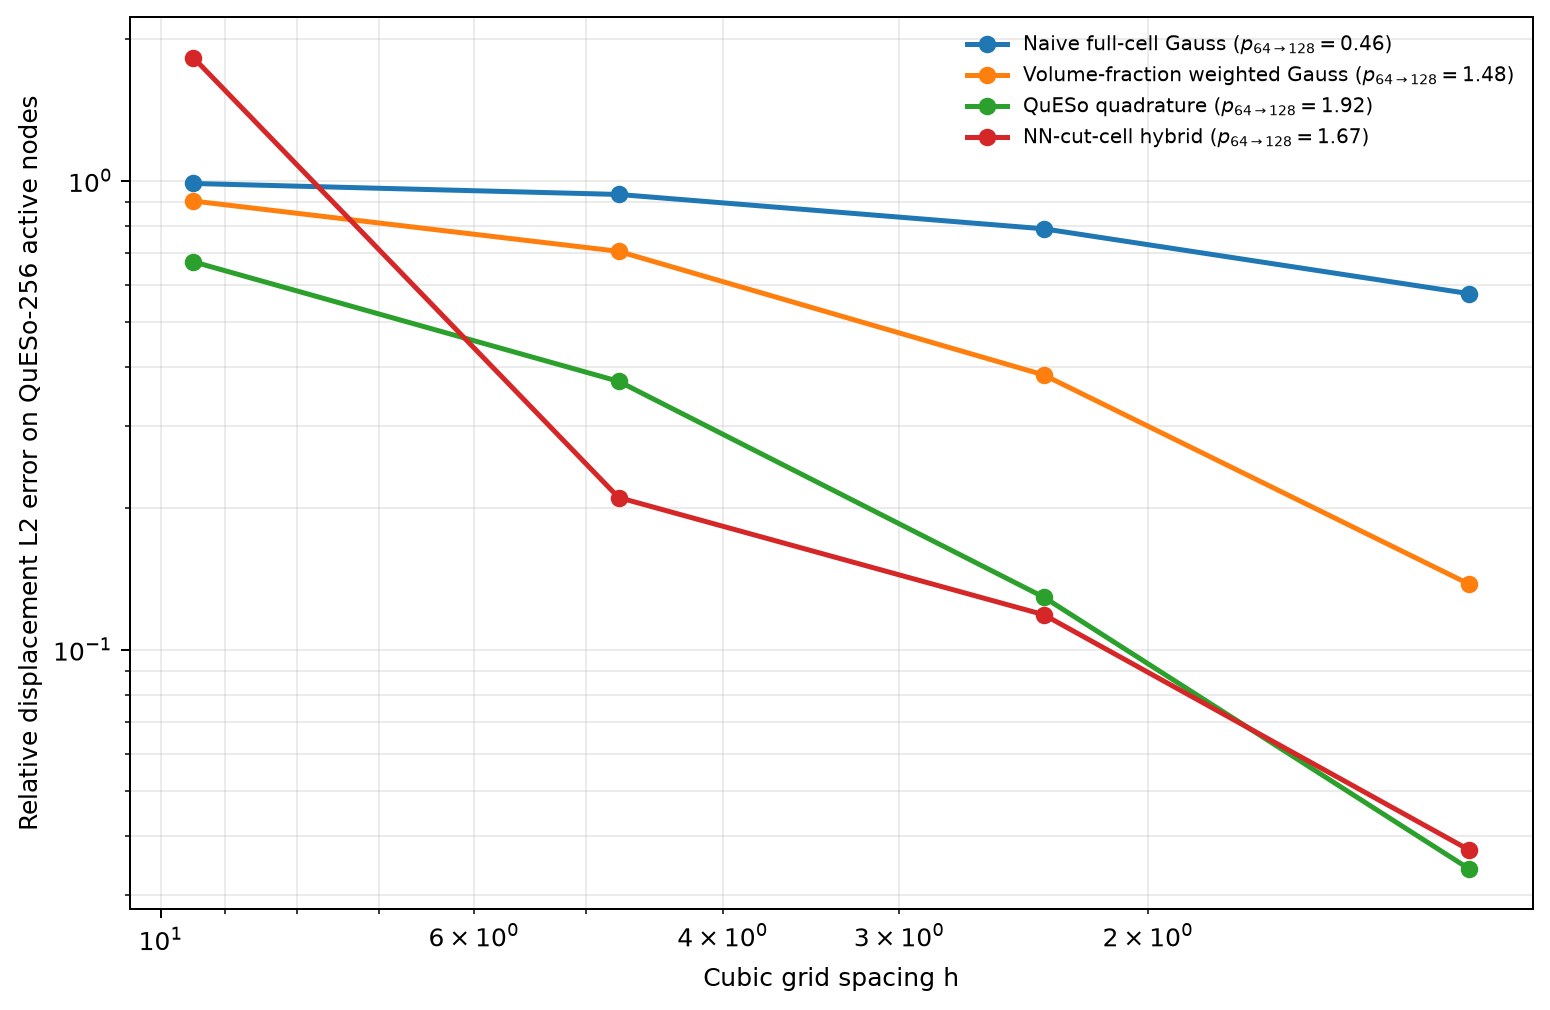

Loaded: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_convergence_v2\blade_displacement_l2_vs_queso_256.csv
Loaded: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_convergence_v2\blade_displacement_l2_vs_queso_256.png


In [154]:
from IPython.display import Image, display

import pandas as pd

BLADE_LOCAL_RESULTS = ROOT / "clean_simulation" / "notebooks" / "aws_blade_convergence_v2"
BLADE_ERROR_CSV = BLADE_LOCAL_RESULTS / "blade_displacement_l2_vs_queso_256.csv"
BLADE_FIT_CSV = BLADE_LOCAL_RESULTS / "blade_displacement_l2_vs_queso_256_global_fits.csv"
BLADE_GRAPH = BLADE_LOCAL_RESULTS / "blade_displacement_l2_vs_queso_256.png"

if not all(path.is_file() for path in (BLADE_ERROR_CSV, BLADE_FIT_CSV, BLADE_GRAPH)):
    raise FileNotFoundError("Blade result artifacts are missing. Pull aws_blade_convergence_v2 outputs first.")

blade_errors = pd.read_csv(BLADE_ERROR_CSV)
blade_fits = pd.read_csv(BLADE_FIT_CSV)
display(blade_errors[["framework", "resolution", "relative_l2_error", "local_order"]])
display(blade_fits)
display(Image(filename=str(BLADE_GRAPH)))
print(f"Loaded: {BLADE_ERROR_CSV}")
print(f"Loaded: {BLADE_GRAPH}")

Cache-cold timing scope: STL load through K representation; operator construction and CG are excluded.
Accuracy source: retained Blade V2 relative L2 error versus QuESo 256. QuESo P3 is resolution-only.


,variant,resolution,end_to_end_k_seconds,active_cells,cut_cells
0,naive,16,0.313609,335,323
4,nn_queso_classifier,16,0.520827,335,323
2,queso_p2,16,0.070743,335,323
3,queso_p3,16,0.181813,335,323
1,weighted,16,0.055418,335,323
5,naive,32,1.112922,1685,1416
9,nn_queso_classifier,32,1.188447,1685,1416
7,queso_p2,32,1.308350,1685,1416
8,queso_p3,32,6.047137,1685,1416
6,weighted,32,1.099017,1685,1416


,variant,resolution,relative_l2_error,end_to_end_k_seconds
0,naive,16,0.985832,0.313609
4,nn_queso_classifier,16,1.829176,0.520827
8,queso_p2,16,0.671097,0.070743
12,weighted,16,0.904370,0.055418
1,naive,32,0.934056,1.112922
5,nn_queso_classifier,32,0.210912,1.188447
9,queso_p2,32,0.373133,1.308350
13,weighted,32,0.706457,1.099017
2,naive,64,0.789067,4.737072
6,nn_queso_classifier,64,0.118611,5.101613


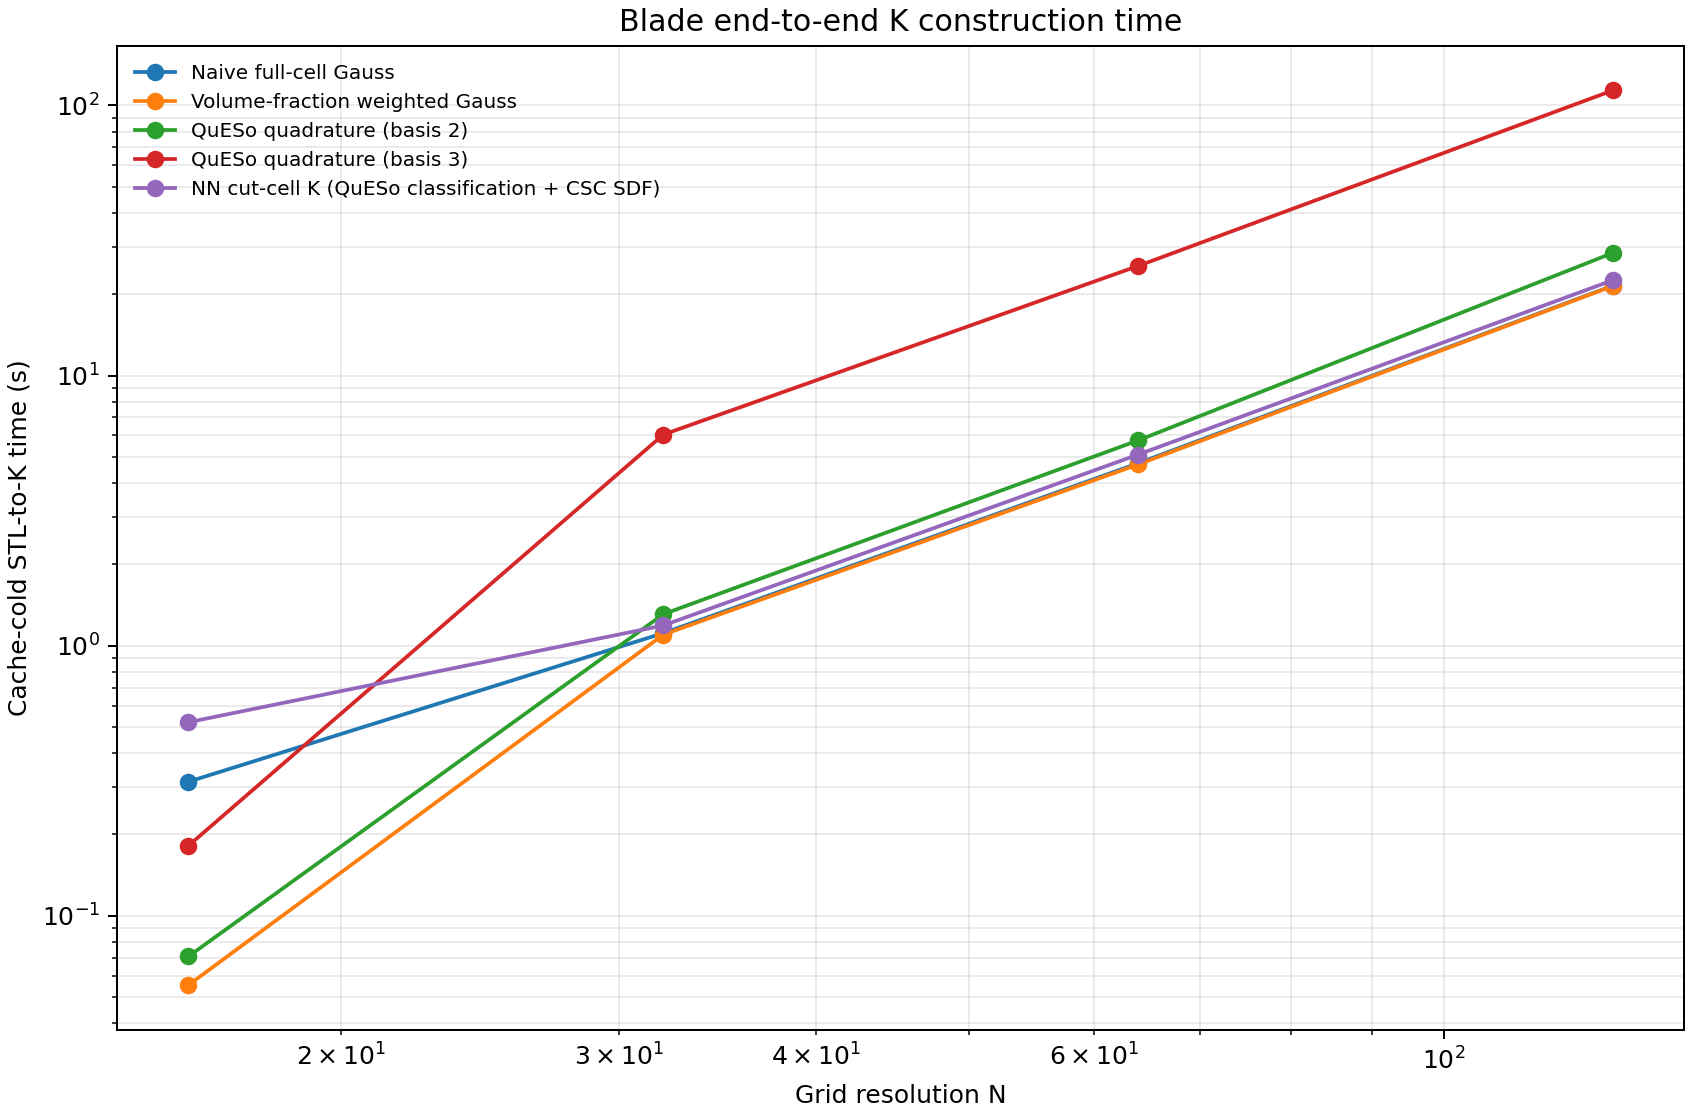

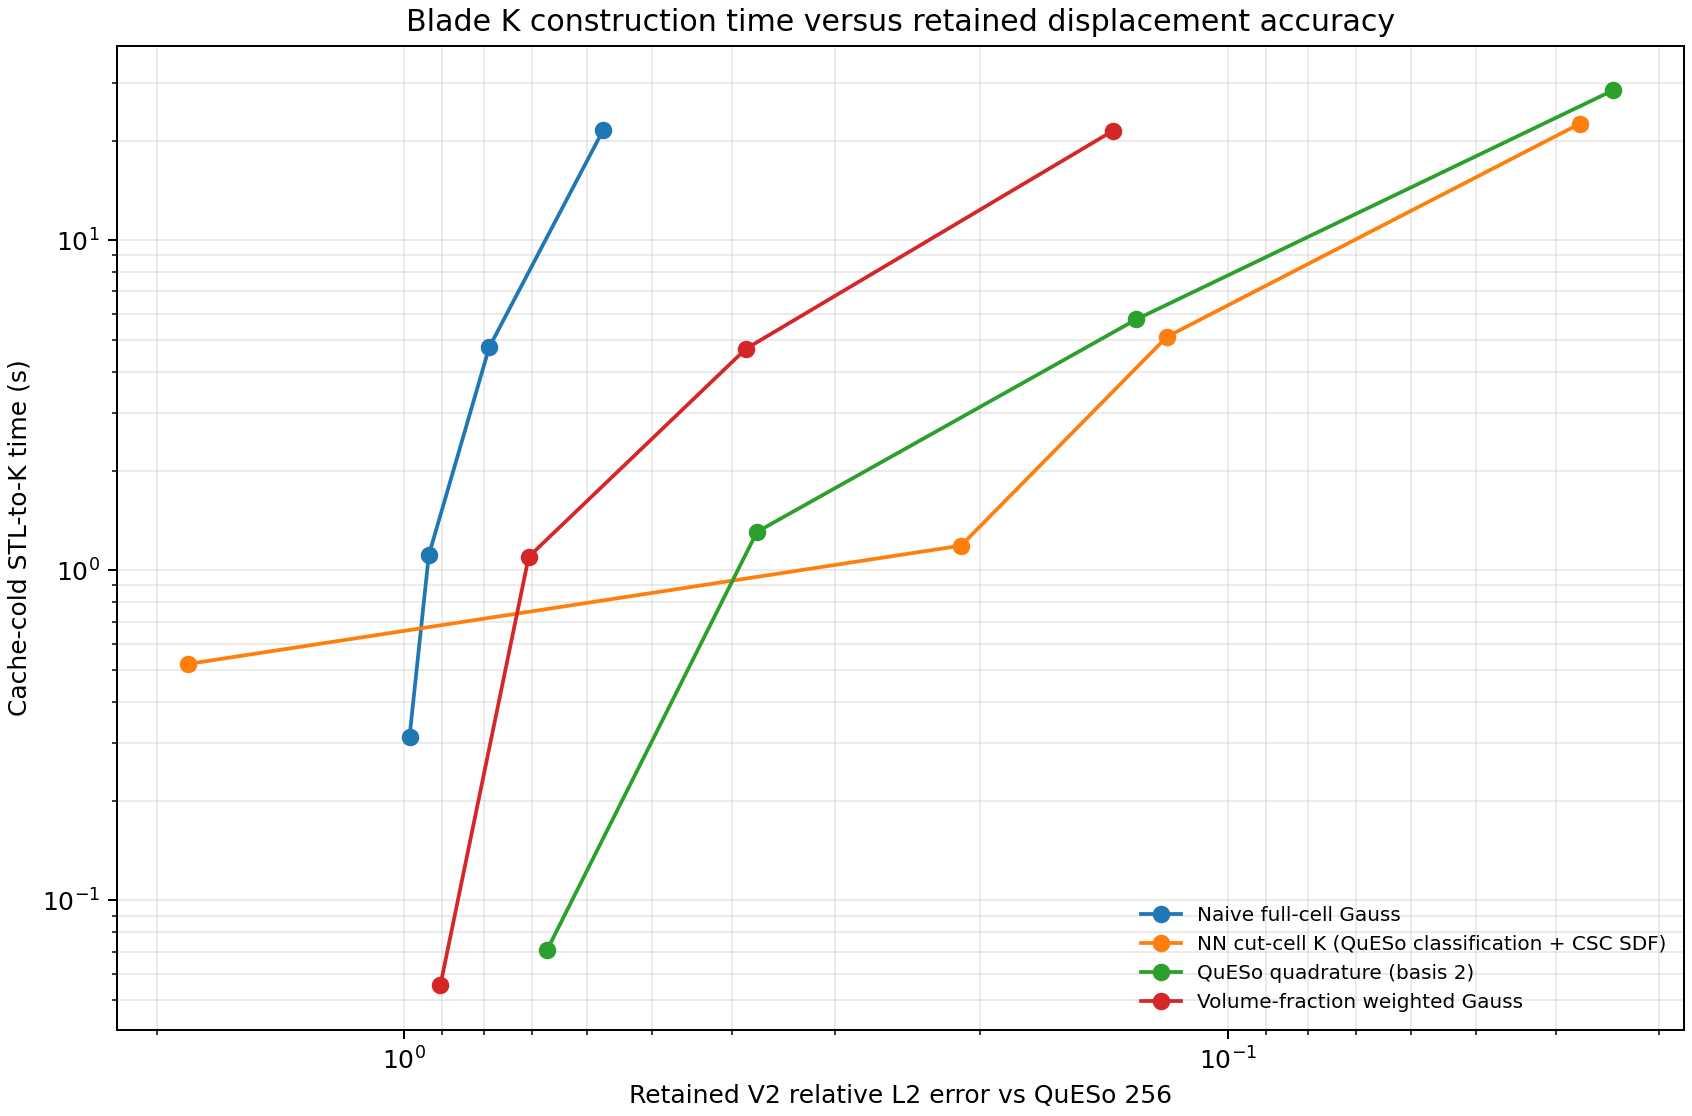

Loaded: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_end_to_end_k_timing_v3\blade_end_to_end_k_timing.csv
Loaded: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_end_to_end_k_timing_v3\blade_end_to_end_k_time_vs_resolution.png
Loaded: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_end_to_end_k_timing_v3\blade_end_to_end_k_time_vs_retained_v2_l2_error.png


In [5]:
from IPython.display import Image, display

import pandas as pd

BLADE_TIMING_RESULTS = ROOT / "clean_simulation" / "notebooks" / "aws_blade_end_to_end_k_timing_v3"
BLADE_TIMING_CSV = BLADE_TIMING_RESULTS / "blade_end_to_end_k_timing.csv"
BLADE_TIMING_ERROR_CSV = BLADE_TIMING_RESULTS / "blade_end_to_end_k_time_vs_retained_v2_l2_error.csv"
BLADE_TIME_RESOLUTION_GRAPH = BLADE_TIMING_RESULTS / "blade_end_to_end_k_time_vs_resolution.png"
BLADE_TIME_ACCURACY_GRAPH = BLADE_TIMING_RESULTS / "blade_end_to_end_k_time_vs_retained_v2_l2_error.png"

required_artifacts = (
    BLADE_TIMING_CSV,
    BLADE_TIMING_ERROR_CSV,
    BLADE_TIME_RESOLUTION_GRAPH,
    BLADE_TIME_ACCURACY_GRAPH,
)
if not all(path.is_file() for path in required_artifacts):
    missing = [str(path) for path in required_artifacts if not path.is_file()]
    raise FileNotFoundError("Missing Blade end-to-end timing artifacts:\n" + "\n".join(missing))

blade_timing = pd.read_csv(BLADE_TIMING_CSV).sort_values(["resolution", "variant"])
blade_time_accuracy = pd.read_csv(BLADE_TIMING_ERROR_CSV).sort_values(["resolution", "variant"])
expected_counts = {"naive": 4, "weighted": 4, "queso_p2": 4, "nn_queso_classifier": 4}
actual_counts = blade_time_accuracy.groupby("variant").size().to_dict()
if actual_counts != expected_counts or blade_time_accuracy["relative_l2_error"].isna().any():
    raise ValueError("The timing-versus-accuracy table does not contain the expected retained V2 L2-error joins.")

print("Cache-cold timing scope: STL load through K representation; operator construction and CG are excluded.")
print("Accuracy source: retained Blade V2 relative L2 error versus QuESo 256. QuESo P3 is resolution-only.")
display(blade_timing[["variant", "resolution", "end_to_end_k_seconds", "active_cells", "cut_cells"]])
display(blade_time_accuracy[["variant", "resolution", "relative_l2_error", "end_to_end_k_seconds"]])
display(Image(filename=str(BLADE_TIME_RESOLUTION_GRAPH)))
display(Image(filename=str(BLADE_TIME_ACCURACY_GRAPH)))
print(f"Loaded: {BLADE_TIMING_CSV}")
print(f"Loaded: {BLADE_TIME_RESOLUTION_GRAPH}")
print(f"Loaded: {BLADE_TIME_ACCURACY_GRAPH}")

In [6]:
timing_stage_columns = [
    "stl_load_seconds",
    "queso_classification_ips_seconds",
    "queso_stiffness_integration_seconds",
    "volume_fraction_seconds",
    "nn_sdf_seconds",
    "nn_inference_seconds",
    "framework_assembly_seconds",
]

blade_timing_audit = blade_timing.copy()
blade_timing_audit["shared_pre_k_seconds"] = (
    blade_timing_audit["stl_load_seconds"]
    + blade_timing_audit["queso_classification_ips_seconds"]
)
blade_timing_audit["method_specific_k_seconds"] = (
    blade_timing_audit["queso_stiffness_integration_seconds"]
    + blade_timing_audit["volume_fraction_seconds"]
    + blade_timing_audit["nn_sdf_seconds"]
    + blade_timing_audit["nn_inference_seconds"]
    + blade_timing_audit["framework_assembly_seconds"]
)
blade_timing_audit["measured_stage_sum_seconds"] = blade_timing_audit[timing_stage_columns].sum(axis=1)
blade_timing_audit["unallocated_pre_k_seconds"] = (
    blade_timing_audit["end_to_end_k_seconds"] - blade_timing_audit["measured_stage_sum_seconds"]
)

stage_table = blade_timing_audit[[
    "variant",
    "resolution",
    "stl_load_seconds",
    "queso_classification_ips_seconds",
    "queso_stiffness_integration_seconds",
    "volume_fraction_seconds",
    "nn_sdf_seconds",
    "nn_inference_seconds",
    "framework_assembly_seconds",
    "unallocated_pre_k_seconds",
    "method_specific_k_seconds",
    "end_to_end_k_seconds",
]].rename(columns={
    "variant": "method",
    "stl_load_seconds": "stl_load_s",
    "queso_classification_ips_seconds": "shared_queso_classification_ips_s",
    "queso_stiffness_integration_seconds": "queso_integration_s",
    "volume_fraction_seconds": "volume_fraction_s",
    "nn_sdf_seconds": "nn_sdf_s",
    "nn_inference_seconds": "nn_inference_s",
    "framework_assembly_seconds": "method_assembly_s",
    "unallocated_pre_k_seconds": "unallocated_pre_k_s",
    "method_specific_k_seconds": "method_specific_k_s",
    "end_to_end_k_seconds": "stl_to_k_total_s",
})

print("Stage accounting: shared QuESo classification/IP generation is deliberately charged to every method.")
print("unallocated_pre_k_s is the measured total minus named stages; it is principally full-cell Hex8 K generation, which the runner did not time separately.")
display(stage_table.round(4))

comparison_table = (
    stage_table.pivot(index="resolution", columns="method", values=["method_specific_k_s", "stl_to_k_total_s"])
    .sort_index()
)
display(comparison_table.round(4))

BLADE_TIMING_STAGE_AUDIT = BLADE_TIMING_RESULTS / "blade_end_to_end_k_stage_audit.csv"
stage_table.to_csv(BLADE_TIMING_STAGE_AUDIT, index=False)
print(f"Saved: {BLADE_TIMING_STAGE_AUDIT}")

Stage accounting: shared QuESo classification/IP generation is deliberately charged to every method.
unallocated_pre_k_s is the measured total minus named stages; it is principally full-cell Hex8 K generation, which the runner did not time separately.


,method,resolution,stl_load_s,shared_queso_classification_ips_s,queso_integration_s,volume_fraction_s,nn_sdf_s,nn_inference_s,method_assembly_s,unallocated_pre_k_s,method_specific_k_s,stl_to_k_total_s
0,naive,16,0.2395,0.0710,0.0000,0.0000,0.0000,0.0000,0.0002,0.0029,0.0002,0.3136
4,nn_queso_classifier,16,0.0069,0.3590,0.0000,0.0000,0.1414,0.0097,0.0015,0.0024,0.1526,0.5208
2,queso_p2,16,0.0062,0.0459,0.0164,0.0000,0.0000,0.0000,0.0000,0.0022,0.0164,0.0707
3,queso_p3,16,0.0062,0.1412,0.0307,0.0000,0.0000,0.0000,0.0000,0.0036,0.0308,0.1818
1,weighted,16,0.0066,0.0461,0.0000,0.0001,0.0000,0.0000,0.0004,0.0022,0.0005,0.0554
5,naive,32,0.0064,1.0979,0.0000,0.0000,0.0000,0.0000,0.0019,0.0068,0.0019,1.1129
9,nn_queso_classifier,32,0.0065,1.0904,0.0000,0.0000,0.0650,0.0153,0.0047,0.0065,0.0850,1.1884
7,queso_p2,32,0.0063,1.0803,0.2154,0.0000,0.0000,0.0000,0.0000,0.0063,0.2154,1.3083
8,queso_p3,32,0.0066,5.4821,0.5453,0.0000,0.0000,0.0000,0.0000,0.0131,0.5453,6.0471
6,weighted,32,0.0065,1.0838,0.0000,0.0002,0.0000,0.0000,0.0022,0.0063,0.0024,1.0990


method_specific_k_s                                                 \
method                   naive nn_queso_classifier queso_p2 queso_p3 weighted   
resolution                                                                      
16                      0.0002              0.1526   0.0164   0.0308   0.0005   
32                      0.0019              0.0850   0.2154   0.5453   0.0024   
64                      0.0041              0.3994   1.0862   3.2664   0.0177   
128                     0.0974              1.2831   7.1637  20.4465   0.1478   

           stl_to_k_total_s                                                  
method                naive nn_queso_classifier queso_p2  queso_p3 weighted  
resolution                                                                   
16                   0.3136              0.5208   0.0707    0.1818   0.0554  
32                   1.1129              1.1884   1.3083    6.0471   1.0990  
64                   4.7371              5.1016   5.7573   25.4724   4.6908  
128                 21.5462             22.5742  28.4890  113.8266  21.4908

Saved: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_end_to_end_k_timing_v3\blade_end_to_end_k_stage_audit.csv


## 5. Extended Blade study tracking

Tracks the separate extended study: all frameworks at $256^3$ and a QuESo $512^3$ reference. Its artifacts use `aws_blade_convergence_v3`, leaving the completed QuESo-$256^3$ study unchanged.

In [1]:
from datetime import datetime
from time import sleep

from IPython.display import clear_output

EXTENDED_BLADE_TAG = "aws_blade_convergence_v3"
EXTENDED_BLADE_RUN_DIR = f"/home/ubuntu/cutcell-training/{EXTENDED_BLADE_TAG}"
EXTENDED_BLADE_OUTPUT = f"/home/ubuntu/cutcell-training/clean_simulation/outputs/{EXTENDED_BLADE_TAG}"
EXTENDED_BLADE_JOBS = {
    "gpu0_256_all": "GPU 0: naive, weighted, QuESo, NN at 256^3",
    "gpu1_512_queso": "GPU 1: QuESo reference at 512^3",
}


def extended_job_status(job_name):
    pidfile = f"{EXTENDED_BLADE_RUN_DIR}/{job_name}.pid"
    logfile = f"{EXTENDED_BLADE_RUN_DIR}/{job_name}.log"
    return remote_text(
        f"PIDFILE={pidfile}; LOG={logfile}; "
        "if [ -f $PIDFILE ]; then "
        "PID=$(cat $PIDFILE); "
        "if kill -0 $PID 2>/dev/null; then "
        "echo \"RUNNING pid=$PID\"; ps -p $PID -o etime=,pcpu=,pmem=; "
        "else echo \"FINISHED pid=$PID\"; fi; "
        "else echo NOT_LAUNCHED; fi; "
        "tail -n 18 $LOG 2>/dev/null || true"
    )


def extended_blade_snapshot():
    progress = remote_text(
        f"if [ -f {EXTENDED_BLADE_OUTPUT}/progress.csv ]; then cat {EXTENDED_BLADE_OUTPUT}/progress.csv; "
        "else echo 'no completed extended solves yet'; fi"
    )
    checkpoints = remote_text(
        f"find {EXTENDED_BLADE_OUTPUT}/checkpoints -maxdepth 1 -type f -name '*.npz' -printf '%f\n' 2>/dev/null | sort"
    )
    gpus = remote_text(
        "nvidia-smi --query-gpu=index,utilization.gpu,memory.used,memory.total --format=csv,noheader"
    )
    return {name: extended_job_status(name) for name in EXTENDED_BLADE_JOBS} | {
        "progress": progress,
        "checkpoints": checkpoints,
        "gpus": gpus,
    }


def display_extended_blade_snapshot():
    snapshot = extended_blade_snapshot()
    print(f"Extended Blade monitor: {datetime.now():%Y-%m-%d %H:%M:%S}")
    for job_name, description in EXTENDED_BLADE_JOBS.items():
        print(f"\n===== {description} =====")
        print(snapshot[job_name] or "No status output")
    print("\n===== Completed solves =====")
    print(snapshot["progress"])
    print("\n===== Checkpoints =====")
    print(snapshot["checkpoints"] or "None")
    print("\n===== GPUs =====")
    print(snapshot["gpus"])


def watch_extended_blade_jobs(interval_seconds=30, iterations=None):
    completed = 0
    try:
        while iterations is None or completed < iterations:
            clear_output(wait=True)
            display_extended_blade_snapshot()
            completed += 1
            if iterations is None or completed < iterations:
                sleep(interval_seconds)
    except KeyboardInterrupt:
        print("Monitoring stopped.")



display_extended_blade_snapshot() 

NameError: name 'remote_text' is not defined

,framework,resolution,relative_l2_error,local_order
0,naive,16,9.859683e-01,NaN
1,naive,32,9.348573e-01,7.679516e-02
2,naive,64,7.917387e-01,2.397217e-01
3,naive,128,5.793883e-01,4.504939e-01
4,naive,256,3.631796e-01,6.738475e-01
5,nn,16,1.784495e+00,NaN
6,nn,32,2.255855e-01,2.983770e+00
7,nn,64,1.292297e-01,8.037369e-01
8,nn,128,4.912956e-02,1.395274e+00
9,nn,256,2.037809e-02,1.269573e+00


,framework,framework_label,global_order,r_squared
0,naive,Naive full-cell Gauss,3.571932e-01,9.002561e-01
1,nn,NN-cut-cell hybrid,1.510372e+00,9.511841e-01
2,queso,QuESo quadrature,1.359168e+00,9.896336e-01
3,weighted,Volume-fraction weighted Gauss,1.074135e+00,9.423687e-01


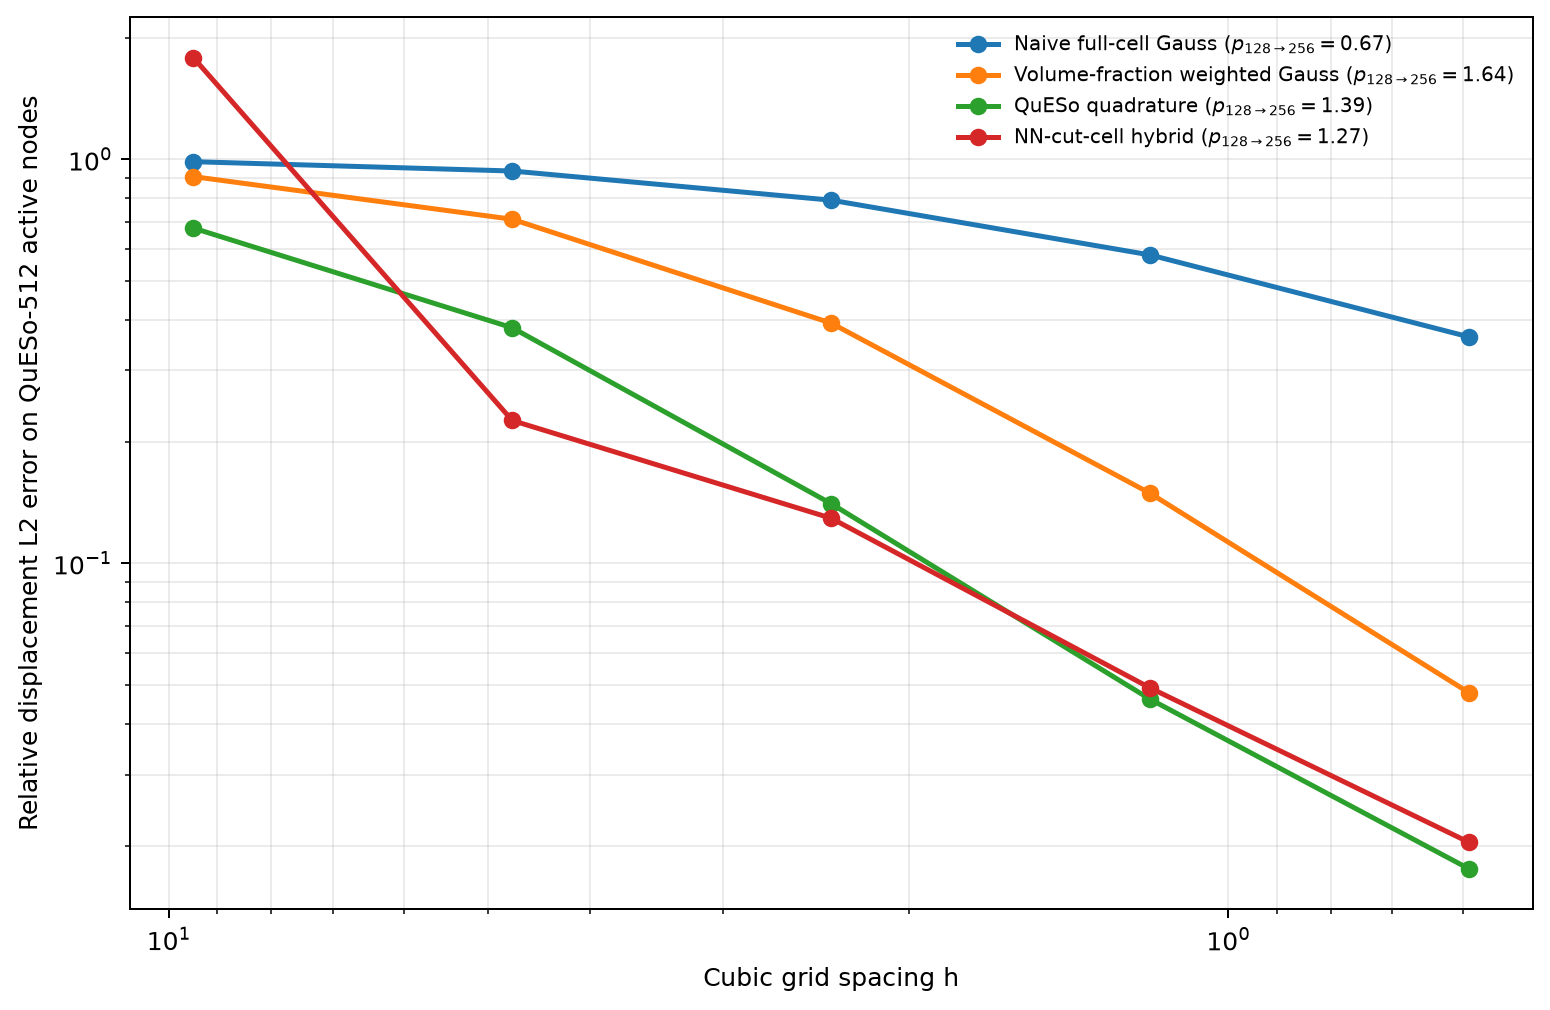

Loaded: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_convergence_v3\blade_displacement_l2_vs_queso_512.csv
Loaded: C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_blade_convergence_v3\blade_displacement_l2_vs_queso_512.png


In [211]:
from IPython.display import Image, display

import pandas as pd

EXTENDED_BLADE_LOCAL_RESULTS = ROOT / "clean_simulation" / "notebooks" / "aws_blade_convergence_v3"
EXTENDED_BLADE_ERROR_CSV = EXTENDED_BLADE_LOCAL_RESULTS / "blade_displacement_l2_vs_queso_512.csv"
EXTENDED_BLADE_FIT_CSV = EXTENDED_BLADE_LOCAL_RESULTS / "blade_displacement_l2_vs_queso_512_global_fits.csv"
EXTENDED_BLADE_GRAPH = EXTENDED_BLADE_LOCAL_RESULTS / "blade_displacement_l2_vs_queso_512.png"

required_artifacts = (EXTENDED_BLADE_ERROR_CSV, EXTENDED_BLADE_FIT_CSV, EXTENDED_BLADE_GRAPH)
if not all(path.is_file() for path in required_artifacts):
    missing = [str(path) for path in required_artifacts if not path.is_file()]
    raise FileNotFoundError("Missing extended Blade artifacts:\n" + "\n".join(missing))

extended_blade_errors = pd.read_csv(EXTENDED_BLADE_ERROR_CSV)
extended_blade_fits = pd.read_csv(EXTENDED_BLADE_FIT_CSV)
display(extended_blade_errors[["framework", "resolution", "relative_l2_error", "local_order"]])
display(extended_blade_fits)
display(Image(filename=str(EXTENDED_BLADE_GRAPH)))
print(f"Loaded: {EXTENDED_BLADE_ERROR_CSV}")
print(f"Loaded: {EXTENDED_BLADE_GRAPH}")

## 4. Pull V4 results
Pulls the completed `smooth_foundation` checkpoints and timing records into the selected local result directory.

In [119]:
from pathlib import Path
import subprocess

LOCAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
for directory in ("smooth_foundation",):
    remote_directory = f"{REMOTE_OUTPUT_DIR}/{directory}"
    command = [
        "scp",
        "-r",
        "-o", "BatchMode=yes",
        "-o", "ConnectTimeout=10",
        "-i", str(SSH_KEY),
        f"{SSH_HOST}:{remote_directory}",
        str(LOCAL_RESULTS_DIR),
    ]
    print(f"Pulling {RUN_TAG} {directory} results ...")
    result = subprocess.run(
        command,
        stdin=subprocess.DEVNULL,
        capture_output=True,
        text=True,
        timeout=1800,
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr.strip())
print(f"Pulled results: {LOCAL_RESULTS_DIR / 'smooth_foundation'}")

Pulling aws_convergence_clean_v5 smooth_foundation results ...
Pulled results: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\smooth_foundation


In [126]:
remote_root = "/home/ubuntu/cutcell-training"
remote_output = f"{remote_root}/clean_simulation/outputs/{RUN_TAG}"
local_evaluator = ROOT / "clean_simulation" / "scripts" / "evaluate_remote_displacement_convergence.py"
copy_to_remote(local_evaluator, f"{remote_root}/clean_simulation/scripts/evaluate_remote_displacement_convergence.py")

evaluation_command = (
    f"cd {remote_root} && env "
    f"HANGING_SPHERE_OUTPUT_ROOT={remote_output} "
    f"HANGING_SPHERE_SUPPORT_MODE={SUPPORT_MODE} "
    f"REFERENCE_RESOLUTION={REFERENCE_RESOLUTION} "
    f"EVALUATION_RESOLUTIONS=8,16,32,64,128 "
    f"FIT_RESOLUTIONS=16,32,64,128 "
    f"{REMOTE_PYTHON} clean_simulation/scripts/evaluate_remote_displacement_convergence.py"
)
run_remote(evaluation_command, timeout=1800)

Evaluating fixed reference support: naive 8^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: naive 16^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: naive 32^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: naive 64^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: naive 128^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: weighted 8^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: weighted 16^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: weighted 32^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluating fixed reference support: weighted 64^3
  active_nodes=5,290,523; support_volume_fraction=100.000000%
Evaluati

(0,
 'Evaluating fixed reference support: naive 8^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: naive 16^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: naive 32^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: naive 64^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: naive 128^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: weighted 8^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: weighted 16^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: weighted 32^3\n  active_nodes=5,290,523; support_volume_fraction=100.000000%\nEvaluating fixed reference support: weighted 64^3\n  active_nodes=5,290,523; support_volume_fracti

In [13]:
import subprocess

for framework in ["naive", "weighted", "queso", "nn"]:

    f = f"hanging_sphere_{framework}_displacement_256cubed.npz"

    cmd = [
        "scp",
        "-o", "ConnectTimeout=10",
        "-i", str(SSH_KEY),
        f"{SSH_HOST}:~/cutcell-training/clean_simulation/outputs/aws_pilot_512/smooth_foundation/{f}",
        str(LOCAL_RESULTS_DIR / f),
    ]

    print(f"Copying 256³ {framework.upper()}...")
    subprocess.run(
        cmd,
        stdin=subprocess.DEVNULL,
        check=True,
        timeout=600,   # 10 minutes
    )
    print("Done.")

Copying 256³ NN...
Done.


## 5. Checkpoint matrix
128³ must show `OK` for all four methods before accepting the convergence study.


In [120]:
import numpy as np
import pandas as pd

CKPT_DIR = LOCAL_RESULTS_DIR / "smooth_foundation"

rows = []
for framework in FRAMEWORKS:
    for N in RESOLUTIONS:
        p = CKPT_DIR / f"hanging_sphere_{framework}_displacement_{N}cubed.npz"
        if not p.is_file():
            rows.append({"framework": framework, "N": N, "status": "MISSING"})
            continue
        with np.load(p, allow_pickle=True) as z:
            rows.append({
                "framework": framework,
                "N": N,
                "status": "OK",
                "u_shape": str(z["u_nodes"].shape),
                "active_nodes": len(z["active_nodes"]),
                "runtime_s": float(z["runtime_seconds"]),
            })

checkpoint_df = pd.DataFrame(rows)
display(checkpoint_df)


,framework,N,status,u_shape,active_nodes,runtime_s
0,naive,8,OK,"(729, 3)",4.610000e+02,3.742676e-01
1,naive,16,OK,"(4913, 3)",2.199000e+03,1.238254e+00
2,naive,32,OK,"(35937, 3)",1.342100e+04,7.255792e+00
3,naive,64,OK,"(274625, 3)",9.291900e+04,3.071026e+01
4,naive,128,OK,"(2146689, 3)",6.877410e+05,2.643303e+02
5,naive,256,MISSING,NaN,NaN,NaN
6,weighted,8,OK,"(729, 3)",4.610000e+02,2.987633e-01
7,weighted,16,OK,"(4913, 3)",2.199000e+03,1.058274e+00
8,weighted,32,OK,"(35937, 3)",1.342100e+04,6.149544e+00
9,weighted,64,OK,"(274625, 3)",9.291900e+04,2.557982e+01


## 6. Validated convergence vs QuESo-256
The published convergence ladder uses $N=8,16,32,64$ and evaluates every QuESo-256 reference-active node. The completed 128³ checkpoints remain available for timing and follow-up diagnostics, but are excluded from the validated observed-order plot.

Analysis directory: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\smooth_foundation
Published resolutions: (8, 16, 32, 64); reference: QuESo-256^3


,framework,label,resolution,h,active_reference_nodes,relative_l2_error,runtime_seconds,observed_order
0,naive,Naive full-cell Gauss,8,2.250000e+00,5290523,1.031356e-01,3.742676e-01,NaN
1,naive,Naive full-cell Gauss,16,1.125000e+00,5290523,1.204144e-02,1.238254e+00,3.098463e+00
2,naive,Naive full-cell Gauss,32,5.625000e-01,5290523,6.902891e-03,7.255792e+00,8.027350e-01
3,naive,Naive full-cell Gauss,64,2.812500e-01,5290523,4.034393e-03,3.071026e+01,7.748491e-01
4,nn,NN-cut-cell hybrid,8,2.250000e+00,5290523,1.249153e-01,2.141433e+01,NaN
5,nn,NN-cut-cell hybrid,16,1.125000e+00,5290523,4.520553e-03,4.680827e+01,4.788307e+00
6,nn,NN-cut-cell hybrid,32,5.625000e-01,5290523,1.769551e-03,1.127318e+02,1.353116e+00
7,nn,NN-cut-cell hybrid,64,2.812500e-01,5290523,7.920289e-04,2.727434e+02,1.159758e+00
8,queso,QuESo quadrature,8,2.250000e+00,5290523,1.214655e-01,1.451972e-01,NaN
9,queso,QuESo quadrature,16,1.125000e+00,5290523,3.739777e-03,2.665631e-02,5.021450e+00


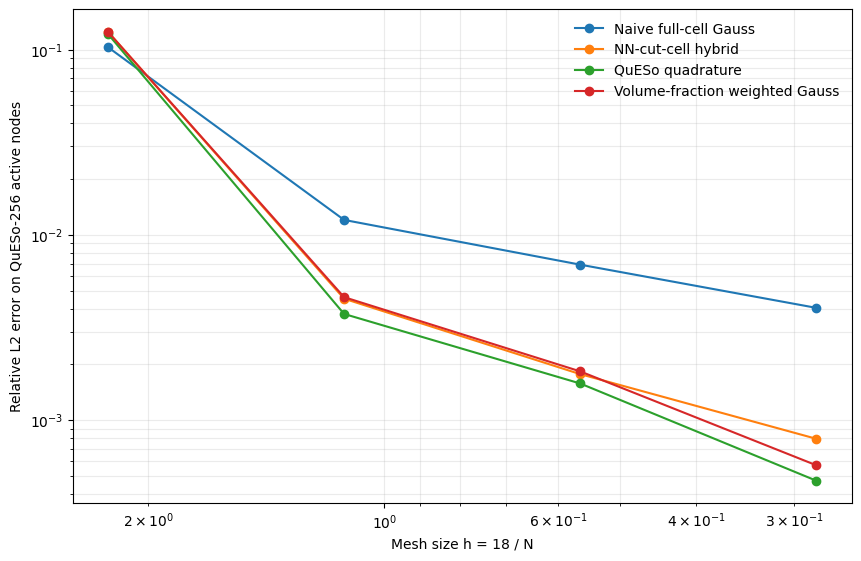

Saved: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\smooth_foundation\validated_convergence_all_reference_active_nodes.csv


In [122]:
# Validated convergence against QuESo-256 on every reference-active node.
# The 128^3 checkpoints are retained for timing and diagnostics, but this published
# ladder stops at 64^3 because the next comparison requires a separate support study.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "clean_simulation").is_dir():
    raise RuntimeError("Run this notebook from the repository root or its notebooks directory.")

REFERENCE_RESOLUTION = 256
ANALYSIS_RESOLUTIONS = (8, 16, 32, 64)
FRAMEWORKS = {
    "naive": "Naive full-cell Gauss",
    "weighted": "Volume-fraction weighted Gauss",
    "queso": "QuESo quadrature",
    "nn": "NN-cut-cell hybrid",
}


def has_reference(directory):
    return (directory / f"hanging_sphere_queso_displacement_{REFERENCE_RESOLUTION}cubed.npz").is_file()


result_candidates = [
    Path(globals().get("LOCAL_RESULTS_DIR", ROOT / "notebooks" / "aws_pilot_results")),
    ROOT / "notebooks" / "aws_pilot_results",
]
ANALYSIS_DIR = next(
    (directory / "smooth_foundation" for directory in result_candidates if has_reference(directory / "smooth_foundation")),
    next((directory for directory in result_candidates if has_reference(directory)), None),
)
if ANALYSIS_DIR is None:
    searched = "\n  ".join(str(directory) for directory in result_candidates)
    raise FileNotFoundError(f"No local QuESo-{REFERENCE_RESOLUTION} checkpoint found. Searched:\n  {searched}")
print(f"Analysis directory: {ANALYSIS_DIR}")
print(f"Published resolutions: {ANALYSIS_RESOLUTIONS}; reference: QuESo-{REFERENCE_RESOLUTION}^3")


def checkpoint_path(framework, resolution):
    return ANALYSIS_DIR / f"hanging_sphere_{framework}_displacement_{resolution}cubed.npz"


def load_checkpoint(framework, resolution):
    path = checkpoint_path(framework, resolution)
    if not path.is_file():
        raise FileNotFoundError(path)
    with np.load(path, allow_pickle=False) as archive:
        field = np.asarray(archive["u_nodes"], dtype=np.float64)
        active_cells = np.unique(np.asarray(archive["active_cells"], dtype=np.int64))
        runtime = float(archive["runtime_seconds"]) if "runtime_seconds" in archive.files else np.nan
    expected = ((resolution + 1) ** 3, 3)
    if field.shape != expected:
        raise ValueError(f"{path.name}: expected u_nodes={expected}, received {field.shape}.")
    return field.reshape((resolution + 1,) * 3 + (3,)), active_cells, runtime


def active_node_mask(active_cells, resolution):
    cells = np.zeros((resolution, resolution, resolution), dtype=bool)
    cells.reshape(-1)[active_cells] = True
    nodes = np.zeros((resolution + 1, resolution + 1, resolution + 1), dtype=bool)
    for x, y, z in ((0, 0, 0), (1, 0, 0), (1, 1, 0), (0, 1, 0),
                    (0, 0, 1), (1, 0, 1), (1, 1, 1), (0, 1, 1)):
        nodes[x:x + resolution, y:y + resolution, z:z + resolution] |= cells
    return nodes


def interpolate_to_reference(field, resolution):
    if resolution == REFERENCE_RESOLUTION:
        return field
    tensor = torch.from_numpy(field.astype(np.float64, copy=False)).permute(3, 0, 1, 2).unsqueeze(0)
    return F.interpolate(
        tensor,
        size=(REFERENCE_RESOLUTION + 1,) * 3,
        mode="trilinear",
        align_corners=True,
    ).squeeze(0).permute(1, 2, 3, 0).numpy()


reference, reference_cells, _ = load_checkpoint("queso", REFERENCE_RESOLUTION)
reference_mask = active_node_mask(reference_cells, REFERENCE_RESOLUTION)
if not reference_mask.any():
    raise RuntimeError("The QuESo-256 checkpoint contains no active nodes.")
reference_values = reference[reference_mask]
reference_norm = np.linalg.norm(reference_values)
if reference_norm == 0.0:
    raise RuntimeError("The QuESo-256 active-node displacement norm is zero.")

rows = []
for framework, label in FRAMEWORKS.items():
    for resolution in ANALYSIS_RESOLUTIONS:
        field, _, runtime = load_checkpoint(framework, resolution)
        field_on_reference = interpolate_to_reference(field, resolution)
        relative_l2_error = np.linalg.norm(field_on_reference[reference_mask] - reference_values) / reference_norm
        rows.append({
            "framework": framework,
            "label": label,
            "resolution": resolution,
            "h": 18.0 / resolution,
            "active_reference_nodes": int(reference_mask.sum()),
            "relative_l2_error": relative_l2_error,
            "runtime_seconds": runtime,
        })

convergence_df = pd.DataFrame(rows).sort_values(["framework", "resolution"]).reset_index(drop=True)
convergence_df["observed_order"] = np.nan
for framework, curve in convergence_df.groupby("framework"):
    curve = curve.sort_values("resolution")
    errors = curve["relative_l2_error"].to_numpy()
    resolutions = curve["resolution"].to_numpy()
    valid = (errors[:-1] > 0.0) & (errors[1:] > 0.0)
    orders = np.full(len(curve) - 1, np.nan)
    orders[valid] = np.log(errors[:-1][valid] / errors[1:][valid]) / np.log(resolutions[1:][valid] / resolutions[:-1][valid])
    convergence_df.loc[curve.index[1:], "observed_order"] = orders

display(convergence_df)

fig, axis = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
for framework, curve in convergence_df.groupby("framework"):
    curve = curve.sort_values("resolution")
    axis.loglog(curve["h"], curve["relative_l2_error"], "o-", label=curve["label"].iloc[0])
axis.invert_xaxis()
axis.set(xlabel="Mesh size h = 18 / N", ylabel="Relative L2 error on QuESo-256 active nodes")
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False)
plt.show()

output = ANALYSIS_DIR / "validated_convergence_all_reference_active_nodes.csv"
convergence_df.to_csv(output, index=False)
print(f"Saved: {output}")

,framework,framework_label,resolution,relative_l2_error,local_order
0,naive,Naive full-cell Gauss,128,2.061330e-03,NaN
1,nn,NN-cut-cell hybrid,128,3.246250e-04,NaN
2,queso,QuESo quadrature,128,1.077303e-04,NaN
3,weighted,Geometric-volume-fraction weighted Gauss,128,1.456879e-04,NaN


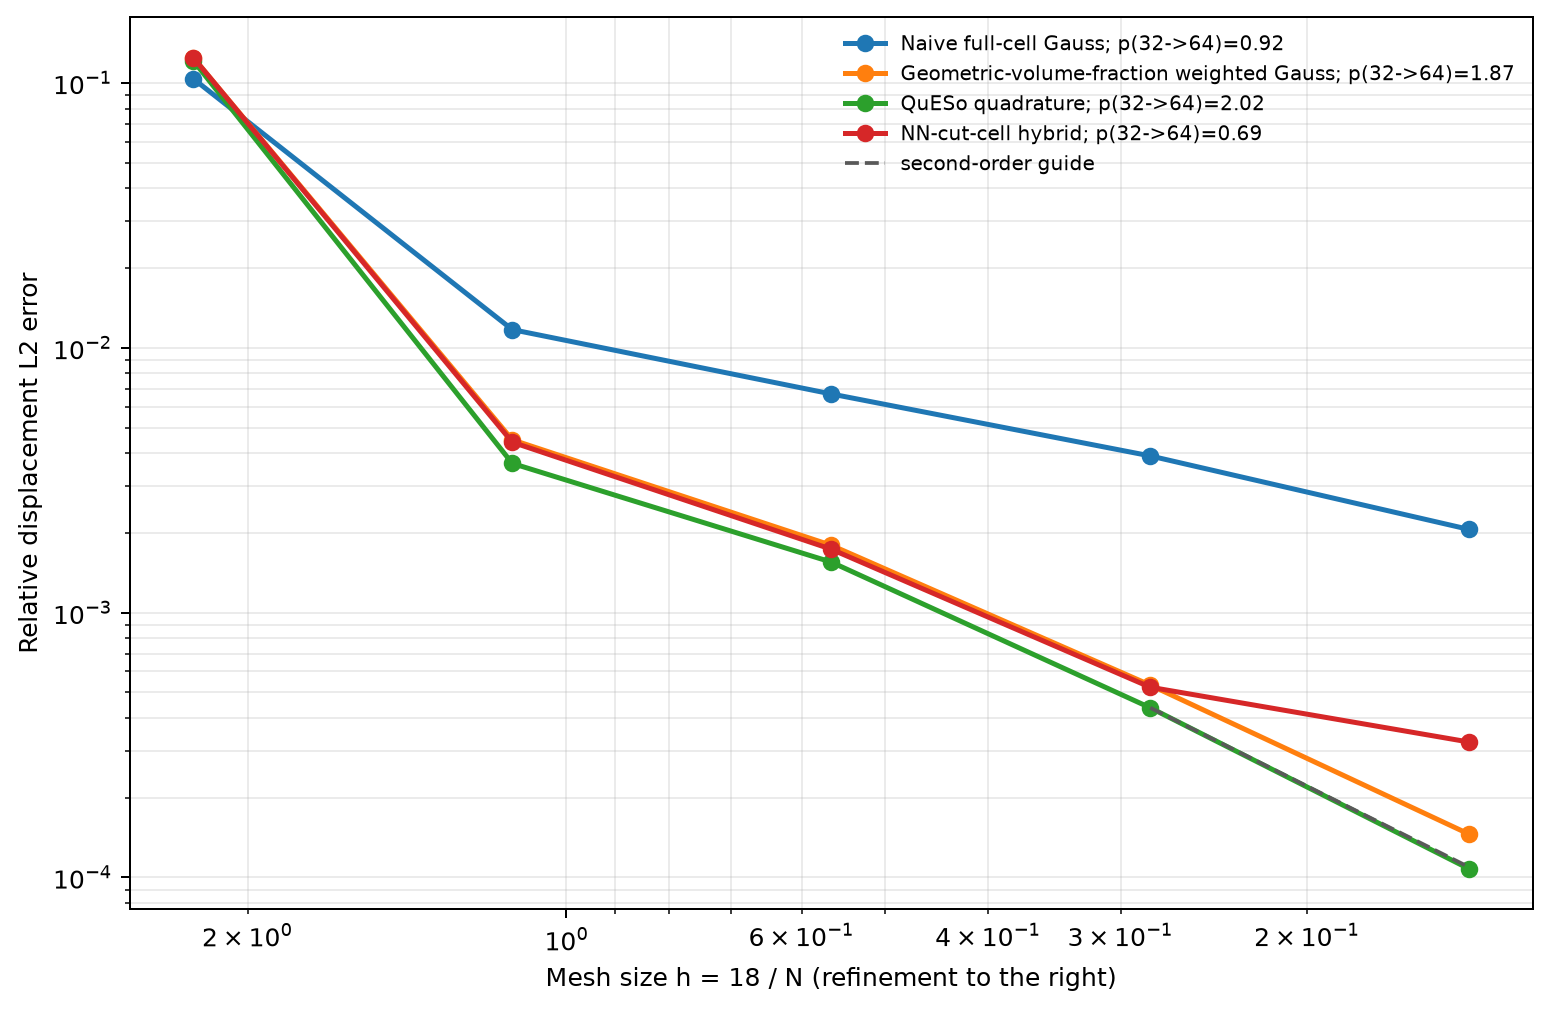

Loaded: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\smooth_foundation\four_framework_physical_volume_weighted_l2_vs_queso_256.csv
Loaded: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\smooth_foundation\four_framework_fixed_reference_support_l2_vs_queso_256.png


In [127]:
# Physical-volume-weighted convergence on the fixed QuESo-256 active support.
# This is the 128^3-inclusive error graph: weights suppress the grid-dependent
# boundary-node artifact of an unweighted nodal norm while retaining all active nodes.
from IPython.display import Image, display

physical_csv = ANALYSIS_DIR / "four_framework_physical_volume_weighted_l2_vs_queso_256.csv"
physical_png = ANALYSIS_DIR / "four_framework_fixed_reference_support_l2_vs_queso_256.png"
if not physical_csv.is_file() or not physical_png.is_file():
    raise FileNotFoundError("Run the remote physical evaluator and pull its CSV/PNG artifacts first.")

physical_convergence_df = pd.read_csv(physical_csv)
resolution_128_df = (
    physical_convergence_df.loc[
        physical_convergence_df["resolution"] == 128,
        ["framework", "framework_label", "resolution", "relative_l2_error", "local_order"],
    ]
    .sort_values("framework")
    .reset_index(drop=True)
)
display(resolution_128_df)
display(Image(filename=str(physical_png)))
print(f"Loaded: {physical_csv}")
print(f"Loaded: {physical_png}")

## 7. Observed orders
Target orders are **not imposed** on the data. The notebook reports pairwise orders and a log-log fit; the target lines are only guides.


In [123]:
TARGET_ORDER = {
    "naive": 1.2,
    "weighted": 1.5,
    "queso": 2.0,
    "nn": 2.0,
}

pairwise = []
fits = []

for framework, target in TARGET_ORDER.items():
    g = convergence_df[
        (convergence_df.framework == framework) &
        (convergence_df.resolution < REFERENCE_RESOLUTION) &
        (convergence_df.relative_l2_error > 0)
    ].sort_values("resolution")

    for coarse, fine in zip(g.iloc[:-1].itertuples(), g.iloc[1:].itertuples()):
        observed_order = np.log(coarse.relative_l2_error / fine.relative_l2_error) / np.log(coarse.h / fine.h)
        pairwise.append({
            "framework": framework,
            "from_N": int(coarse.resolution),
            "to_N": int(fine.resolution),
            "observed_order": observed_order,
        })

    if len(g) >= 2:
        observed_fit = np.polyfit(np.log(g.h), np.log(g.relative_l2_error), 1)[0]
        fits.append({
            "framework": framework,
            "target": target,
            "observed_fit": observed_fit,
            "difference": observed_fit - target,
            "points": len(g),
        })

pairwise_df = pd.DataFrame(pairwise)
fit_df = pd.DataFrame(fits)

print("Pairwise observed orders:")
display(pairwise_df)

print("Global log-log observed order:")
display(fit_df)

Pairwise observed orders:


,framework,from_N,to_N,observed_order
0,naive,8,16,3.098463e+00
1,naive,16,32,8.027350e-01
2,naive,32,64,7.748491e-01
3,weighted,8,16,4.758661e+00
4,weighted,16,32,1.331500e+00
5,weighted,32,64,1.683950e+00
6,queso,8,16,5.021450e+00
7,queso,16,32,1.247265e+00
8,queso,32,64,1.743703e+00
9,nn,8,16,4.788307e+00


Global log-log observed order:


,framework,target,observed_fit,difference,points
0,naive,1.200000e+00,1.483088e+00,2.830877e-01,4
1,weighted,1.500000e+00,2.465383e+00,9.653833e-01,4
2,queso,2.000000e+00,2.528452e+00,5.284518e-01,4
3,nn,2.000000e+00,2.325666e+00,3.256659e-01,4


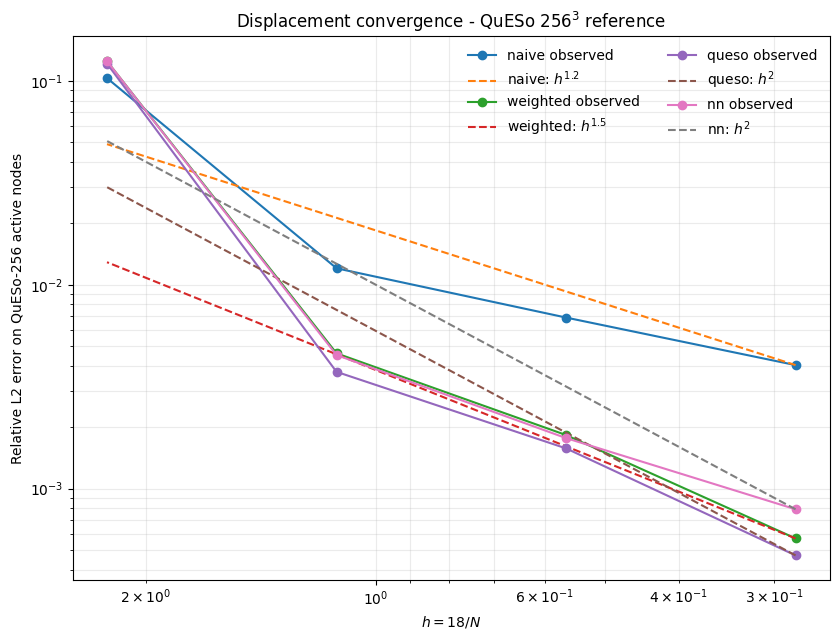

Saved: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\convergence_queso256_all_active_nodes_L2.png


In [124]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 6.5))

for framework, target in TARGET_ORDER.items():
    g = convergence_df[
        (convergence_df.framework == framework) &
        (convergence_df.resolution < REFERENCE_RESOLUTION) &
        (convergence_df.relative_l2_error > 0)
    ].sort_values("h", ascending=False)

    if g.empty:
        continue

    ax.loglog(g.h, g.relative_l2_error, "o-", label=f"{framework} observed")

    h0 = g.h.iloc[-1]
    e0 = g.relative_l2_error.iloc[-1]
    hs = np.array([g.h.min(), g.h.max()])
    ax.loglog(
        hs, e0 * (hs / h0) ** target, "--",
        label=fr"{framework}: $h^{{{target:g}}}$"
    )

ax.invert_xaxis()
ax.set_xlabel(r"$h=18/N$")
ax.set_ylabel(r"Relative L2 error on QuESo-256 active nodes")
ax.set_title(r"Displacement convergence - QuESo $256^3$ reference")
ax.grid(True, which="both", alpha=0.25)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()

out = LOCAL_RESULTS_DIR / "convergence_queso256_all_active_nodes_L2.png"
fig.savefig(out, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", out)

## 8. Detailed K-only pipeline timing
CG is excluded completely. The table separates the shared geometry/QuESo classification/integration pipeline, foundation construction, NN SDF/input preparation, and framework-specific stiffness construction. The end-to-end K total is the sum of those K-pipeline stages only.

,timing_column,measured_operations
0,shared_geometry_queso_pipeline_seconds,STL/geometry setup; QuESo classification; inte...
1,foundation_seconds,Smooth-foundation sparse boundary matrix const...
2,nn_sdf_and_input_seconds,NN only: SDF evaluation and NN input preparation
3,framework_stiffness_seconds,"QuESo matrix selection, normalized-naive matri..."
4,end_to_end_k_seconds,"Sum of all preceding K-pipeline stages; CG, op..."


,job_tag,gpu,framework,resolution,shared_geometry_queso_pipeline_seconds,foundation_seconds,nn_sdf_and_input_seconds,framework_stiffness_seconds,end_to_end_k_seconds
0,gpu0_ladder,0,naive,8,2.849510e+01,1.400000e-03,0.000000e+00,1.000000e-04,2.849660e+01
3,gpu0_ladder,0,nn,8,2.849510e+01,1.400000e-03,2.081460e+01,3.900000e-03,4.931500e+01
2,gpu0_ladder,0,queso,8,2.849510e+01,1.400000e-03,0.000000e+00,1.000000e-04,2.849660e+01
1,gpu0_ladder,0,weighted,8,2.849510e+01,1.400000e-03,0.000000e+00,2.000000e-04,2.849670e+01
4,gpu0_ladder,0,naive,16,5.602430e+01,3.900000e-03,0.000000e+00,5.000000e-04,5.602870e+01
7,gpu0_ladder,0,nn,16,5.602430e+01,3.900000e-03,4.488620e+01,5.500000e-03,1.009199e+02
6,gpu0_ladder,0,queso,16,5.602430e+01,3.900000e-03,0.000000e+00,8.000000e-04,5.602900e+01
5,gpu0_ladder,0,weighted,16,5.602430e+01,3.900000e-03,0.000000e+00,5.000000e-04,5.602870e+01
8,gpu0_ladder,0,naive,32,6.262370e+01,2.340000e-02,0.000000e+00,1.900000e-03,6.264900e+01
11,gpu0_ladder,0,nn,32,6.262370e+01,2.340000e-02,1.010377e+02,1.690000e-02,1.637017e+02


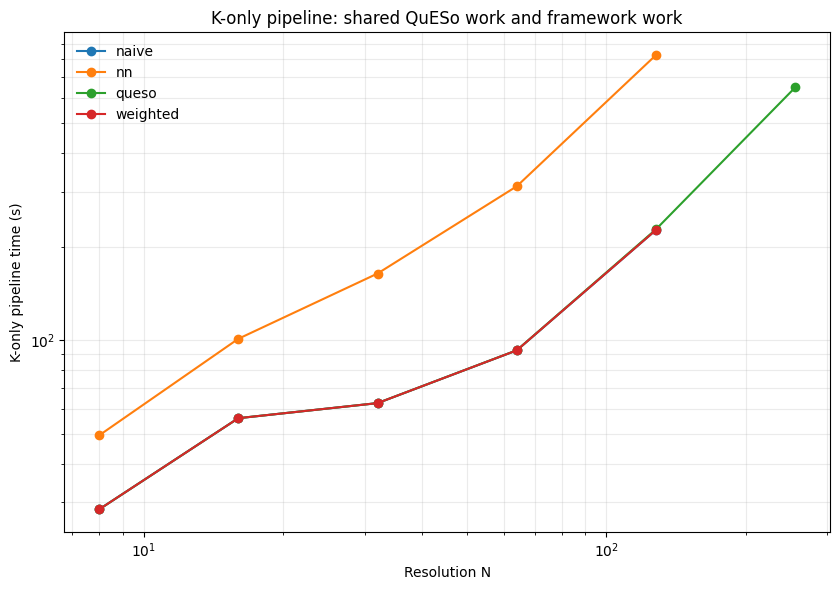

Saved: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\detailed_k_only_pipeline_timing.csv
Saved: C:\Users\z0058p1u\Documents\code\notebooks\aws_convergence_clean_v5\detailed_K_only_pipeline_time_vs_resolution.png


In [129]:
timing_files = list(CKPT_DIR.glob("timing_*.csv"))
if not timing_files:
    print("No timing files yet. Pull results first.")
else:
    timing_df = pd.concat([pd.read_csv(path) for path in timing_files], ignore_index=True)
    timing_df = timing_df[timing_df["status"] == "converged"].copy()
    timing_df["shared_geometry_queso_pipeline_seconds"] = timing_df["problem_build_seconds"]
    timing_df["foundation_seconds"] = timing_df["boundary_term_seconds"]
    timing_df["nn_sdf_and_input_seconds"] = timing_df["k_input_prep_seconds"].where(timing_df["framework"] == "nn", 0.0)
    timing_df["framework_stiffness_seconds"] = timing_df["k_assembly_seconds"]
    timing_df["end_to_end_k_seconds"] = (
        timing_df["shared_geometry_queso_pipeline_seconds"]
        + timing_df["foundation_seconds"]
        + timing_df["nn_sdf_and_input_seconds"]
        + timing_df["framework_stiffness_seconds"]
    )

    timing_scope_df = pd.DataFrame([
        {"timing_column": "shared_geometry_queso_pipeline_seconds", "measured_operations": "STL/geometry setup; QuESo classification; integration-point selection and extraction; QuESo per-cell integration; strict-full-cell classification; volume fractions; shared force preparation"},
        {"timing_column": "foundation_seconds", "measured_operations": "Smooth-foundation sparse boundary matrix construction"},
        {"timing_column": "nn_sdf_and_input_seconds", "measured_operations": "NN only: SDF evaluation and NN input preparation"},
        {"timing_column": "framework_stiffness_seconds", "measured_operations": "QuESo matrix selection, normalized-naive matrix construction, or NN stiffness inference and placement"},
        {"timing_column": "end_to_end_k_seconds", "measured_operations": "Sum of all preceding K-pipeline stages; CG, operator construction, and solve are excluded"},
    ])
    display(timing_scope_df)

    columns = [
        "job_tag", "gpu", "framework", "resolution",
        "shared_geometry_queso_pipeline_seconds", "foundation_seconds",
        "nn_sdf_and_input_seconds", "framework_stiffness_seconds",
        "end_to_end_k_seconds",
    ]
    detailed_k_timing_df = timing_df.sort_values(["resolution", "framework"])[columns]
    display(detailed_k_timing_df)

    timing_output = LOCAL_RESULTS_DIR / "detailed_k_only_pipeline_timing.csv"
    detailed_k_timing_df.to_csv(timing_output, index=False)

    fig, ax = plt.subplots(figsize=(8.5, 6))
    for framework, group in detailed_k_timing_df.groupby("framework"):
        group = group.sort_values("resolution")
        ax.loglog(group["resolution"], group["end_to_end_k_seconds"], "o-", label=framework)
    ax.set_xlabel("Resolution N")
    ax.set_ylabel("K-only pipeline time (s)")
    ax.set_title("K-only pipeline: shared QuESo work and framework work")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    out = LOCAL_RESULTS_DIR / "detailed_K_only_pipeline_time_vs_resolution.png"
    fig.savefig(out, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", timing_output)
    print("Saved:", out)

## 9. CG diagnostic
CG is intentionally separate. The runner uses larger element batches, fewer convergence checks, GPU-resident RHS vectors, and TF32 on supported GPUs.


,framework,resolution,cg_seconds,cg_iterations
0,naive,8,7.570000e-02,50
3,nn,8,7.550000e-02,50
2,queso,8,7.790000e-02,50
1,weighted,8,7.580000e-02,50
4,naive,16,5.346000e-01,100
7,nn,16,5.322000e-01,100
6,queso,16,1.210000e-02,50
5,weighted,16,2.701000e-01,50
8,naive,32,3.033200e+00,100
11,nn,32,6.012000e+00,200


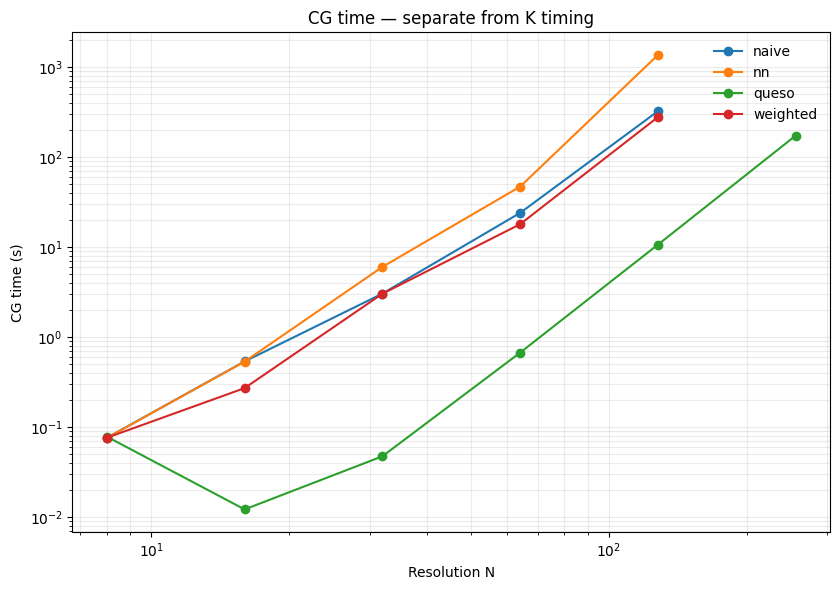

In [110]:
if "timing_df" in globals():
    cg = timing_df[timing_df.status == "converged"].copy()
    display(
        cg.sort_values(["resolution", "framework"])[
            ["framework", "resolution", "cg_seconds", "cg_iterations"]
        ]
    )

    fig, ax = plt.subplots(figsize=(8.5, 6))
    for framework, g in cg.groupby("framework"):
        g = g.sort_values("resolution")
        ax.loglog(g.resolution, g.cg_seconds, "o-", label=framework)
    ax.set_xlabel("Resolution N")
    ax.set_ylabel("CG time (s)")
    ax.set_title("CG time — separate from K timing")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    out = LOCAL_RESULTS_DIR / "CG_time_vs_resolution.png"
    fig.savefig(out, dpi=180, bbox_inches="tight")
    plt.show()


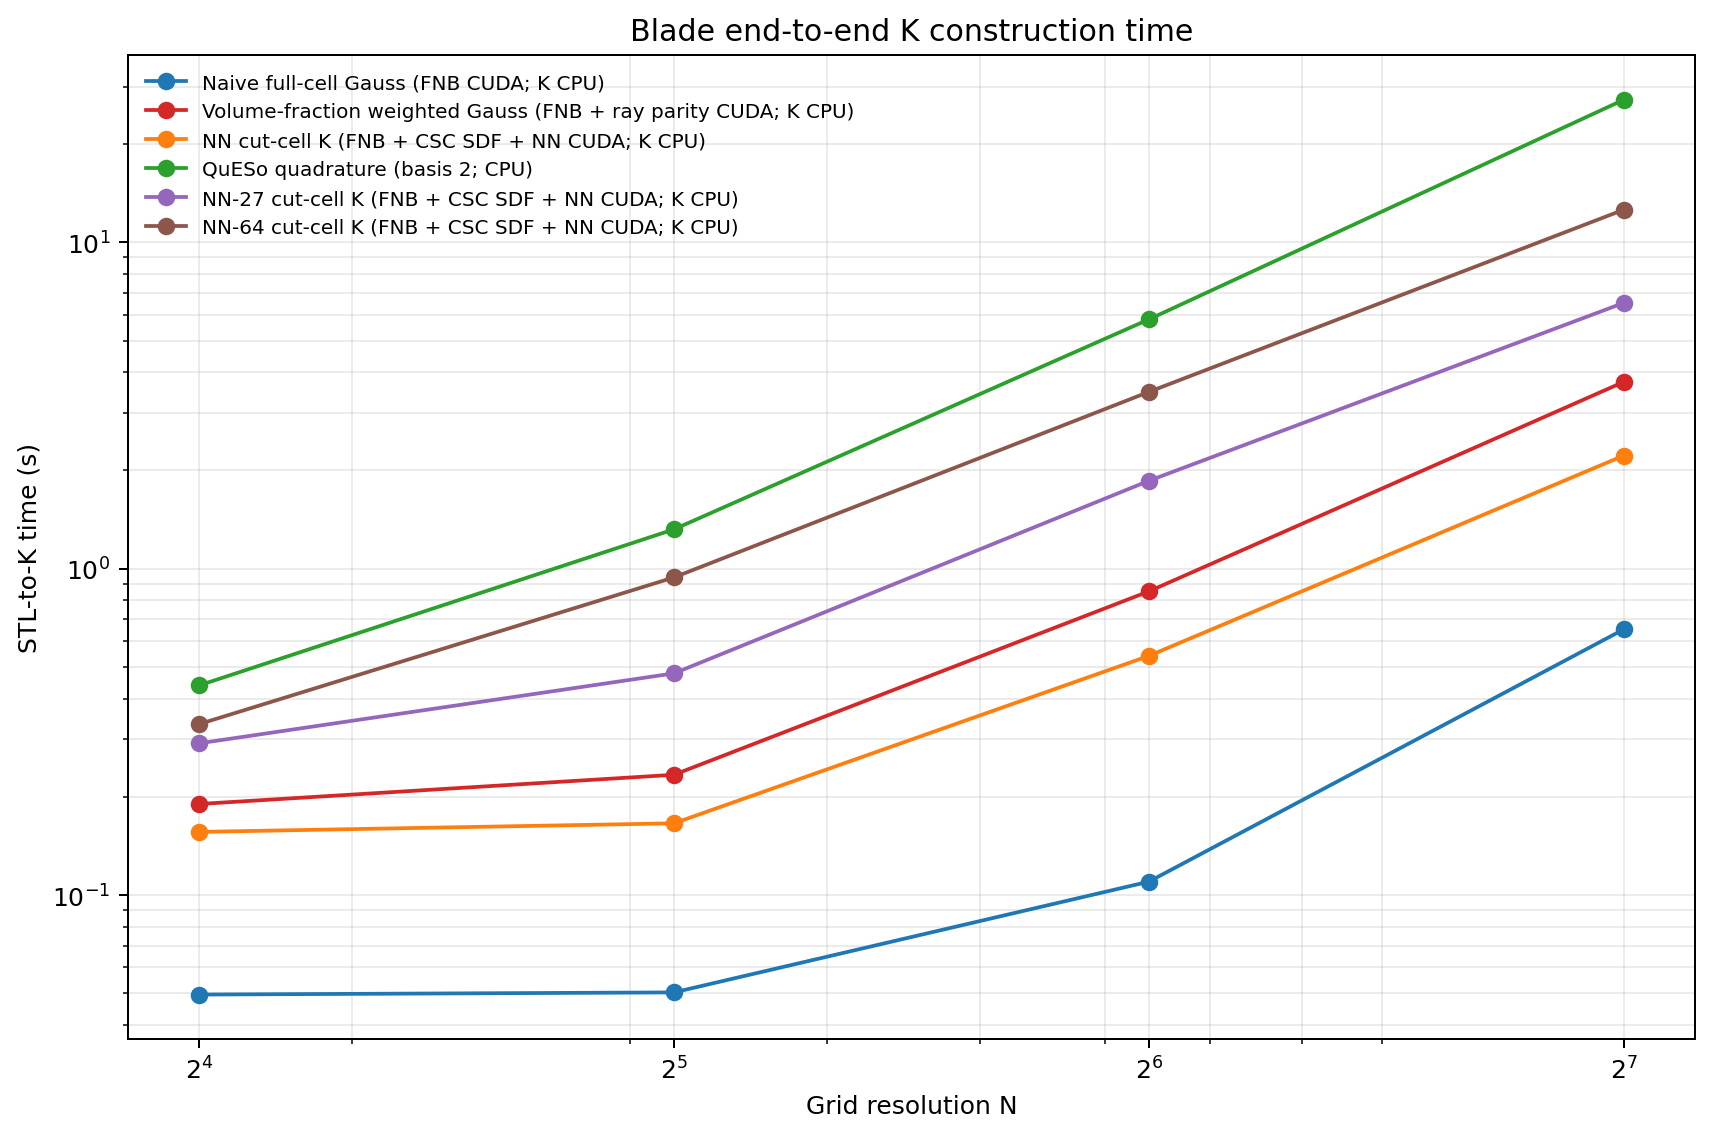

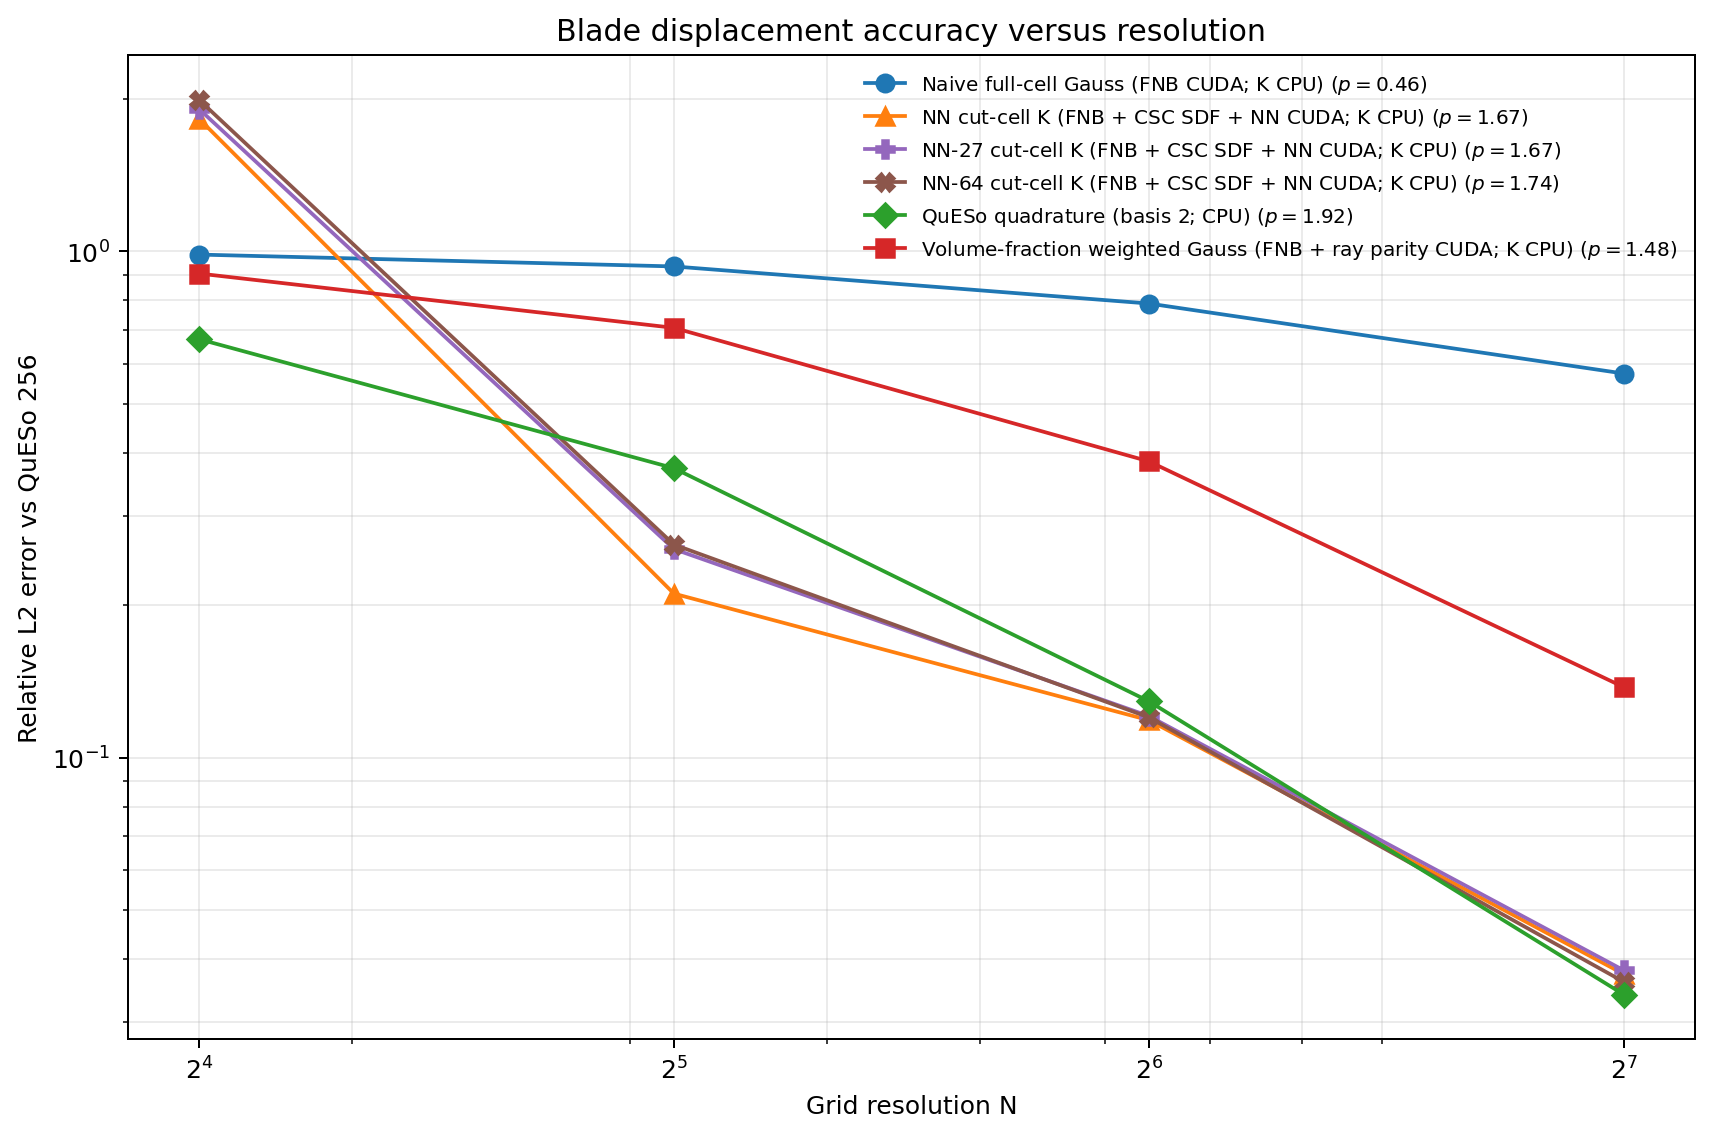

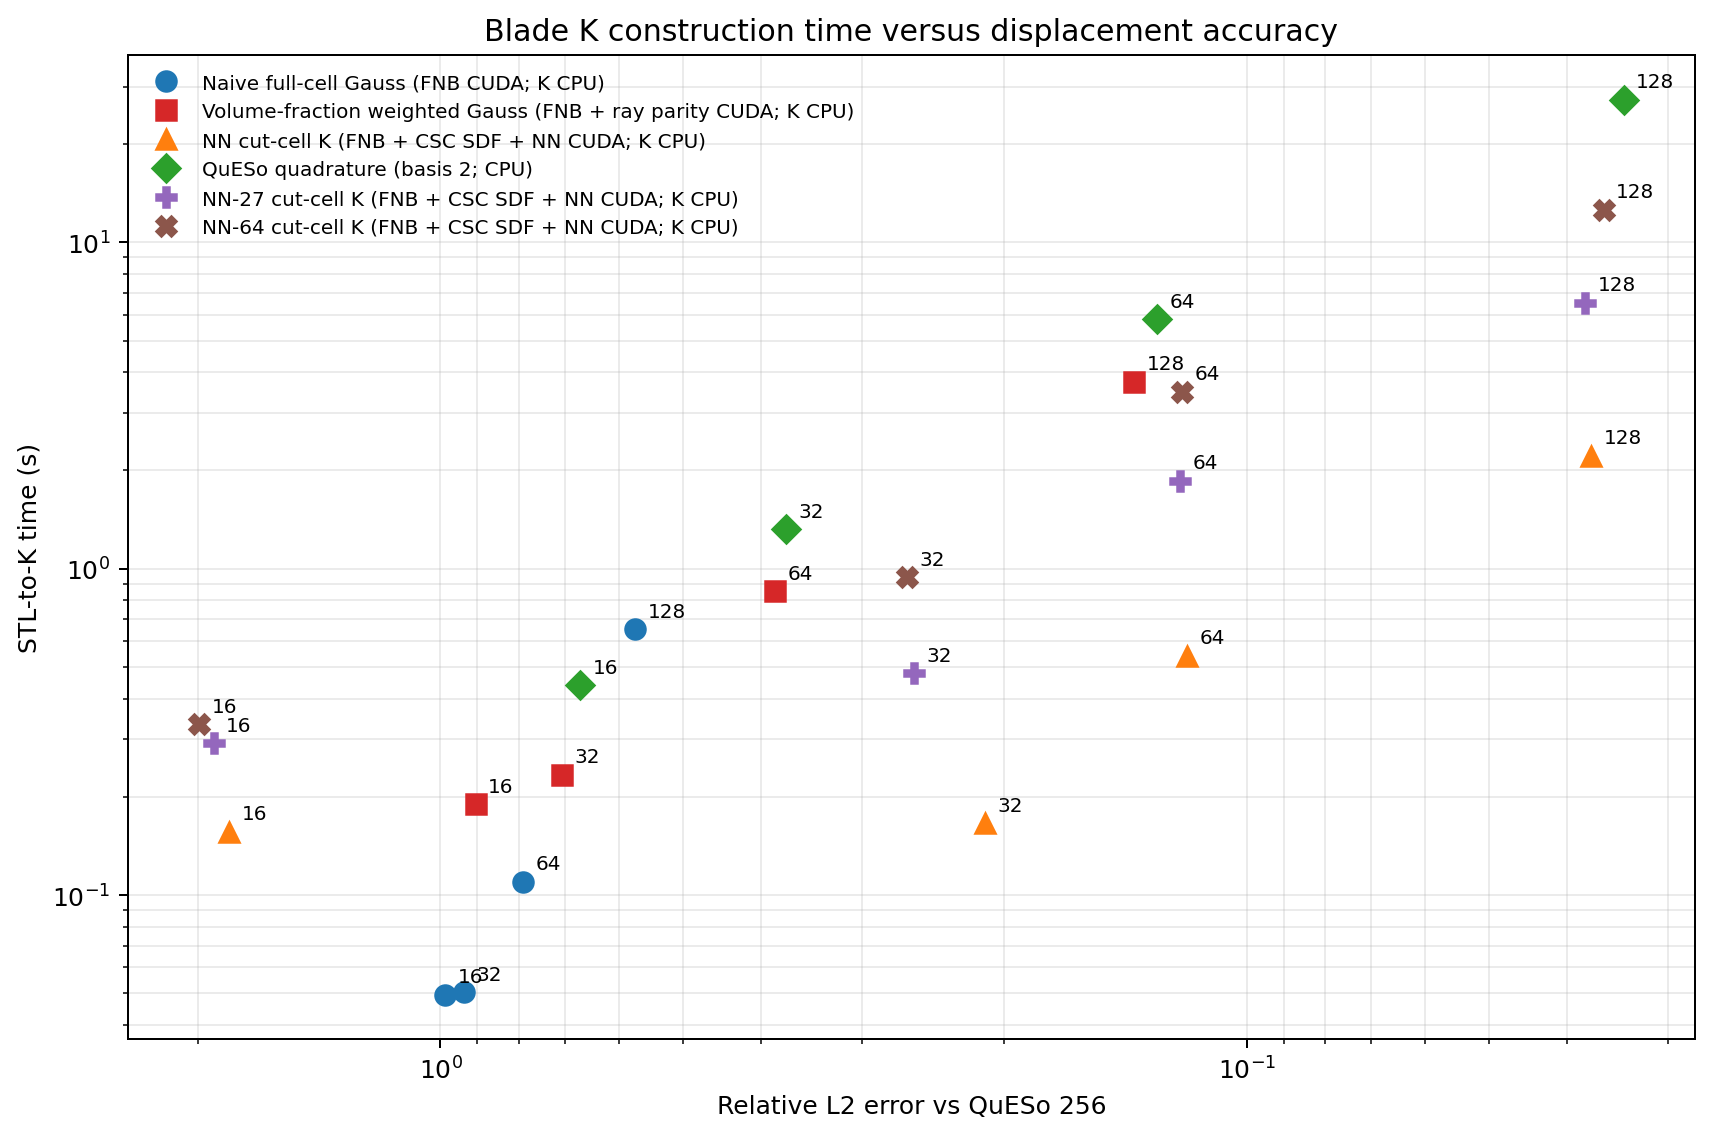

Displayed completed Blade figures from: c:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\studies\blade_rich_sdf_completed_figures


In [3]:
# Display the completed NN-27/NN-64 Blade figures in this notebook.
# This cell only reads the saved PNGs; it does not contact AWS or start a solver.
from pathlib import Path

from IPython.display import Image, display

ROOT = next(candidate for candidate in (Path.cwd(), *Path.cwd().parents) if (candidate / "clean_simulation").is_dir())
PNG_DIR = ROOT / "clean_simulation" / "notebooks" / "studies" / "blade_rich_sdf_completed_figures"
PNG_FILES = (
    "blade_time_vs_resolution.png",
    "blade_accuracy_vs_resolution.png",
    "blade_time_vs_accuracy.png",
)
missing = [PNG_DIR / filename for filename in PNG_FILES if not (PNG_DIR / filename).is_file()]
if missing:
    raise FileNotFoundError("The completed Blade figures are missing:\n" + "\n".join(map(str, missing)))

for filename in PNG_FILES:
    display(Image(filename=str(PNG_DIR / filename)))
print(f"Displayed completed Blade figures from: {PNG_DIR}")

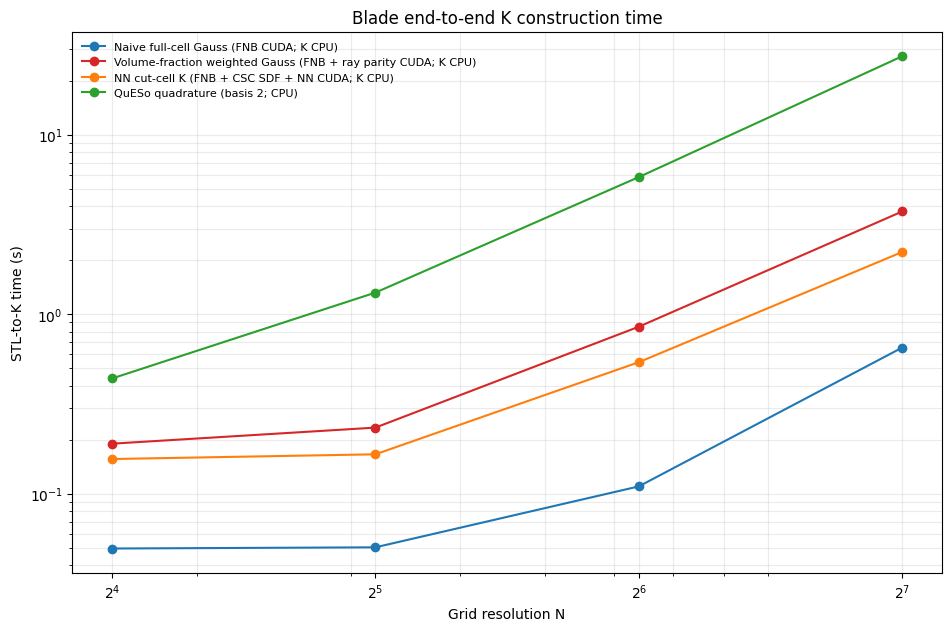

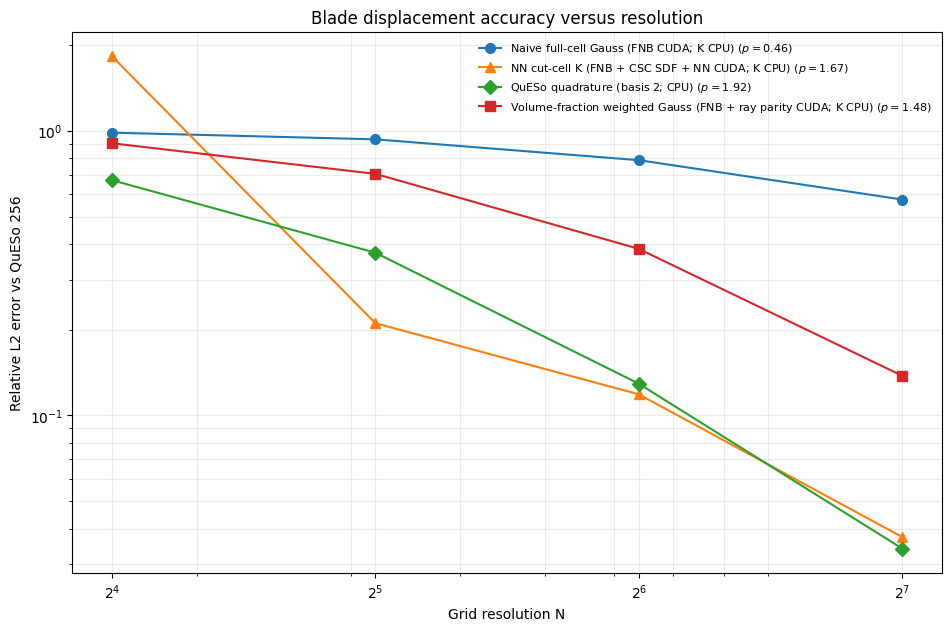

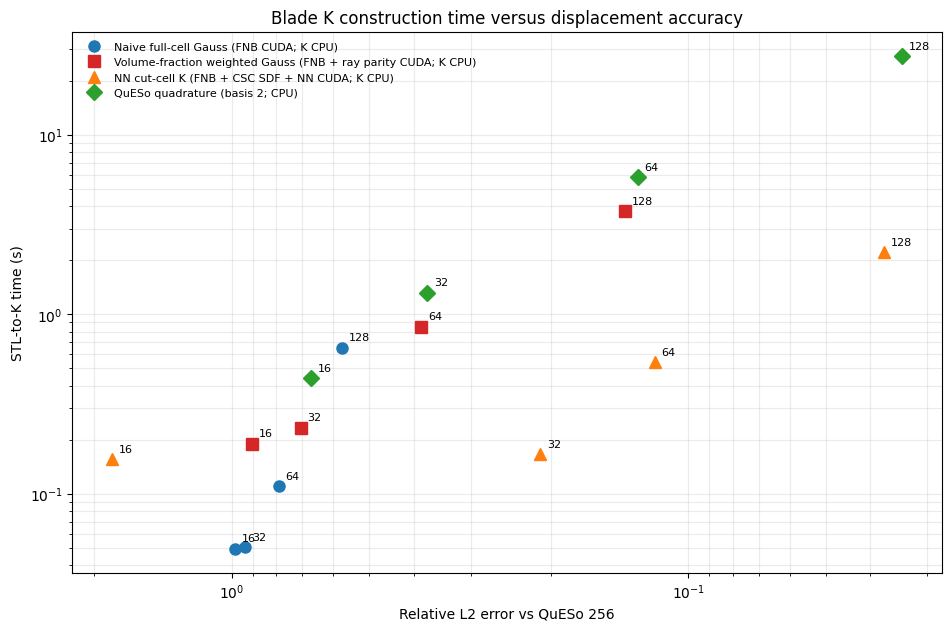

,variant,resolution,stl_load_seconds,grid_geometry_setup_seconds,fnb_total_seconds,fnb_candidate_generation_seconds,fnb_intersection_seconds,fnb_flood_fill_seconds,weighted_volume_fraction_seconds,nn_sdf_seconds,...,full_ke_broadcast_seconds,k_representation_assembly_seconds,end_to_end_k_seconds,unattributed_seconds,active_cells,cut_cells,weighted_samples_per_axis,nn_global_watertight_sign,queso_basis_order,nn_inference_device
0,naive_fnb,16,0.007070,0.000263,0.039790,0.029381,0.009513,0.000188,0.000000,0.000000,...,0.000408,0.000749,0.049554,0.000849,352,340,0,False,0,not_applicable
2,nn_fnb,16,0.006710,0.000320,0.036246,0.029466,0.005814,0.000225,0.000000,0.099715,...,0.000234,0.002097,0.156144,0.000869,352,340,0,True,0,cuda
3,queso_p2,16,0.006296,0.000303,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.438723,0.001015,335,323,0,False,2,not_applicable
1,weighted_fnb,16,0.006442,0.000255,0.040934,0.031183,0.008854,0.000177,0.140546,0.000000,...,0.000220,0.000724,0.190094,0.000810,352,340,4,False,0,not_applicable
5,naive_fnb,32,0.006214,0.000352,0.038678,0.032124,0.005000,0.000826,0.000000,0.000000,...,0.000511,0.003566,0.050311,0.000856,1759,1490,0,False,0,not_applicable
7,nn_fnb,32,0.006613,0.000320,0.039842,0.032496,0.005786,0.000834,0.000000,0.096635,...,0.000417,0.002338,0.165877,0.000853,1759,1490,0,True,0,cuda
8,queso_p2,32,0.006268,0.000330,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.319836,0.004677,1685,1416,0,False,2,not_applicable
6,weighted_fnb,32,0.006228,0.000395,0.044142,0.032446,0.009956,0.000997,0.177262,0.000000,...,0.000538,0.004109,0.233626,0.000867,1759,1490,4,False,0,not_applicable
10,naive_fnb,64,0.006632,0.001762,0.054435,0.035463,0.011381,0.006582,0.000000,0.000000,...,0.005343,0.040149,0.109898,0.001580,10400,6579,0,False,0,not_applicable
12,nn_fnb,64,0.006365,0.001641,0.054076,0.035589,0.011196,0.006441,0.000000,0.378764,...,0.006235,0.041150,0.540500,0.001315,10400,6579,0,True,0,cuda


,variant,resolution,stl_load_seconds,grid_geometry_setup_seconds,fnb_total_seconds,fnb_candidate_generation_seconds,fnb_intersection_seconds,fnb_flood_fill_seconds,weighted_volume_fraction_seconds,nn_sdf_seconds,...,end_to_end_k_seconds,unattributed_seconds,active_cells,cut_cells,weighted_samples_per_axis,nn_global_watertight_sign,queso_basis_order,nn_inference_device,framework,relative_l2_error
0,naive_fnb,16,0.007070,0.000263,0.039790,0.029381,0.009513,0.000188,0.000000,0.000000,...,0.049554,0.000849,352,340,0,False,0,not_applicable,naive,0.985832
4,naive_fnb,32,0.006214,0.000352,0.038678,0.032124,0.005000,0.000826,0.000000,0.000000,...,0.050311,0.000856,1759,1490,0,False,0,not_applicable,naive,0.934056
8,naive_fnb,64,0.006632,0.001762,0.054435,0.035463,0.011381,0.006582,0.000000,0.000000,...,0.109898,0.001580,10400,6579,0,False,0,not_applicable,naive,0.789067
12,naive_fnb,128,0.006855,0.020706,0.139746,0.054149,0.031122,0.052550,0.000000,0.000000,...,0.651857,0.004215,69063,26911,0,False,0,not_applicable,naive,0.573880
2,nn_fnb,16,0.006710,0.000320,0.036246,0.029466,0.005814,0.000225,0.000000,0.099715,...,0.156144,0.000869,352,340,0,True,0,cuda,nn,1.829176
6,nn_fnb,32,0.006613,0.000320,0.039842,0.032496,0.005786,0.000834,0.000000,0.096635,...,0.165877,0.000853,1759,1490,0,True,0,cuda,nn,0.210912
10,nn_fnb,64,0.006365,0.001641,0.054076,0.035589,0.011196,0.006441,0.000000,0.378764,...,0.540500,0.001315,10400,6579,0,True,0,cuda,nn,0.118611
14,nn_fnb,128,0.006502,0.012814,0.141051,0.053381,0.033256,0.052602,0.000000,1.300542,...,2.221201,0.008388,69063,26911,0,True,0,cuda,nn,0.037372
3,queso_p2,16,0.006296,0.000303,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.438723,0.001015,335,323,0,False,2,not_applicable,queso,0.671097
7,queso_p2,32,0.006268,0.000330,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.319836,0.004677,1685,1416,0,False,2,not_applicable,queso,0.373133


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter, FixedLocator, NullFormatter

_root_candidates = (Path.cwd(), *Path.cwd().parents)
_configured_root = globals().get("ROOT")
ROOT = (
    _configured_root
    if _configured_root is not None and (_configured_root / "clean_simulation").is_dir()
    else next(candidate for candidate in _root_candidates if (candidate / "clean_simulation").is_dir())
)
BLADE_FINAL_TIMING_DIR = ROOT / "clean_simulation" / "outputs" / "studies" / "blade" / "end_to_end_k_timing" / "aws_blade_end_to_end_k_timing_v6_cuda_fnb_warm"
BLADE_FINAL_TIMING_CSV = BLADE_FINAL_TIMING_DIR / "blade_end_to_end_k_timing.csv"
BLADE_RETAINED_ERROR_CSV = ROOT / "clean_simulation" / "notebooks" / "aws_blade_convergence_v2" / "blade_displacement_l2_vs_queso_256.csv"

METHOD_LABELS = {
    "naive_fnb": "Naive full-cell Gauss (FNB CUDA; K CPU)",
    "weighted_fnb": "Volume-fraction weighted Gauss (FNB + ray parity CUDA; K CPU)",
    "nn_fnb": "NN cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "queso_p2": "QuESo quadrature (basis 2; CPU)",
}
METHOD_COLORS = {
    "naive_fnb": "#1f77b4",
    "weighted_fnb": "#d62728",
    "nn_fnb": "#ff7f0e",
    "queso_p2": "#2ca02c",
}
METHOD_MARKERS = {
    "naive_fnb": "o",
    "weighted_fnb": "s",
    "nn_fnb": "^",
    "queso_p2": "D",
}
ERROR_FRAMEWORKS = {
    "naive_fnb": "naive",
    "weighted_fnb": "weighted",
    "nn_fnb": "nn",
    "queso_p2": "queso",
}

blade_final_timing = pd.read_csv(BLADE_FINAL_TIMING_CSV)
blade_final_timing = blade_final_timing[blade_final_timing["variant"].isin(METHOD_LABELS)].copy()
blade_final_timing["resolution"] = blade_final_timing["resolution"].astype(int)
retained_errors = pd.read_csv(BLADE_RETAINED_ERROR_CSV)
accuracy_variants = pd.DataFrame({
    "variant": list(ERROR_FRAMEWORKS),
    "framework": list(ERROR_FRAMEWORKS.values()),
})
accuracy_by_resolution = retained_errors.merge(
    accuracy_variants, on="framework", how="inner", validate="many_to_one"
)

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in blade_final_timing.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    axis.loglog(
        curve["resolution"], curve["end_to_end_k_seconds"], "o-",
        color=METHOD_COLORS[variant], label=METHOD_LABELS[variant],
    )
axis.set(
    xlabel="Grid resolution N",
    ylabel="STL-to-K time (s)",
    title="Blade end-to-end K construction time",
)
axis.xaxis.set_major_locator(FixedLocator([16, 32, 64, 128]))
axis.xaxis.set_major_formatter(FixedFormatter([r"$2^4$", r"$2^5$", r"$2^6$", r"$2^7$"]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
plt.show()

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in accuracy_by_resolution.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    previous, final = curve.iloc[-2], curve.iloc[-1]
    observed_order = np.log(previous["relative_l2_error"] / final["relative_l2_error"]) / np.log(
        final["resolution"] / previous["resolution"]
    )
    axis.loglog(
        curve["resolution"], curve["relative_l2_error"],
        linestyle="-", marker=METHOD_MARKERS[variant], markersize=7,
        color=METHOD_COLORS[variant],
        label=fr"{METHOD_LABELS[variant]} ($p={observed_order:.2f}$)",
    )
axis.set(
    xlabel="Grid resolution N",
    ylabel="Relative L2 error vs QuESo 256",
    title="Blade displacement accuracy versus resolution",
)
accuracy_resolutions = sorted(accuracy_by_resolution["resolution"].unique())
axis.xaxis.set_major_locator(FixedLocator(accuracy_resolutions))
axis.xaxis.set_major_formatter(FixedFormatter([fr"$2^{{{int(value).bit_length() - 1}}}$" for value in accuracy_resolutions]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
plt.show()

blade_time_accuracy = blade_final_timing.copy()
blade_time_accuracy["framework"] = blade_time_accuracy["variant"].map(ERROR_FRAMEWORKS)
blade_time_accuracy = blade_time_accuracy.merge(
    retained_errors[["framework", "resolution", "relative_l2_error"]],
    on=["framework", "resolution"], how="inner", validate="one_to_one",
)

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in blade_time_accuracy.groupby("variant", sort=False):
    curve = curve.sort_values("relative_l2_error", ascending=False)
    axis.loglog(
        curve["relative_l2_error"], curve["end_to_end_k_seconds"],
        linestyle="None", marker=METHOD_MARKERS[variant], markersize=8,
        color=METHOD_COLORS[variant], label=METHOD_LABELS[variant],
    )
    for point in curve.itertuples(index=False):
        axis.annotate(
            f"{point.resolution}",
            (point.relative_l2_error, point.end_to_end_k_seconds),
            xytext=(5, 5), textcoords="offset points", fontsize=8,
        )
axis.invert_xaxis()
axis.set(
    xlabel="Relative L2 error vs QuESo 256",
    ylabel="STL-to-K time (s)",
    title="Blade K construction time versus displacement accuracy",
)
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
plt.show()

display(blade_final_timing.sort_values(["resolution", "variant"]))
display(blade_time_accuracy.sort_values(["variant", "resolution"]))

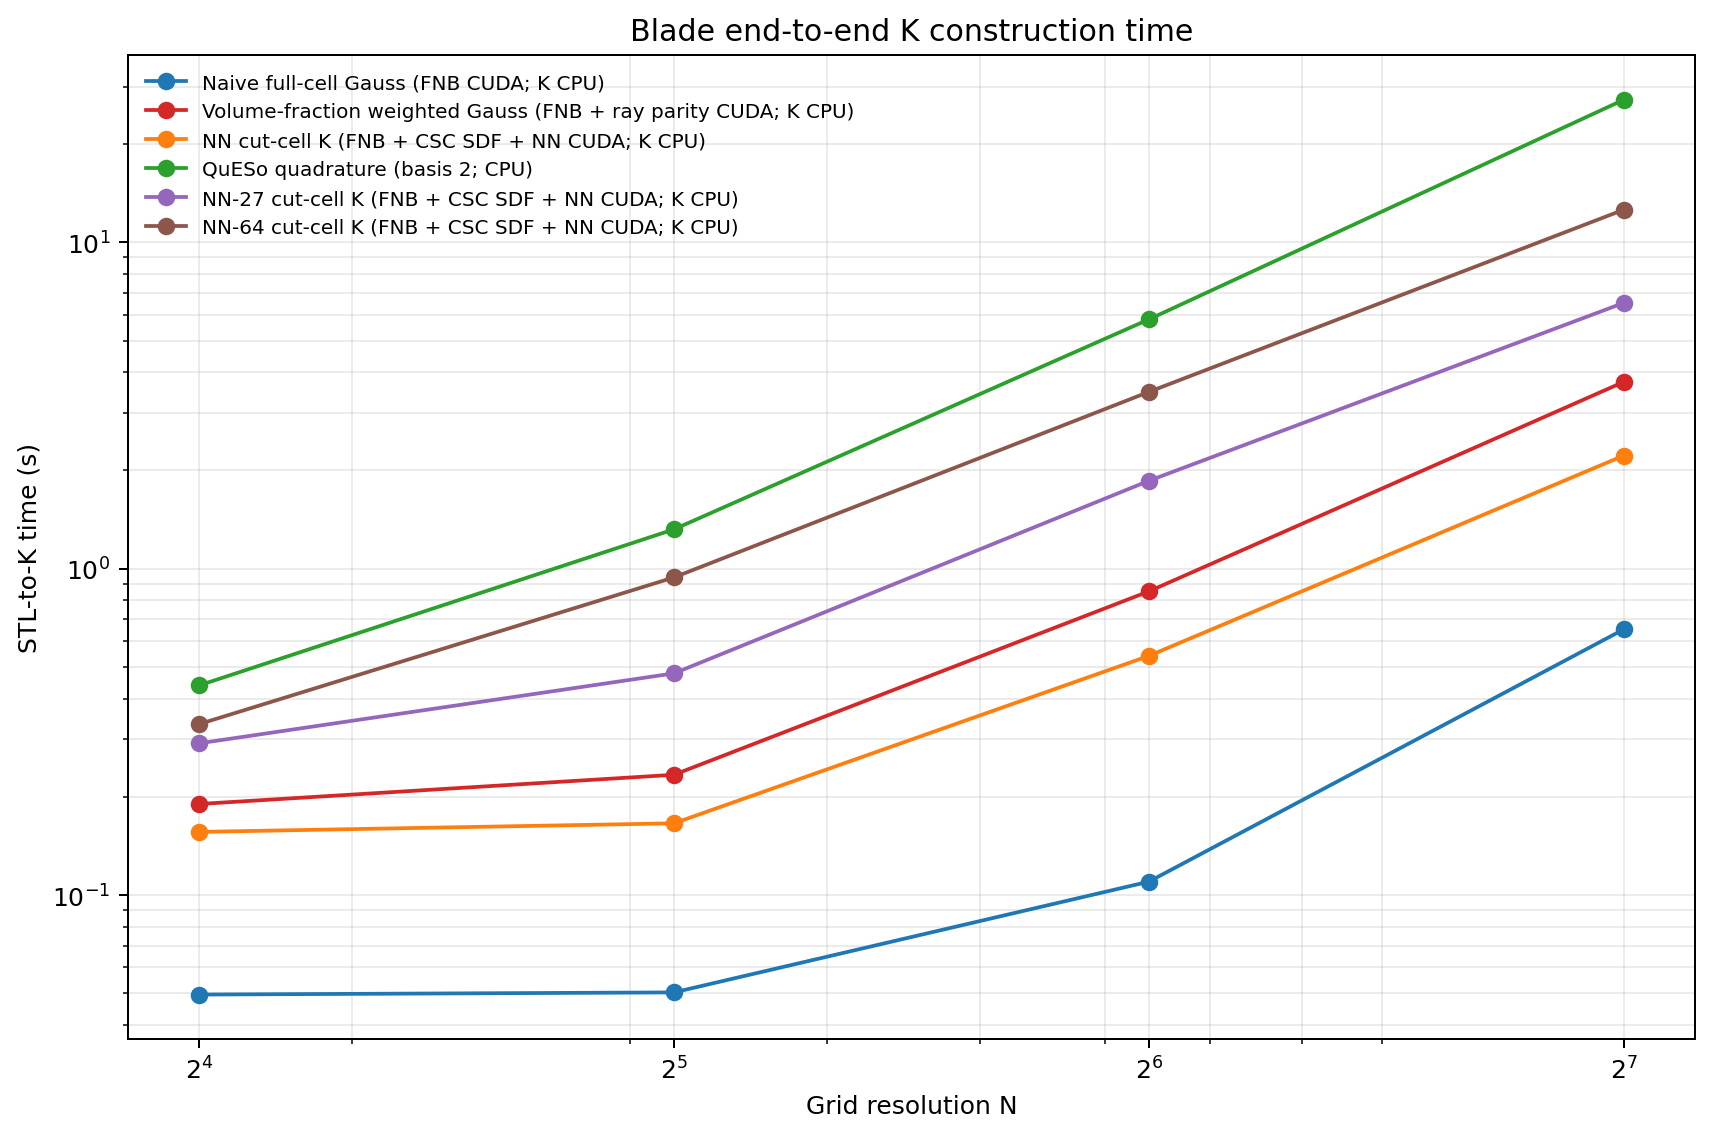

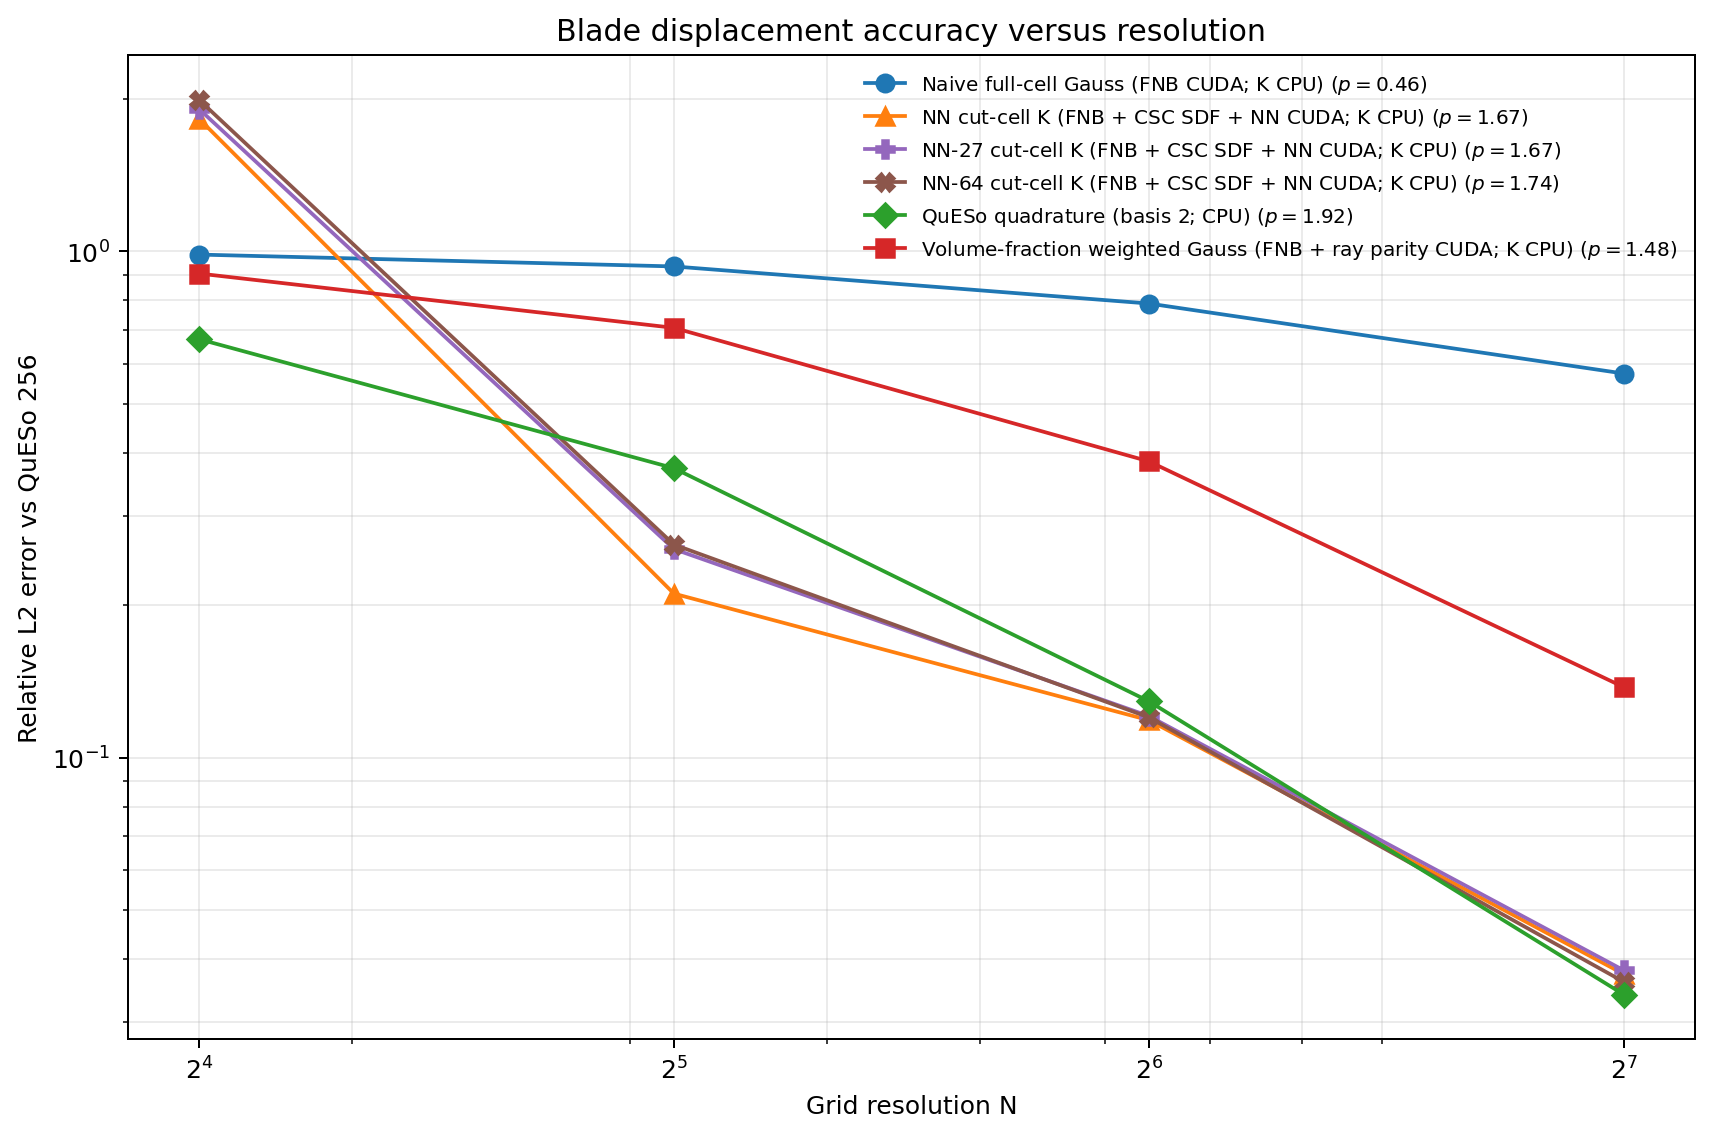

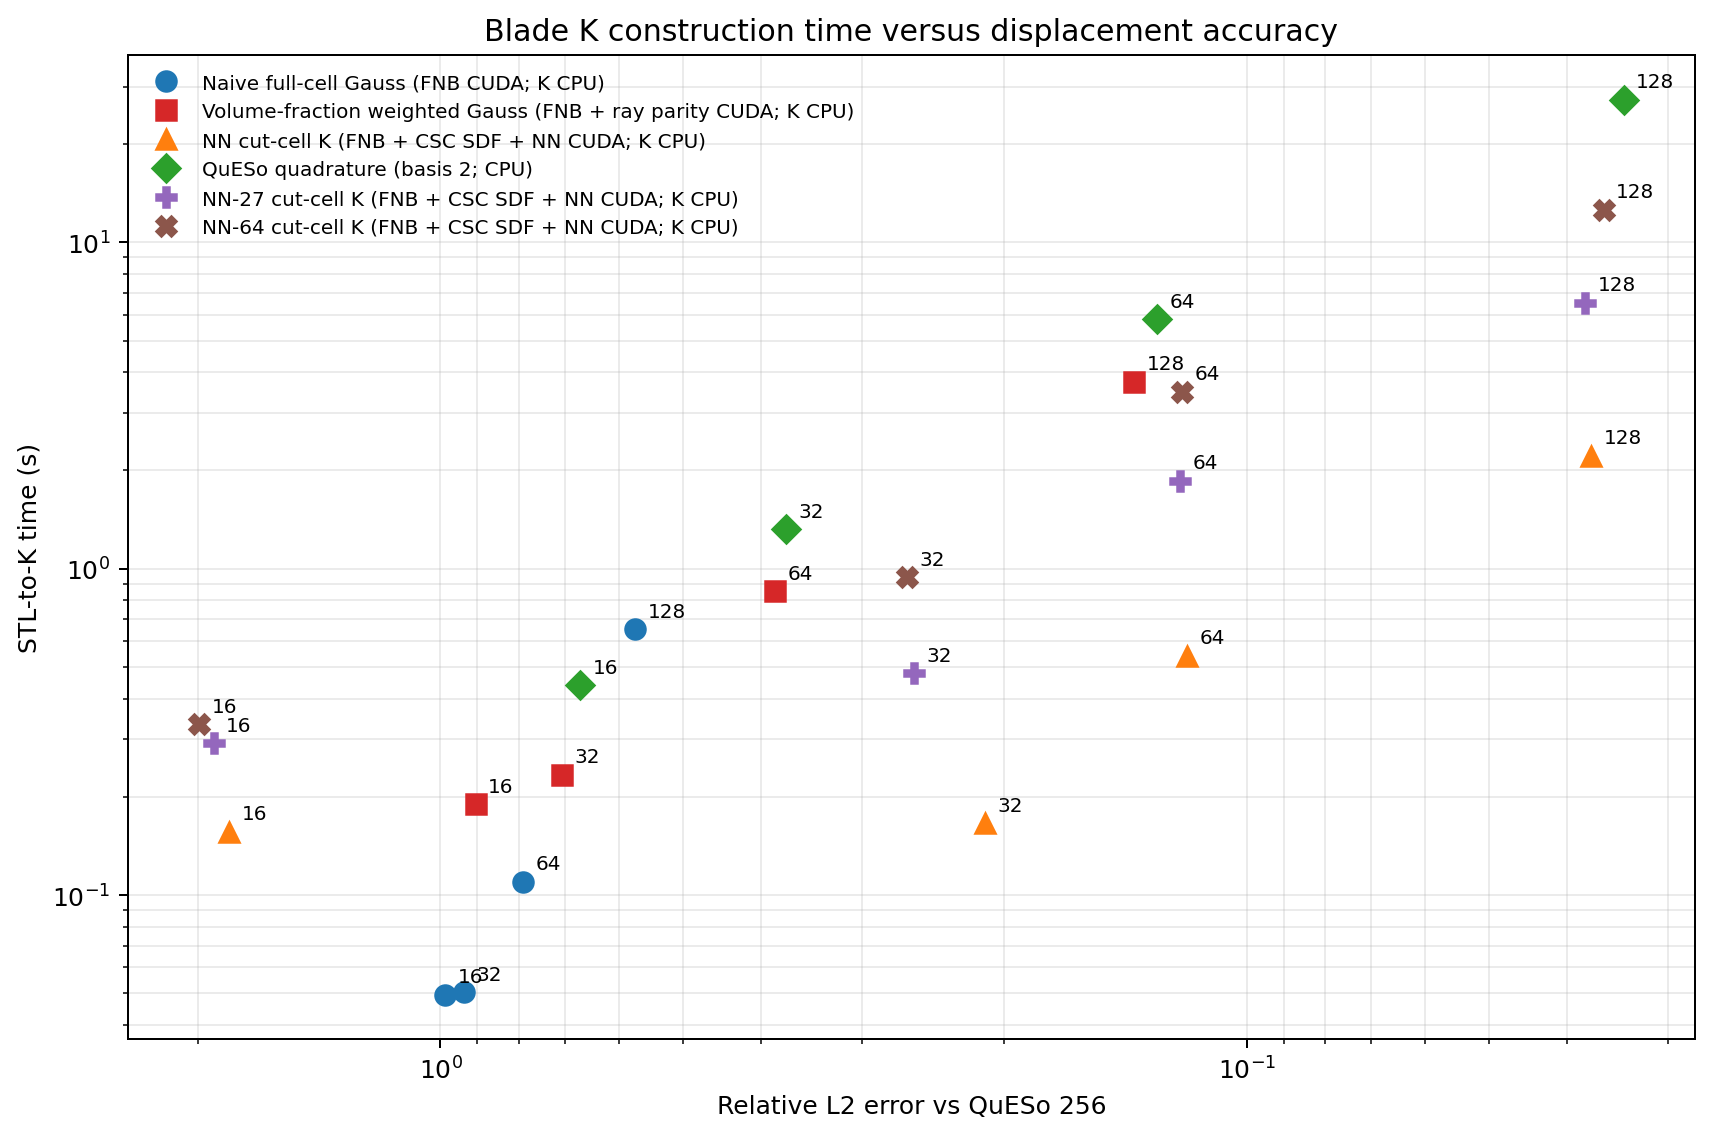

Saved and displayed three figures: c:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\studies\blade_rich_sdf_completed_figures


In [2]:
# Render the completed NN-27/NN-64 Blade figures in this notebook and preserve their PNG files.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import FixedFormatter, FixedLocator, NullFormatter

ROOT = next(candidate for candidate in (Path.cwd(), *Path.cwd().parents) if (candidate / "clean_simulation").is_dir())
LEGACY_TIMING_CSV = ROOT / "clean_simulation" / "outputs" / "studies" / "blade" / "end_to_end_k_timing" / "aws_blade_end_to_end_k_timing_v6_cuda_fnb_warm" / "blade_end_to_end_k_timing.csv"
RICH_TIMING_CSV = ROOT / "clean_simulation" / "outputs" / "aws_blade_end_to_end_k_timing_v7_nn27_nn64" / "blade_end_to_end_k_timing.csv"
ERROR_CSV = ROOT / "clean_simulation" / "notebooks" / "aws_blade_convergence_v2" / "blade_displacement_l2_vs_queso_256.csv"
PNG_DIR = ROOT / "clean_simulation" / "notebooks" / "studies" / "blade_rich_sdf_completed_figures"

missing = [path for path in (LEGACY_TIMING_CSV, RICH_TIMING_CSV, ERROR_CSV) if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing completed Blade data:\n" + "\n".join(map(str, missing)))
PNG_DIR.mkdir(parents=True, exist_ok=True)

labels = {
    "naive_fnb": "Naive full-cell Gauss (FNB CUDA; K CPU)",
    "weighted_fnb": "Volume-fraction weighted Gauss (FNB + ray parity CUDA; K CPU)",
    "nn_fnb": "NN cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "nn_27_fnb": "NN-27 cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "nn_64_fnb": "NN-64 cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "queso_p2": "QuESo quadrature (basis 2; CPU)",
}
colors = {"naive_fnb": "#1f77b4", "weighted_fnb": "#d62728", "nn_fnb": "#ff7f0e", "nn_27_fnb": "#9467bd", "nn_64_fnb": "#8c564b", "queso_p2": "#2ca02c"}
markers = {"naive_fnb": "o", "weighted_fnb": "s", "nn_fnb": "^", "nn_27_fnb": "P", "nn_64_fnb": "X", "queso_p2": "D"}
error_frameworks = {"naive_fnb": "naive", "weighted_fnb": "weighted", "nn_fnb": "nn", "nn_27_fnb": "nn_27", "nn_64_fnb": "nn_64", "queso_p2": "queso"}

timing = pd.concat((pd.read_csv(LEGACY_TIMING_CSV), pd.read_csv(RICH_TIMING_CSV)), ignore_index=True)
timing = timing[timing.variant.isin(labels)].copy()
timing.resolution = timing.resolution.astype(int)
if timing.duplicated(["variant", "resolution"]).any():
    raise ValueError("Combined timing input has duplicate method-resolution rows.")
errors = pd.read_csv(ERROR_CSV)
accuracy = errors.merge(pd.DataFrame({"variant": list(error_frameworks), "framework": list(error_frameworks.values())}), on="framework", how="inner", validate="many_to_one")
time_accuracy = timing.assign(framework=timing.variant.map(error_frameworks)).merge(errors[["framework", "resolution", "relative_l2_error"]], on=["framework", "resolution"], how="inner", validate="one_to_one")


def finish_figure(filename: str) -> None:
    figure.savefig(PNG_DIR / filename, dpi=180, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(PNG_DIR / filename)))


figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in timing.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    axis.loglog(curve.resolution, curve.end_to_end_k_seconds, "o-", color=colors[variant], label=labels[variant])
axis.set(xlabel="Grid resolution N", ylabel="STL-to-K time (s)", title="Blade end-to-end K construction time")
axis.xaxis.set_major_locator(FixedLocator([16, 32, 64, 128]))
axis.xaxis.set_major_formatter(FixedFormatter([r"$2^4$", r"$2^5$", r"$2^6$", r"$2^7$"]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
finish_figure("blade_time_vs_resolution.png")

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in accuracy.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    previous, final = curve.iloc[-2], curve.iloc[-1]
    order = np.log(previous.relative_l2_error / final.relative_l2_error) / np.log(final.resolution / previous.resolution)
    axis.loglog(curve.resolution, curve.relative_l2_error, linestyle="-", marker=markers[variant], markersize=7, color=colors[variant], label=fr"{labels[variant]} ($p={order:.2f}$)")
axis.set(xlabel="Grid resolution N", ylabel="Relative L2 error vs QuESo 256", title="Blade displacement accuracy versus resolution")
axis.xaxis.set_major_locator(FixedLocator([16, 32, 64, 128]))
axis.xaxis.set_major_formatter(FixedFormatter([r"$2^4$", r"$2^5$", r"$2^6$", r"$2^7$"]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
finish_figure("blade_accuracy_vs_resolution.png")

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in time_accuracy.groupby("variant", sort=False):
    curve = curve.sort_values("relative_l2_error", ascending=False)
    axis.loglog(curve.relative_l2_error, curve.end_to_end_k_seconds, linestyle="None", marker=markers[variant], markersize=8, color=colors[variant], label=labels[variant])
    for point in curve.itertuples(index=False):
        axis.annotate(str(point.resolution), (point.relative_l2_error, point.end_to_end_k_seconds), xytext=(5, 5), textcoords="offset points", fontsize=8)
axis.invert_xaxis()
axis.set(xlabel="Relative L2 error vs QuESo 256", ylabel="STL-to-K time (s)", title="Blade K construction time versus displacement accuracy")
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
finish_figure("blade_time_vs_accuracy.png")

print(f"Saved and displayed three figures: {PNG_DIR}")

In [ ]:
# One-click rich-SDF Blade refresh: snapshots current AWS best models, reruns the full
# NN-27/NN-64 timing and solve study, evaluates against the retained QuESo-256 field,
# downloads the artifacts, and writes the three comparison figures locally.
from __future__ import annotations

import base64
import shutil
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FixedFormatter, FixedLocator, NullFormatter

ROOT = next(candidate for candidate in (Path.cwd(), *Path.cwd().parents) if (candidate / "clean_simulation").is_dir())
SSH_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
SSH_KEY = Path.home() / ".ssh" / "ibm_learning.pem"
if not SSH_KEY.is_file():
    raise FileNotFoundError(f"AWS SSH key not found: {SSH_KEY}")

# These are the two continuing rich-SDF training runs. Each invocation snapshots their
# best checkpoint before the timing and displacement jobs begin.
RICH_MODEL_SOURCES = {
    "nn_27": "transformer_w256_l8_sdf_8subcells_noegg_topologyx10_b4096_lr4e7_v11",
    "nn_64": "transformer_w256_l8_sdf_27subcells_noegg_topologyx10_b4096_lr8e7_v11",
}
REFRESH_TAG = f"blade_rich_sdf_refresh_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}"
LOCAL_REFRESH_DIR = ROOT / "clean_simulation" / "notebooks" / "studies" / REFRESH_TAG
REMOTE_REPO = "/home/ubuntu/cutcell-training"
REMOTE_REFRESH_DIR = f"{REMOTE_REPO}/clean_simulation/outputs/studies/blade/rich_sdf_refresh/{REFRESH_TAG}"
REMOTE_TIMING_DIR = f"{REMOTE_REFRESH_DIR}/timing"
REMOTE_CONVERGENCE_DIR = f"{REMOTE_REFRESH_DIR}/convergence"
REMOTE_REFERENCE_DIR = f"{REMOTE_REPO}/clean_simulation/outputs/aws_blade_convergence_v2"

ssh_options = [
    "-o", "BatchMode=yes", "-o", "ConnectTimeout=20",
    "-o", "UserKnownHostsFile=NUL", "-o", "StrictHostKeyChecking=no",
    "-i", str(SSH_KEY),
]


def run_aws_script(script: str, timeout: int) -> None:
    encoded = base64.b64encode(script.encode("utf-8")).decode("ascii")
    result = subprocess.run(
        ["ssh", *ssh_options, SSH_HOST, f"echo {encoded} | base64 -d | bash"],
        stdin=subprocess.DEVNULL,
        text=True,
        timeout=timeout,
    )
    if result.returncode:
        raise RuntimeError(f"AWS pipeline failed with exit code {result.returncode}.")


# Deploy the current compatible runners before starting. The two training processes do
# not import these files, so this does not disturb their running state.
for script_name in (
    "run_blade_end_to_end_k_timing_v4.py",
    "run_blade_displacement_convergence.py",
    "evaluate_blade_displacement_convergence.py",
):
    subprocess.run(
        [
            "scp", *ssh_options,
            str(ROOT / "clean_simulation" / "scripts" / script_name),
            f"{SSH_HOST}:{REMOTE_REPO}/clean_simulation/scripts/{script_name}",
        ],
        check=True,
        stdin=subprocess.DEVNULL,
        timeout=300,
    )

source_27 = RICH_MODEL_SOURCES["nn_27"]
source_64 = RICH_MODEL_SOURCES["nn_64"]
remote_script = f'''set -euo pipefail
REPO={REMOTE_REPO}
REFRESH={REMOTE_REFRESH_DIR}
TIMING={REMOTE_TIMING_DIR}
CONVERGENCE={REMOTE_CONVERGENCE_DIR}
REFERENCE={REMOTE_REFERENCE_DIR}
mkdir -p "$REFRESH/checkpoints" "$TIMING" "$CONVERGENCE"

snapshot_checkpoint() {{
    source="$1"
    target="$2"
    expected_nodes="$3"
    for attempt in 1 2 3 4 5; do
        temporary="$target.tmp.$$"
        rm -f "$temporary"
        cp "$source" "$temporary"
        if "$REPO/.venv/bin/python" - "$temporary" "$expected_nodes" <<'PY'
import sys
import torch
path, expected_nodes = sys.argv[1], int(sys.argv[2])
checkpoint = torch.load(path, map_location="cpu", weights_only=False)
state = checkpoint["model_state_dict"]
if int(state["pos_embed"].shape[0]) != expected_nodes:
    raise RuntimeError("unexpected SDF input width")
if not np.isfinite(float(checkpoint["val_loss"])):
    raise RuntimeError("checkpoint has a non-finite validation loss")
print(f"validated {{path}}: epoch={{checkpoint['epoch']}}, val_loss={{checkpoint['val_loss']:.8g}}")
PY
        then
            mv "$temporary" "$target"
            return 0
        fi
        rm -f "$temporary"
        sleep 2
    done
    echo "Could not obtain a valid point-in-time checkpoint snapshot: $source" >&2
    return 1
}}

# torch validation needs NumPy while retaining the no-live-checkpoint contract.
export PYTHONPATH="$REPO${{PYTHONPATH:+:$PYTHONPATH}}"
"$REPO/.venv/bin/python" -c 'import numpy as np' >/dev/null
snapshot_checkpoint "$REPO/clean_simulation/outputs/adaptive_training/{source_27}/stage_01_best.pt" "$REFRESH/checkpoints/nn_27_best.pt" 27
snapshot_checkpoint "$REPO/clean_simulation/outputs/adaptive_training/{source_64}/stage_01_best.pt" "$REFRESH/checkpoints/nn_64_best.pt" 64

# The runners load these aliases. The immutable per-refresh copies above remain the
# provenance record for this run.
mkdir -p "$REPO/clean_simulation/outputs/models/archive/checkpoints/aws_rich_sdf"
cp "$REFRESH/checkpoints/nn_27_best.pt" "$REPO/clean_simulation/outputs/models/archive/checkpoints/aws_rich_sdf/nn_27_best.pt"
cp "$REFRESH/checkpoints/nn_64_best.pt" "$REPO/clean_simulation/outputs/models/archive/checkpoints/aws_rich_sdf/nn_64_best.pt"

CUDA_VISIBLE_DEVICES=0 BLADE_E2E_K_TIMING_OUTPUT_DIR="$TIMING" BLADE_STL_PATH="$REFERENCE/Blade.stl" BLADE_RESOLUTIONS=16,32,64,128 BLADE_E2E_K_VARIANTS=nn_27_fnb,nn_64_fnb BLADE_DEVICE=cuda BLADE_FNB_BAND_CELLS=3 "$REPO/.venv/bin/python" "$REPO/clean_simulation/scripts/run_blade_end_to_end_k_timing_v4.py"
CUDA_VISIBLE_DEVICES=1 BLADE_CONVERGENCE_OUTPUT_DIR="$CONVERGENCE" BLADE_STL_PATH="$REFERENCE/Blade.stl" BLADE_RESOLUTIONS=16,32,64,128 BLADE_FRAMEWORKS=nn_27,nn_64 BLADE_DEVICE=cuda BLADE_CG_MAX_ITER=12000 "$REPO/.venv/bin/python" "$REPO/clean_simulation/scripts/run_blade_displacement_convergence.py"
CUDA_VISIBLE_DEVICES=1 BLADE_CONVERGENCE_OUTPUT_DIR="$CONVERGENCE" BLADE_REFERENCE_OUTPUT_DIR="$REFERENCE" BLADE_COARSE_OUTPUT_DIR="$CONVERGENCE" BLADE_EXTENDED_OUTPUT_DIR="$CONVERGENCE" BLADE_EXTENDED_MIN_RESOLUTION=999 BLADE_REFERENCE_RESOLUTION=256 BLADE_EVALUATION_RESOLUTIONS=16,32,64,128 BLADE_EVALUATION_DEVICE=cuda "$REPO/.venv/bin/python" "$REPO/clean_simulation/scripts/evaluate_blade_displacement_convergence.py"
'''

# Add NumPy to the checkpoint validation process without importing it into the shell.
remote_script = remote_script.replace("import sys\nimport torch", "import sys\nimport numpy as np\nimport torch")
print(f"Starting {REFRESH_TAG}. The cell waits for the full AWS timing and solve ladder.")
run_aws_script(remote_script, timeout=14_400)

LOCAL_REFRESH_DIR.mkdir(parents=True, exist_ok=False)
remote_artifacts = [
    f"{REMOTE_TIMING_DIR}/blade_end_to_end_k_timing.csv",
    f"{REMOTE_CONVERGENCE_DIR}/blade_displacement_l2_vs_queso_256.csv",
    f"{REMOTE_CONVERGENCE_DIR}/blade_displacement_l2_vs_queso_256_global_fits.csv",
    f"{REMOTE_CONVERGENCE_DIR}/blade_displacement_l2_vs_queso_256.png",
    f"{REMOTE_REFRESH_DIR}/checkpoints/nn_27_best.pt",
    f"{REMOTE_REFRESH_DIR}/checkpoints/nn_64_best.pt",
]
subprocess.run(
    ["scp", *ssh_options, *[f"{SSH_HOST}:{path}" for path in remote_artifacts], str(LOCAL_REFRESH_DIR)],
    check=True,
    stdin=subprocess.DEVNULL,
    timeout=1800,
)

legacy_timing = ROOT / "clean_simulation" / "outputs" / "studies" / "blade" / "end_to_end_k_timing" / "aws_blade_end_to_end_k_timing_v6_cuda_fnb_warm" / "blade_end_to_end_k_timing.csv"
rich_timing = LOCAL_REFRESH_DIR / "blade_end_to_end_k_timing.csv"
errors = LOCAL_REFRESH_DIR / "blade_displacement_l2_vs_queso_256.csv"
if not legacy_timing.is_file():
    raise FileNotFoundError(legacy_timing)

timing = pd.concat((pd.read_csv(legacy_timing), pd.read_csv(rich_timing)), ignore_index=True)
method_labels = {
    "naive_fnb": "Naive full-cell Gauss (FNB CUDA; K CPU)",
    "weighted_fnb": "Volume-fraction weighted Gauss (FNB + ray parity CUDA; K CPU)",
    "nn_fnb": "NN cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "nn_27_fnb": "NN-27 cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "nn_64_fnb": "NN-64 cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "queso_p2": "QuESo quadrature (basis 2; CPU)",
}
colors = {"naive_fnb": "#1f77b4", "weighted_fnb": "#d62728", "nn_fnb": "#ff7f0e", "nn_27_fnb": "#9467bd", "nn_64_fnb": "#8c564b", "queso_p2": "#2ca02c"}
markers = {"naive_fnb": "o", "weighted_fnb": "s", "nn_fnb": "^", "nn_27_fnb": "P", "nn_64_fnb": "X", "queso_p2": "D"}
frameworks = {"naive_fnb": "naive", "weighted_fnb": "weighted", "nn_fnb": "nn", "nn_27_fnb": "nn_27", "nn_64_fnb": "nn_64", "queso_p2": "queso"}
timing = timing[timing["variant"].isin(method_labels)].copy()
timing["resolution"] = timing["resolution"].astype(int)
if timing.duplicated(["variant", "resolution"]).any():
    raise ValueError("The combined timing tables contain duplicate method-resolution rows.")
error_table = pd.read_csv(errors)
accuracy = error_table.merge(pd.DataFrame({"variant": list(frameworks), "framework": list(frameworks.values())}), on="framework", how="inner", validate="many_to_one")
time_accuracy = timing.assign(framework=timing["variant"].map(frameworks)).merge(error_table[["framework", "resolution", "relative_l2_error"]], on=["framework", "resolution"], how="inner", validate="one_to_one")


def save_figure(name: str) -> None:
    path = LOCAL_REFRESH_DIR / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in timing.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    axis.loglog(curve["resolution"], curve["end_to_end_k_seconds"], "o-", color=colors[variant], label=method_labels[variant])
axis.set(xlabel="Grid resolution N", ylabel="STL-to-K time (s)", title="Blade end-to-end K construction time")
axis.xaxis.set_major_locator(FixedLocator([16, 32, 64, 128]))
axis.xaxis.set_major_formatter(FixedFormatter([r"$2^4$", r"$2^5$", r"$2^6$", r"$2^7$"]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
save_figure("blade_time_vs_resolution.png")

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in accuracy.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    previous, final = curve.iloc[-2], curve.iloc[-1]
    order = np.log(previous.relative_l2_error / final.relative_l2_error) / np.log(final.resolution / previous.resolution)
    axis.loglog(curve.resolution, curve.relative_l2_error, linestyle="-", marker=markers[variant], markersize=7, color=colors[variant], label=fr"{method_labels[variant]} ($p={order:.2f}$)")
axis.set(xlabel="Grid resolution N", ylabel="Relative L2 error vs QuESo 256", title="Blade displacement accuracy versus resolution")
axis.xaxis.set_major_locator(FixedLocator([16, 32, 64, 128]))
axis.xaxis.set_major_formatter(FixedFormatter([r"$2^4$", r"$2^5$", r"$2^6$", r"$2^7$"]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
save_figure("blade_accuracy_vs_resolution.png")

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in time_accuracy.groupby("variant", sort=False):
    curve = curve.sort_values("relative_l2_error", ascending=False)
    axis.loglog(curve.relative_l2_error, curve.end_to_end_k_seconds, linestyle="None", marker=markers[variant], markersize=8, color=colors[variant], label=method_labels[variant])
    for point in curve.itertuples(index=False):
        axis.annotate(str(point.resolution), (point.relative_l2_error, point.end_to_end_k_seconds), xytext=(5, 5), textcoords="offset points", fontsize=8)
axis.invert_xaxis()
axis.set(xlabel="Relative L2 error vs QuESo 256", ylabel="STL-to-K time (s)", title="Blade K construction time versus displacement accuracy")
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
save_figure("blade_time_vs_accuracy.png")

timing.to_csv(LOCAL_REFRESH_DIR / "combined_blade_end_to_end_k_timing.csv", index=False)
time_accuracy.to_csv(LOCAL_REFRESH_DIR / "blade_time_vs_accuracy.csv", index=False)
display(time_accuracy.sort_values(["variant", "resolution"]))
print(f"Refresh complete: {LOCAL_REFRESH_DIR}")

In [ ]:
# Run this cell for future refreshes. It applies the timing-runner directory correction
# to the preceding one-click pipeline, then executes the complete snapshot-to-graphs run.
import json
from pathlib import Path

PIPELINE_NOTEBOOK = Path("clean_simulation/notebooks/studies/aws_pilot_512_corrected.ipynb")
if not PIPELINE_NOTEBOOK.is_file():
    raise FileNotFoundError(PIPELINE_NOTEBOOK)

with PIPELINE_NOTEBOOK.open(encoding="utf-8") as stream:
    pipeline_notebook = json.load(stream)

pipeline_cell = next(
    cell for cell in pipeline_notebook["cells"]
    if cell.get("id") == "#VSC-b6830cca"
)
pipeline_source = "".join(pipeline_cell["source"])
old_setup = 'mkdir -p "$REFRESH/checkpoints" "$TIMING" "$CONVERGENCE"'
new_setup = 'mkdir -p "$REFRESH/checkpoints"'
if old_setup not in pipeline_source:
    raise RuntimeError("The refresh pipeline template has changed; update this execution cell before running it.")

# run_blade_end_to_end_k_timing_v4.py creates its own new output directory.
pipeline_source = pipeline_source.replace(old_setup, new_setup, 1)
exec(compile(pipeline_source, str(PIPELINE_NOTEBOOK), "exec"))

In [3]:
from pathlib import Path

import numpy as np
import plotly.graph_objects as go

blade_candidates = (
    Path.cwd() / "Blade.ast",
    Path.cwd() / "clean_simulation" / "notebooks" / "Blade.ast",
    Path("Blade.ast"),
)
blade_path = next((path for path in blade_candidates if path.is_file()), None)
if blade_path is None:
    raise FileNotFoundError("Could not find Blade.ast from the notebook working directory.")

vertex_rows = [
    line.split(maxsplit=1)[1]
    for line in blade_path.read_text(encoding="ascii").splitlines()
    if line.lstrip().startswith("vertex ")
]
vertices = np.array([np.fromstring(row, sep=" ") for row in vertex_rows])
triangles = vertices.reshape(-1, 3, 3)
triangle_starts = np.arange(len(triangles)) * 3
bounds = np.vstack((vertices.min(axis=0), vertices.max(axis=0)))

face_normals = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
face_normals /= np.linalg.vector_norm(face_normals, axis=1, keepdims=True)
vertical_orientation = face_normals[:, 2]

figure = go.Figure(
    go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=triangle_starts,
        j=triangle_starts + 1,
        k=triangle_starts + 2,
        intensity=vertical_orientation,
        intensitymode="cell",
        colorscale="RdBu",
        cmin=-1,
        cmax=1,
        colorbar=dict(title="Surface normal Z"),
        flatshading=True,
        hovertemplate="X: %{x:.3f}<br>Y: %{y:.3f}<br>Z: %{z:.3f}<extra></extra>",
    )
)
figure.update_layout(
    title=f"Blade mesh: {len(triangles):,} triangles",
    template="plotly_white",
    height=720,
    margin=dict(l=0, r=0, b=0, t=48),
    scene=dict(
        aspectmode="data",
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z",
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.9)),
    ),
)
figure.show(config={"scrollZoom": True, "displaylogo": False})

print(f"Loaded {blade_path.resolve()} with {len(triangles):,} triangles.")
print(f"Bounds: min={bounds[0]}, max={bounds[1]}")

Loaded C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\Blade.ast with 1,716 triangles.
Bounds: min=[268.766357 -40.951546 -33.968506], max=[395.164856  35.398396  44.031494]
